# NPC DSC 2026 — EDA + Retraining OOF dari Nol

Notebook ringkas ini membangun ulang file probabilitas yang hilang:

- ResNet50 dari awal
- EfficientNet-B2 dari awal
- ConvNeXt Tiny pretrained ImageNet lalu fine-tuning
- Bird-MAE pretrained sebagai embedding + Logistic Regression

Semua fold memakai `StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=16)` dengan `source_group` sebagai grup. Audio dan label untuk training berasal dari dataset kompetisi. ConvNeXt dan Bird-MAE memakai checkpoint pretrained eksternal; pastikan pemakaian pretrained sesuai aturan kompetisi dan dokumentasikan sumber model.

**Catatan:** model ResNet/EfficientNet/ConvNeXt di sini dilatih ulang dengan pipeline temporal-crop yang lebih sederhana supaya satu notebook bisa direproduksi. Skornya tidak dijamin identik dengan eksperimen lama. Perkiraan kerja: ekstraksi mel beberapa menit, ekstraksi Bird-MAE sekitar 10 menit, dan training model bisa memakan waktu cukup lama. Aktifkan GPU dan Internet di Kaggle.

## 1. Import dan konfigurasi

In [8]:
# Jalankan sebelum import model/pretrained Transformers.
%pip install -q "transformers==4.57.6"


Note: you may need to restart the kernel to use updated packages.


In [9]:
import os, sys, json, math, random, hashlib, warnings, subprocess, importlib.util
from pathlib import Path

# Hanya pasang timm jika belum tersedia; tidak mengubah huggingface-hub.
if importlib.util.find_spec("timm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.models import resnet50, efficientnet_b2
import timm

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 16
N_FOLDS = 4
SR = 32000
DURATION = 8.0
WINDOW = int(SR * DURATION)
N_FFT = 2048
HOP = 512
N_MELS = 128
FMIN = 100
FMAX = 14000
IMAGE_SIZE = 224
BATCH_SIZE = 12         # Jika CUDA OOM, ubah ke 8.
INFER_CROP_BATCH = 12
NUM_WORKERS = 2
PATIENCE = 3
EPOCHS = {"resnet50": 10, "efficientnet_b2": 10, "convnext_tiny": 12}
USE_AMP = torch.cuda.is_available()

ROOT = "/kaggle/input/competitions/schematics-2026"
TRAIN_META_PATH = os.path.join(ROOT, "train", "metadata.csv")
SAMPLE_PATH = os.path.join(ROOT, "sample_submission.csv")
TRAIN_AUDIO_DIR = os.path.join(ROOT, "train", "audio")
TEST_AUDIO_DIR = os.path.join(ROOT, "test", "audio")
OUT = "/kaggle/working"
CACHE_DIR = os.path.join(OUT, "npc_retrain_mel_cache")
MODEL_DIR = os.path.join(OUT, "npc_retrain_checkpoints")
os.makedirs(OUT, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
print("Device:", DEVICE)
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
print("AMP:", USE_AMP)

Device: cuda
GPU: Tesla T4
AMP: True


## 2. EDA inti + path audio + group folds

Train: (1826, 6) Test: (814, 2)
Kelas: ['Bondol Jawa', 'Cendrawasih', 'Kutilang']
Source group: 15
Missing values:
 file_id         0
audio_path      0
label           0
source_group    0
dtype: int64
Duplicate file_id: 0
Duplicate audio_path: 0


,jumlah,proporsi_pct
label,,
Bondol Jawa,1124,61.56
Kutilang,619,33.90
Cendrawasih,83,4.55


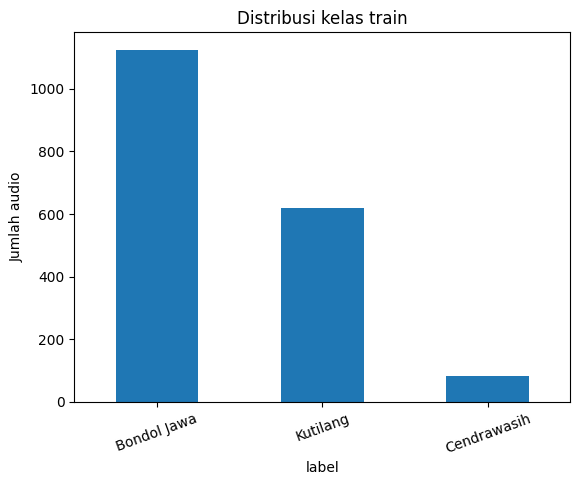

label,Bondol Jawa,Cendrawasih,Kutilang
fold,,,
0,117,35,132
1,314,3,178
2,394,16,143
3,299,29,166


Fold valid; tidak ada source_group leakage.


In [10]:
train_df = pd.read_csv(TRAIN_META_PATH).copy()
sample_sub = pd.read_csv(SAMPLE_PATH).copy()

required = {"file_id", "audio_path", "label", "source_group"}
assert required.issubset(train_df.columns), f"Kolom train kurang: {required - set(train_df.columns)}"
assert {"file_id", "label"}.issubset(sample_sub.columns), "Kolom sample_submission tidak sesuai"

for c in ["file_id", "audio_path", "label", "source_group"]:
    train_df[c] = train_df[c].astype(str)
sample_sub["file_id"] = sample_sub["file_id"].astype(str)
CLASS_NAMES = sorted(train_df["label"].unique().tolist())
LABEL_TO_IDX = {v:i for i,v in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
train_df["label_idx"] = train_df["label"].map(LABEL_TO_IDX).astype(int)
train_df["row_idx"] = np.arange(len(train_df), dtype=int)

print("Train:", train_df.shape, "Test:", sample_sub.shape)
print("Kelas:", CLASS_NAMES)
print("Source group:", train_df["source_group"].nunique())
print("Missing values:\n", train_df[["file_id","audio_path","label","source_group"]].isna().sum())
print("Duplicate file_id:", train_df["file_id"].duplicated().sum())
print("Duplicate audio_path:", train_df["audio_path"].duplicated().sum())
class_summary = train_df["label"].value_counts().rename("jumlah").to_frame()
class_summary["proporsi_pct"] = (train_df["label"].value_counts(normalize=True) * 100).round(2)
display(class_summary)
train_df["label"].value_counts().plot(kind="bar", title="Distribusi kelas train", rot=20)
plt.ylabel("Jumlah audio"); plt.show()

def resolve_train_path(row):
    raw = str(row["audio_path"])
    base = os.path.basename(raw)
    fid = str(row["file_id"])
    candidates = []
    if os.path.isabs(raw): candidates.append(raw)
    candidates += [os.path.join(ROOT, raw), os.path.join(ROOT, "train", raw), os.path.join(TRAIN_AUDIO_DIR, base)]
    if os.path.splitext(fid)[1]:
        candidates.append(os.path.join(TRAIN_AUDIO_DIR, fid))
    else:
        candidates += [os.path.join(TRAIN_AUDIO_DIR, fid + ext) for ext in [".flac", ".wav", ".ogg", ".mp3", ".m4a"]]
    for p in candidates:
        if os.path.isfile(p): return p
    raise FileNotFoundError(f"Audio train tidak ditemukan: {fid} | {raw}")

_test_files = [f for f in os.listdir(TEST_AUDIO_DIR) if os.path.isfile(os.path.join(TEST_AUDIO_DIR, f))]
_test_by_stem = {os.path.splitext(f)[0]: os.path.join(TEST_AUDIO_DIR, f) for f in _test_files}
def resolve_test_path(file_id):
    fid = str(file_id); stem = os.path.splitext(os.path.basename(fid))[0]
    candidates = [os.path.join(TEST_AUDIO_DIR, fid)]
    if stem in _test_by_stem: candidates.append(_test_by_stem[stem])
    candidates += [os.path.join(TEST_AUDIO_DIR, stem + ext) for ext in [".flac", ".wav", ".ogg", ".mp3", ".m4a"]]
    for p in candidates:
        if os.path.isfile(p): return p
    raise FileNotFoundError(f"Audio test tidak ditemukan: {fid}")

train_paths = [resolve_train_path(r) for _,r in train_df.iterrows()]
test_paths = [resolve_test_path(fid) for fid in sample_sub["file_id"]]
assert len(train_paths) == len(train_df) and len(test_paths) == len(sample_sub)

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = np.full(len(train_df), -1, dtype=int)
for fold, (_, val_idx) in enumerate(sgkf.split(train_df, train_df["label_idx"], groups=train_df["source_group"])):
    folds[val_idx] = fold
assert (folds >= 0).all()
fold_df = train_df[["file_id", "label", "source_group", "row_idx"]].copy()
fold_df["fold"] = folds
fold_df.to_csv(os.path.join(OUT, "bird_group_folds_seed16.csv"), index=False)

fold_counts = pd.crosstab(fold_df["fold"], fold_df["label"])
display(fold_counts)
for fold in range(N_FOLDS):
    tr_groups = set(fold_df.loc[fold_df.fold != fold, "source_group"])
    va_groups = set(fold_df.loc[fold_df.fold == fold, "source_group"])
    assert not (tr_groups & va_groups), f"Group leakage pada fold {fold}"
print("Fold valid; tidak ada source_group leakage.")

## 3. Buat/load cache 3 crop log-mel

Setiap audio diwakili crop awal, tengah, dan akhir sepanjang 8 detik. Saat training dipilih satu crop secara acak per audio; saat validasi/test probabilitas ketiga crop dirata-ratakan. Cache disimpan sebagai `float16` untuk menghemat ruang.

In [11]:
CACHE_VERSION = "mel3crop_8s_32k_v1"
EXPECTED_FRAMES = 1 + WINDOW // HOP
EXPECTED_CACHE_SHAPE = (128, 3, N_MELS, EXPECTED_FRAMES)

def id_hash(items):
    return hashlib.sha256("\n".join(map(str, items)).encode()).hexdigest()

def mel_cache_signature(ids):
    return {
        "version": CACHE_VERSION,
        "ids_hash": id_hash(ids),
        "count": len(ids), "sr": SR, "duration": DURATION,
        "n_fft": N_FFT, "hop": HOP, "n_mels": N_MELS,
        "fmin": FMIN, "fmax": FMAX
    }

def make_3_crops(wave):
    wave = np.asarray(wave, dtype=np.float32)
    if len(wave) < WINDOW:
        wave = np.pad(wave, (0, WINDOW - len(wave)))
        starts = [0, 0, 0]
    else:
        starts = [0, (len(wave)-WINDOW)//2, len(wave)-WINDOW]
    crops = []
    for start in starts:
        clip = wave[start:start+WINDOW]
        if len(clip) < WINDOW: clip = np.pad(clip, (0, WINDOW-len(clip)))
        mel = librosa.feature.melspectrogram(
            y=clip, sr=SR, n_fft=N_FFT, hop_length=HOP,
            n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0
        )
        db = librosa.power_to_db(mel, ref=np.max, top_db=80.0)
        db = np.clip((db + 80.0) / 80.0, 0.0, 1.0)
        if db.shape != (N_MELS, EXPECTED_FRAMES):
            db = librosa.util.fix_length(db, size=EXPECTED_FRAMES, axis=1)
            db = librosa.util.fix_length(db, size=N_MELS, axis=0)
        crops.append(db.astype(np.float16))
    return np.stack(crops, axis=0)

def build_mel_cache(paths, ids, cache_path, signature_path, desc):
    signature = mel_cache_signature(ids)
    if os.path.isfile(cache_path) and os.path.isfile(signature_path):
        try:
            old_sig = json.load(open(signature_path))
            arr = np.load(cache_path, mmap_mode="r")
            if old_sig == signature and arr.shape == (len(paths), 3, N_MELS, EXPECTED_FRAMES):
                print(f"Pakai cache: {cache_path}", arr.shape)
                return arr
        except Exception:
            pass
    print("Membuat cache baru:", cache_path)
    mm = np.lib.format.open_memmap(
        cache_path, mode="w+", dtype=np.float16,
        shape=(len(paths), 3, N_MELS, EXPECTED_FRAMES)
    )
    bad = []
    for i, path in enumerate(tqdm(paths, desc=desc)):
        try:
            wave, _ = librosa.load(path, sr=SR, mono=True)
            mm[i] = make_3_crops(wave)
        except Exception as e:
            bad.append((i, path, repr(e)))
            raise RuntimeError(f"Gagal memproses audio #{i}: {path}: {e}")
    mm.flush(); del mm
    with open(signature_path, "w") as f: json.dump(signature, f, indent=2)
    print("Cache selesai; file rusak:", len(bad))
    return np.load(cache_path, mmap_mode="r")

train_mels = build_mel_cache(
    train_paths, train_df["file_id"].tolist(),
    os.path.join(CACHE_DIR, "train_mels.npy"),
    os.path.join(CACHE_DIR, "train_signature.json"), "Mel train"
)
test_mels = build_mel_cache(
    test_paths, sample_sub["file_id"].tolist(),
    os.path.join(CACHE_DIR, "test_mels.npy"),
    os.path.join(CACHE_DIR, "test_signature.json"), "Mel test"
)
print("Train mel:", train_mels.shape, "Test mel:", test_mels.shape)

Pakai cache: /kaggle/working/npc_retrain_mel_cache/train_mels.npy (1826, 3, 128, 501)
Pakai cache: /kaggle/working/npc_retrain_mel_cache/test_mels.npy (814, 3, 128, 501)
Train mel: (1826, 3, 128, 501) Test mel: (814, 3, 128, 501)


## 4. Model definitions + training loop 4-fold

In [12]:
class CachedMelDataset(Dataset):
    def __init__(self, mel_array, labels=None):
        self.mel_array = mel_array
        self.labels = None if labels is None else np.asarray(labels, dtype=np.int64)
    def __len__(self): return len(self.mel_array)
    def __getitem__(self, idx):
        x = np.asarray(self.mel_array[idx], dtype=np.float32)  # (3, 128, frames)
        x = torch.from_numpy(x)
        if self.labels is None: return x
        return x, int(self.labels[idx])

train_dataset = CachedMelDataset(train_mels, train_df["label_idx"].to_numpy())
eval_dataset = CachedMelDataset(train_mels, train_df["label_idx"].to_numpy())
test_dataset = CachedMelDataset(test_mels, labels=None)

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1,3,1,1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1,3,1,1)

def prepare_images(x):
    # x shape: (batch, 1, mel, time), values approx [0,1]
    x = F.interpolate(x, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
    x = x.repeat(1, 3, 1, 1)
    return (x - IMAGENET_MEAN) / IMAGENET_STD

def make_model(name):
    if name == "resnet50":
        model = resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    elif name == "efficientnet_b2":
        model = efficientnet_b2(weights=None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    elif name == "convnext_tiny":
        # Pretrained ImageNet via timm; internet harus aktif di Kaggle.
        model = timm.create_model("convnext_tiny", pretrained=True, num_classes=NUM_CLASSES)
        cfg = getattr(model, "pretrained_cfg", {}) or {}
        print("ConvNeXt pretrained tag:", cfg.get("tag"), "input_size:", cfg.get("input_size"))
    else:
        raise ValueError(name)
    return model.to(DEVICE)

def make_optimizer(model, name):
    if name == "convnext_tiny":
        head_params = [p for n,p in model.named_parameters() if "head" in n]
        head_ids = {id(p) for p in head_params}
        backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
        return torch.optim.AdamW(
            [{"params": backbone_params, "lr": 2e-5}, {"params": head_params, "lr": 1e-4}],
            weight_decay=1e-2
        )
    return torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

def predict_3crop(model, loader):
    model.eval(); output = []
    with torch.inference_mode():
        for batch in loader:
            xb = batch[0] if isinstance(batch, (tuple, list)) else batch
            b, n_crop, h, w = xb.shape
            flat = xb.reshape(b*n_crop, 1, h, w)
            chunks = []
            for start in range(0, len(flat), INFER_CROP_BATCH):
                xx = prepare_images(flat[start:start+INFER_CROP_BATCH].to(DEVICE, non_blocking=True))
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    logits = model(xx)
                chunks.append(torch.softmax(logits.float(), dim=1).cpu())
            probs = torch.cat(chunks, dim=0).reshape(b, n_crop, NUM_CLASSES).mean(dim=1)
            output.append(probs.numpy())
    return np.concatenate(output, axis=0)

def train_one_model(name):
    epochs = EPOCHS[name]
    config_id = f"{name}|{epochs}|{BATCH_SIZE}|{IMAGE_SIZE}|{CACHE_VERSION}|{SEED}"
    model_out = os.path.join(OUT, f"oof_{name}_retrain_seed16.npy")
    test_out = os.path.join(OUT, f"test_{name}_retrain_seed16.npy")
    oof = np.full((len(train_df), NUM_CLASSES), np.nan, dtype=np.float32)
    test_fold_probs, score_rows = [], []
    y = train_df["label_idx"].to_numpy(dtype=int)

    for fold in range(N_FOLDS):
        tr_idx = np.flatnonzero(folds != fold)
        va_idx = np.flatnonzero(folds == fold)
        fold_dir = os.path.join(MODEL_DIR, name, f"fold_{fold}")
        os.makedirs(fold_dir, exist_ok=True)
        val_file = os.path.join(fold_dir, "val_probs.npy")
        test_file = os.path.join(fold_dir, "test_probs.npy")
        idx_file = os.path.join(fold_dir, "val_indices.npy")
        score_file = os.path.join(fold_dir, "score.json")
        done = False
        if all(os.path.isfile(p) for p in [val_file, test_file, idx_file, score_file]):
            try:
                old_idx = np.load(idx_file)
                old_score = json.load(open(score_file))
                if np.array_equal(old_idx, va_idx) and old_score.get("config_id") == config_id:
                    val_probs = np.load(val_file)
                    test_probs = np.load(test_file)
                    if val_probs.shape == (len(va_idx), NUM_CLASSES) and test_probs.shape == (len(sample_sub), NUM_CLASSES):
                        oof[va_idx] = val_probs
                        test_fold_probs.append(test_probs)
                        score_rows.append({"model": name, "fold": fold, "macro_f1": old_score["macro_f1"], "best_epoch": old_score["best_epoch"], "resumed": True})
                        print(f"[{name}] fold {fold}: gunakan hasil cache, F1={old_score['macro_f1']:.5f}")
                        done = True
            except Exception:
                done = False
        if done: continue

        print(f"\n{'='*65}\nMODEL {name} — fold {fold+1}/{N_FOLDS}\n{'='*65}")
        train_loader = DataLoader(Subset(train_dataset, tr_idx), batch_size=BATCH_SIZE, shuffle=True,
                                  num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
        val_loader = DataLoader(Subset(eval_dataset, va_idx), batch_size=8, shuffle=False,
                                num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
        test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False,
                                 num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))

        model = make_model(name)
        optimizer = make_optimizer(model, name)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
        counts = np.bincount(y[tr_idx], minlength=NUM_CLASSES)
        class_weights = len(tr_idx) / (NUM_CLASSES * np.maximum(counts, 1))
        criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE))
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
        best_f1, best_epoch, stale, best_path = -1.0, 0, 0, os.path.join(fold_dir, "best_model.pth")

        for epoch in range(1, epochs+1):
            model.train(); losses=[]
            for xb, yb in tqdm(train_loader, desc=f"{name} f{fold} e{epoch}", leave=False):
                # Pilih crop acak (awal/tengah/akhir) setiap epoch.
                crop_idx = torch.randint(0, 3, (xb.shape[0],))
                xb = xb[torch.arange(xb.shape[0]), crop_idx].unsqueeze(1).to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)
                xx = prepare_images(xb)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    logits = model(xx)
                    loss = criterion(logits, yb)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
                scaler.step(optimizer); scaler.update()
                losses.append(float(loss.detach().cpu()))
            scheduler.step()
            val_probs = predict_3crop(model, val_loader)
            val_pred = val_probs.argmax(axis=1)
            val_f1 = f1_score(y[va_idx], val_pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)
            val_acc = accuracy_score(y[va_idx], val_pred)
            print(f"epoch {epoch:02d}/{epochs} loss={np.mean(losses):.4f} val_macro_f1={val_f1:.5f} val_acc={val_acc:.5f}")
            if val_f1 > best_f1:
                best_f1, best_epoch, stale = val_f1, epoch, 0
                torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()}, best_path)
            else:
                stale += 1
            if stale >= PATIENCE:
                print("Early stopping."); break

        state = torch.load(best_path, map_location="cpu")
        model.load_state_dict(state)
        val_probs = predict_3crop(model, val_loader)
        test_probs = predict_3crop(model, test_loader)
        oof[va_idx] = val_probs
        test_fold_probs.append(test_probs)
        score = {
            "model": name, "fold": fold, "macro_f1": float(f1_score(y[va_idx], val_probs.argmax(1), labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)),
            "accuracy": float(accuracy_score(y[va_idx], val_probs.argmax(1))),
            "best_epoch": int(best_epoch), "epochs_config": int(epochs), "seed": SEED, "config_id": config_id,
        }
        np.save(val_file, val_probs); np.save(test_file, test_probs); np.save(idx_file, va_idx)
        with open(score_file, "w") as f: json.dump(score, f, indent=2)
        score_rows.append({**score, "resumed": False})
        del model, optimizer, scheduler, scaler
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    assert not np.isnan(oof).any(), f"OOF {name} belum lengkap; cek fold."
    test_probs = np.mean(test_fold_probs, axis=0)
    np.save(model_out, oof); np.save(test_out, test_probs)
    fold_scores = pd.DataFrame(score_rows).sort_values("fold")
    fold_scores.to_csv(os.path.join(OUT, f"{name}_retrain_fold_scores.csv"), index=False)
    pred = oof.argmax(axis=1)
    overall_f1 = f1_score(y, pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)
    overall_acc = accuracy_score(y, pred)
    print(f"\n{name} OOF Macro F1={overall_f1:.5f} | Accuracy={overall_acc:.5f}")
    print(classification_report(y, pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES, digits=4, zero_division=0))
    return oof, test_probs

## 5. Jalankan retraining tiga model + simpan output

In [13]:
# Seluruh fold untuk tiga model. Fold yang sudah selesai dapat dilanjutkan dari cache di MODEL_DIR.
oof_resnet, test_resnet = train_one_model("resnet50")
oof_effnet, test_effnet = train_one_model("efficientnet_b2")
oof_convnext, test_convnext = train_one_model("convnext_tiny")

print("Output OOF tersimpan:")
for p in [
    os.path.join(OUT, "oof_resnet50_retrain_seed16.npy"),
    os.path.join(OUT, "oof_efficientnet_b2_retrain_seed16.npy"),
    os.path.join(OUT, "oof_convnext_tiny_retrain_seed16.npy"),
]: print(p, os.path.getsize(p) if os.path.isfile(p) else "MISSING")

[resnet50] fold 0: gunakan hasil cache, F1=0.95460
[resnet50] fold 1: gunakan hasil cache, F1=0.71222
[resnet50] fold 2: gunakan hasil cache, F1=0.80563
[resnet50] fold 3: gunakan hasil cache, F1=0.89945

resnet50 OOF Macro F1=0.87422 | Accuracy=0.95509
              precision    recall  f1-score   support

 Bondol Jawa     0.9740    0.9653    0.9696      1124
 Cendrawasih     0.6421    0.7349    0.6854        83
    Kutilang     0.9692    0.9661    0.9676       619

    accuracy                         0.9551      1826
   macro avg     0.8618    0.8888    0.8742      1826
weighted avg     0.9573    0.9551    0.9560      1826

[efficientnet_b2] fold 0: gunakan hasil cache, F1=0.92018
[efficientnet_b2] fold 1: gunakan hasil cache, F1=0.74154
[efficientnet_b2] fold 2: gunakan hasil cache, F1=0.85190
[efficientnet_b2] fold 3: gunakan hasil cache, F1=0.85608

efficientnet_b2 OOF Macro F1=0.86897 | Accuracy=0.94085
              precision    recall  f1-score   support

 Bondol Jawa     0.98

## 6. Bird-MAE pretrained: ekstraksi embedding + OOF Logistic Regression

Cell ini mengunduh Bird-MAE-Base dari Hugging Face dan mengulang ekstraksi embedding. `trust_remote_code=True` diperlukan oleh implementasi modelnya; sumber file yang diunduh berasal dari repo model tersebut, jadi gunakan hanya jika aturan kompetisi mengizinkan.

In [14]:
import transformers
print("Transformers version:", transformers.__version__)
assert transformers.__version__.split(".")[0] == "4", (
    "Bird-MAE custom code is being run with Transformers 5; restart the session and reinstall Transformers 4."
)
from transformers import AutoFeatureExtractor, AutoModel


Transformers version: 4.57.6


In [16]:

from transformers import AutoConfig

BIRDMAE_ID = "DBD-research-group/Bird-MAE-Base"
BIRDMAE_REVISION = "74b5388a6b581ca33c6716ea521d3188ef6e7b93"

cfg = AutoConfig.from_pretrained(
    BIRDMAE_ID,
    trust_remote_code=True,
    revision=BIRDMAE_REVISION,
)

print("Image size:", cfg.img_size_x, cfg.img_size_y)
print("Patch size:", cfg.patch_size)
print("Jumlah patch:", cfg.num_patches)
print("Jumlah token:", cfg.num_tokens)

assert cfg.num_patches == 256 and cfg.num_tokens == 257, (
    "Konfigurasi belum cocok dengan checkpoint."
)


Image size: 512 128
Patch size: 16
Jumlah patch: 256
Jumlah token: 257


In [17]:

BIRDMAE_ID = "DBD-research-group/Bird-MAE-Base"

# Pin versi kode model agar eksperimen dapat direproduksi.
BIRDMAE_REVISION = "74b5388a6b581ca33c6716ea521d3188ef6e7b93"

feature_extractor = AutoFeatureExtractor.from_pretrained(
    BIRDMAE_ID,
    trust_remote_code=True,
    revision=BIRDMAE_REVISION,
)

encoder = AutoModel.from_pretrained(
    BIRDMAE_ID,
    trust_remote_code=True,
    revision=BIRDMAE_REVISION,
).to(DEVICE)

encoder.eval()

for param in encoder.parameters():
    param.requires_grad = False

print("Bird-MAE berhasil dimuat.")


Bird-MAE berhasil dimuat.


In [19]:

import os
import glob

print("Folder OUT:", OUT)

print("\nFile Bird-MAE yang tersedia:")
files = sorted(glob.glob(os.path.join(OUT, "*birdmae*")))

if files:
    for path in files:
        print(f"{os.path.basename(path)} — {os.path.getsize(path) / 1024**2:.2f} MB")
else:
    print("Tidak ada file Bird-MAE di folder OUT.")

print("\nFile OOF model CNN:")
for pattern in ["oof_resnet50*", "oof_efficientnet*", "oof_convnext*"]:
    for path in glob.glob(os.path.join(OUT, pattern)):
        print(os.path.basename(path))


Folder OUT: /kaggle/working

File Bird-MAE yang tersedia:
Tidak ada file Bird-MAE di folder OUT.

File OOF model CNN:
oof_resnet50_retrain_seed16.npy
oof_efficientnet_b2_retrain_seed16.npy
oof_convnext_tiny_retrain_seed16.npy


In [20]:

from transformers import AutoConfig

BIRDMAE_ID = "DBD-research-group/Bird-MAE-Base"
BIRDMAE_REVISION = "74b5388a6b581ca33c6716ea521d3188ef6e7b93"

cfg = AutoConfig.from_pretrained(
    BIRDMAE_ID,
    trust_remote_code=True,
    revision=BIRDMAE_REVISION,
)

print("Image size:", cfg.img_size_x, cfg.img_size_y)
print("Patch size:", cfg.patch_size)
print("Jumlah patch:", cfg.num_patches)
print("Jumlah token:", cfg.num_tokens)
print("Embedding dimension:", cfg.embed_dim)


Image size: 512 128
Patch size: 16
Jumlah patch: 256
Jumlah token: 257
Embedding dimension: 768


In [21]:

from transformers import AutoFeatureExtractor, AutoModel

feature_extractor = AutoFeatureExtractor.from_pretrained(
    BIRDMAE_ID,
    trust_remote_code=True,
    revision=BIRDMAE_REVISION,
)

encoder = AutoModel.from_pretrained(
    BIRDMAE_ID,
    config=cfg,
    trust_remote_code=True,
    revision=BIRDMAE_REVISION,
).to(DEVICE)

print("Positional embedding:", tuple(encoder.pos_embed.shape))

assert tuple(encoder.pos_embed.shape) == (1, 257, 768)

encoder.eval()
for param in encoder.parameters():
    param.requires_grad = False

print("Bird-MAE berhasil dimuat.")


Positional embedding: (1, 257, 768)
Bird-MAE berhasil dimuat.


In [26]:

import os
import numpy as np
import librosa
import torch
from tqdm.auto import tqdm

BIRDMAE_SR = 32000
BIRDMAE_WINDOW_SEC = 5.0
BIRDMAE_SAMPLES = int(BIRDMAE_SR * BIRDMAE_WINDOW_SEC)
BIRDMAE_BATCH_FILES = 8
BIRDMAE_CROP_BATCH = 12

birdmae_train_emb_path = os.path.join(
    OUT, "birdmae_train_embeddings.npy"
)
birdmae_test_emb_path = os.path.join(
    OUT, "birdmae_test_embeddings.npy"
)

def birdmae_crops(wave):
    wave = np.asarray(wave, dtype=np.float32)

    if len(wave) <= BIRDMAE_SAMPLES:
        clip = np.pad(
            wave,
            (0, max(0, BIRDMAE_SAMPLES - len(wave)))
        )[:BIRDMAE_SAMPLES]

        return [clip, clip.copy(), clip.copy()]

    starts = [
        0,
        (len(wave) - BIRDMAE_SAMPLES) // 2,
        len(wave) - BIRDMAE_SAMPLES
    ]

    return [
        wave[s:s + BIRDMAE_SAMPLES].astype(np.float32)
        for s in starts
    ]




def encode_wave_batch(waves):
    # Bird-MAE mengembalikan Tensor, bukan dictionary.
    feat = feature_extractor(
        np.stack(waves),
        return_tensors="pt"
    )

    input_tensor = (
        feat if torch.is_tensor(feat)
        else feat["input_values"]
        if "input_values" in feat
        else feat["input_features"]
    )

    # Pastikan bentuk fitur sesuai konfigurasi Bird-MAE.
    assert input_tensor.ndim == 4, (
        f"Bentuk input tidak sesuai: {tuple(input_tensor.shape)}"
    )
    assert tuple(input_tensor.shape[1:]) == (1, 512, 128), (
        f"Shape fitur salah: {tuple(input_tensor.shape)}"
    )

    input_tensor = input_tensor.to(DEVICE)

    with torch.inference_mode():
        if DEVICE.type == "cuda":
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                out = encoder(input_tensor)
        else:
            out = encoder(input_tensor)

    z = out.last_hidden_state

    if z.ndim == 3:
        z = z.mean(dim=1)

    return z.float().cpu().numpy()



def extract_birdmae_embeddings(paths, desc):
    all_emb = []

    for begin in tqdm(
        range(0, len(paths), BIRDMAE_BATCH_FILES),
        desc=desc
    ):
        path_batch = paths[
            begin:begin + BIRDMAE_BATCH_FILES
        ]

        crop_arr = []
        crop_owner = []

        for owner, path in enumerate(path_batch):
            wave, _ = librosa.load(
                path,
                sr=BIRDMAE_SR,
                mono=True
            )

            for crop in birdmae_crops(wave):
                crop_arr.append(crop)
                crop_owner.append(owner)

        crop_embs = []

        for start in range(
            0, len(crop_arr), BIRDMAE_CROP_BATCH
        ):
            crop_embs.append(
                encode_wave_batch(
                    crop_arr[start:start + BIRDMAE_CROP_BATCH]
                )
            )

        crop_embs = np.concatenate(crop_embs, axis=0)

        owner_embs = [[] for _ in path_batch]

        for emb, owner in zip(crop_embs, crop_owner):
            owner_embs[owner].append(emb)

        all_emb.extend([
            np.mean(e, axis=0).astype(np.float32)
            for e in owner_embs
        ])

    return np.stack(all_emb).astype(np.float32)


# Simpan embedding training terlebih dahulu agar tidak hilang
# jika ekstraksi test mengalami gangguan.
train_emb = extract_birdmae_embeddings(
    train_paths, "Bird-MAE embedding train"
)

assert len(train_emb) == len(train_df)

np.save(birdmae_train_emb_path, train_emb)
print("Train embeddings:", train_emb.shape)

test_emb = extract_birdmae_embeddings(
    test_paths, "Bird-MAE embedding test"
)

assert len(test_emb) == len(sample_sub)

np.save(birdmae_test_emb_path, test_emb)
print("Test embeddings:", test_emb.shape)
print("Embedding berhasil disimpan.")


Bird-MAE embedding train:   0%|          | 0/229 [00:00<?, ?it/s]

Train embeddings: (1826, 768)


Bird-MAE embedding test:   0%|          | 0/102 [00:00<?, ?it/s]

Test embeddings: (814, 768)
Embedding berhasil disimpan.


## 7. Bandingkan OOF + buat kandidat submission eksplorasi U245

In [28]:

import os
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

birdmae_oof_path = os.path.join(
    OUT, "birdmae_oof_probabilities.npy"
)
birdmae_test_path = os.path.join(
    OUT, "birdmae_test_probabilities.npy"
)

y = train_df["label_idx"].to_numpy(dtype=int)

assert train_emb.shape == (len(train_df), 768)
assert test_emb.shape == (len(sample_sub), 768)

birdmae_oof = np.zeros(
    (len(train_df), NUM_CLASSES), dtype=np.float32
)
birdmae_test_fold = []

for fold in range(N_FOLDS):
    tr_idx = np.flatnonzero(folds != fold)
    va_idx = np.flatnonzero(folds == fold)

    clf = LogisticRegression(
        C=1.0,
        max_iter=3000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=SEED
    )

    clf.fit(train_emb[tr_idx], y[tr_idx])

    # Prediksi OOF untuk fold yang tidak digunakan saat fit
    pva = clf.predict_proba(train_emb[va_idx])
    fixed_va = np.zeros(
        (len(va_idx), NUM_CLASSES), dtype=np.float32
    )

    for col, cid in enumerate(clf.classes_):
        fixed_va[:, int(cid)] = pva[:, col]

    birdmae_oof[va_idx] = fixed_va

    # Prediksi test dari classifier fold ini
    pt = clf.predict_proba(test_emb)
    fixed_test = np.zeros(
        (len(sample_sub), NUM_CLASSES), dtype=np.float32
    )

    for col, cid in enumerate(clf.classes_):
        fixed_test[:, int(cid)] = pt[:, col]

    birdmae_test_fold.append(fixed_test)

    score = f1_score(
        y[va_idx],
        fixed_va.argmax(axis=1),
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )
    print(f"Fold {fold}: Macro F1 = {score:.5f}")

birdmae_test_probs = np.mean(
    birdmae_test_fold, axis=0
)

np.save(birdmae_oof_path, birdmae_oof)
np.save(birdmae_test_path, birdmae_test_probs)

print("\nBird-MAE OOF Macro F1:",
      round(f1_score(
          y,
          birdmae_oof.argmax(axis=1),
          labels=np.arange(NUM_CLASSES),
          average="macro",
          zero_division=0
      ), 5))

print("OOF shape:", birdmae_oof.shape)
print("Test shape:", birdmae_test_probs.shape)
print("OOF file tersimpan:", os.path.exists(birdmae_oof_path))
print("Test file tersimpan:", os.path.exists(birdmae_test_path))


Fold 0: Macro F1 = 0.80793
Fold 1: Macro F1 = 0.74439
Fold 2: Macro F1 = 0.82511
Fold 3: Macro F1 = 0.91091

Bird-MAE OOF Macro F1: 0.87149
OOF shape: (1826, 3)
Test shape: (814, 3)
OOF file tersimpan: True
Test file tersimpan: True


In [29]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

# =========================================================
# 1. LOAD OOF DAN PROBABILITAS TEST
# =========================================================
y = train_df["label_idx"].to_numpy(dtype=int)

model_oof = {
    "ResNet50": np.load(
        os.path.join(OUT, "oof_resnet50_retrain_seed16.npy")
    ),
    "EfficientNetB2": np.load(
        os.path.join(OUT, "oof_efficientnet_b2_retrain_seed16.npy")
    ),
    "ConvNeXtTiny": np.load(
        os.path.join(OUT, "oof_convnext_tiny_retrain_seed16.npy")
    ),
    "BirdMAE": np.load(
        os.path.join(OUT, "birdmae_oof_probabilities.npy")
    ),
}

model_test = {
    "ResNet50": np.load(
        os.path.join(OUT, "test_resnet50_retrain_seed16.npy")
    ),
    "EfficientNetB2": np.load(
        os.path.join(OUT, "test_efficientnet_b2_retrain_seed16.npy")
    ),
    "ConvNeXtTiny": np.load(
        os.path.join(OUT, "test_convnext_tiny_retrain_seed16.npy")
    ),
    "BirdMAE": np.load(
        os.path.join(OUT, "birdmae_test_probabilities.npy")
    ),
}

# Periksa seluruh bentuk array sebelum membuat ensemble.
for name in model_oof:
    assert model_oof[name].shape == (
        len(train_df), NUM_CLASSES
    ), f"Shape OOF salah: {name}"

    assert model_test[name].shape == (
        len(sample_sub), NUM_CLASSES
    ), f"Shape test salah: {name}"

    assert np.isfinite(model_oof[name]).all(), (
        f"OOF mengandung NaN/inf: {name}"
    )
    assert np.isfinite(model_test[name]).all(), (
        f"Test mengandung NaN/inf: {name}"
    )

print("Semua file probabilitas berhasil dibaca.\n")

# =========================================================
# 2. BANDINGKAN PERFORMA MASING-MASING MODEL
# =========================================================
summary = []

for name, probs in model_oof.items():
    pred_oof = probs.argmax(axis=1)

    summary.append({
        "Model": name,
        "OOF Macro F1": f1_score(
            y,
            pred_oof,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        ),
        "OOF Accuracy": accuracy_score(y, pred_oof)
    })

summary_df = pd.DataFrame(summary).sort_values(
    "OOF Macro F1", ascending=False
)

print("=== PERFORMA OOF TIAP MODEL ===")
display(summary_df.round(5))

# =========================================================
# 3. ENSEMBLE DASAR TIGA CNN
# =========================================================
# Bobot ensemble lama dipertahankan sebagai baseline.
p_base_oof = (
    0.55 * model_oof["ResNet50"]
    + 0.05 * model_oof["EfficientNetB2"]
    + 0.40 * model_oof["ConvNeXtTiny"]
)

p_base_test = (
    0.55 * model_test["ResNet50"]
    + 0.05 * model_test["EfficientNetB2"]
    + 0.40 * model_test["ConvNeXtTiny"]
)

base_f1 = f1_score(
    y,
    p_base_oof.argmax(axis=1),
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0
)

print(f"\nOOF Macro F1 ensemble tiga CNN: {base_f1:.5f}")

# =========================================================
# 4. UJI BOBOT BIRD-MAE DARI 0 SAMPAI 0.50
# =========================================================
rows = []

for w in np.round(np.arange(0, 0.501, 0.05), 2):
    p_oof = (
        (1 - w) * p_base_oof
        + w * model_oof["BirdMAE"]
    )

    pred_oof = p_oof.argmax(axis=1)

    rows.append({
        "BirdMAE_weight": float(w),
        "CNN_weight": float(1 - w),
        "Macro_F1": f1_score(
            y,
            pred_oof,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        ),
        "Accuracy": accuracy_score(y, pred_oof)
    })

blend_df = pd.DataFrame(rows).sort_values(
    "BirdMAE_weight"
).reset_index(drop=True)

print("\n=== HASIL UJI BOBOT ENSEMBLE ===")
display(blend_df.round(5))

blend_path = os.path.join(
    OUT, "retrained_ensemble_oof_weight_grid.csv"
)
blend_df.to_csv(blend_path, index=False)

# Bobot terbaik berdasarkan OOF yang tersedia.
# Nilai ini masih dapat optimistis karena dipilih
# menggunakan OOF yang sama.
best_idx = blend_df["Macro_F1"].idxmax()
best_w = float(blend_df.loc[best_idx, "BirdMAE_weight"])

print(f"\nBobot Bird-MAE terbaik di grid: {best_w:.2f}")
print(
    "OOF Macro F1 pada bobot tersebut:",
    f"{blend_df.loc[best_idx, 'Macro_F1']:.5f}"
)
print(
    "Perubahan terhadap baseline CNN:",
    f"{blend_df.loc[best_idx, 'Macro_F1'] - base_f1:+.5f}"
)

# =========================================================
# 5. BENTUK PROBABILITAS TEST DENGAN BOBOT TERPILIH
# =========================================================
p_final_test = (
    (1 - best_w) * p_base_test
    + best_w * model_test["BirdMAE"]
)

assert p_final_test.shape == (
    len(sample_sub), NUM_CLASSES
)

# =========================================================
# 6. PILIH TEPAT 245 UNKNOWN BERDASARKAN CONFIDENCE
# =========================================================
N_UNKNOWN = 245

assert N_UNKNOWN <= len(sample_sub), (
    "Jumlah Unknown melebihi jumlah sampel test."
)

# Pastikan urutan CLASS_NAMES cocok dengan label_idx.
assert len(CLASS_NAMES) == NUM_CLASSES

confidence = p_final_test.max(axis=1)

pred = np.asarray(
    CLASS_NAMES, dtype=object
)[p_final_test.argmax(axis=1)]

# Baseline: sampel dengan confidence terendah ditolak.
unknown_idx = np.argsort(confidence)[:N_UNKNOWN]
pred[unknown_idx] = "Unknown"

# =========================================================
# 7. VALIDASI DAN SIMPAN SUBMISSION
# =========================================================
submission = sample_sub[["file_id"]].copy()
submission["label"] = pred

assert len(submission) == len(sample_sub)
assert submission["file_id"].is_unique
assert submission["file_id"].tolist() == (
    sample_sub["file_id"].tolist()
)
assert set(submission["label"].unique()).issubset(
    set(CLASS_NAMES) | {"Unknown"}
)
assert int(
    (submission["label"] == "Unknown").sum()
) == N_UNKNOWN

SUB_PATH = os.path.join(
    OUT, "submission_retrained_ensemble_birdmae_u245.csv"
)

submission.to_csv(SUB_PATH, index=False)

np.save(
    os.path.join(OUT, "retrained_ensemble_test_probs.npy"),
    p_final_test
)

print("\n=== SUBMISSION SELESAI DIBUAT ===")
print("Path:", SUB_PATH)
print("Jumlah baris:", len(submission))
print("Bobot Bird-MAE:", best_w)
display(
    submission["label"]
    .value_counts()
    .rename("jumlah")
    .to_frame()
)


Semua file probabilitas berhasil dibaca.

=== PERFORMA OOF TIAP MODEL ===


,Model,OOF Macro F1,OOF Accuracy
0,ResNet50,0.87422,0.95509
3,BirdMAE,0.87149,0.93976
1,EfficientNetB2,0.86897,0.94085
2,ConvNeXtTiny,0.86565,0.91073



OOF Macro F1 ensemble tiga CNN: 0.89531

=== HASIL UJI BOBOT ENSEMBLE ===


,BirdMAE_weight,CNN_weight,Macro_F1,Accuracy
0,0.00,1.00,0.89531,0.96495
1,0.05,0.95,0.90131,0.96714
2,0.10,0.90,0.91102,0.97207
3,0.15,0.85,0.91443,0.97481
4,0.20,0.80,0.91935,0.97426
5,0.25,0.75,0.91853,0.97152
6,0.30,0.70,0.91855,0.96988
7,0.35,0.65,0.91443,0.96714
8,0.40,0.60,0.90904,0.96276
9,0.45,0.55,0.90196,0.95947



Bobot Bird-MAE terbaik di grid: 0.20
OOF Macro F1 pada bobot tersebut: 0.91935
Perubahan terhadap baseline CNN: +0.02405

=== SUBMISSION SELESAI DIBUAT ===
Path: /kaggle/working/submission_retrained_ensemble_birdmae_u245.csv
Jumlah baris: 814
Bobot Bird-MAE: 0.2


,jumlah
label,
Kutilang,257
Unknown,245
Bondol Jawa,212
Cendrawasih,100


In [30]:

import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize

# =========================================================
# 1. SKOR RISIKO UNKNOWN
# =========================================================
N_UNKNOWN = 245

# Mengubah nilai menjadi ranking persentil:
# skor tinggi = kandidat Unknown lebih kuat
def rank01(values):
    return pd.Series(
        np.asarray(values).ravel()
    ).rank(pct=True, method="average").to_numpy()


# Sinyal 1: confidence rendah dari ensemble
confidence = p_final_test.max(axis=1)
risk_conf = rank01(1.0 - confidence)


# Sinyal 2: entropy probabilitas ensemble
P = np.clip(p_final_test, 1e-12, 1.0)
entropy = -np.sum(P * np.log(P), axis=1) / np.log(NUM_CLASSES)
risk_entropy = rank01(entropy)


# Sinyal 3: jarak cosine embedding ke centroid kelas terdekat
X_train = normalize(
    np.asarray(train_emb, dtype=np.float32)
)
X_test = normalize(
    np.asarray(test_emb, dtype=np.float32)
)

centroids = []

for c in range(NUM_CLASSES):
    class_vectors = X_train[y == c]

    if len(class_vectors) == 0:
        raise ValueError(f"Tidak ada data train untuk kelas {c}")

    centroid = class_vectors.mean(axis=0, keepdims=True)
    centroid = normalize(centroid)[0]
    centroids.append(centroid)

centroids = np.stack(centroids, axis=0)

# Cosine similarity ke masing-masing centroid.
similarities = X_test @ centroids.T

# Semakin jauh dari centroid terdekat, semakin tinggi risikonya.
embedding_distance = 1.0 - similarities.max(axis=1)
risk_embedding = rank01(embedding_distance)


# Sinyal 4: perbedaan prediksi antar-model
model_names = [
    "ResNet50",
    "EfficientNetB2",
    "ConvNeXtTiny",
    "BirdMAE"
]

test_prob_stack = np.stack(
    [model_test[name] for name in model_names],
    axis=0
)

votes = test_prob_stack.argmax(axis=2)

vote_counts = np.stack(
    [(votes == c).sum(axis=0) for c in range(NUM_CLASSES)],
    axis=1
)

# 0 = semua model sepakat; nilai lebih tinggi = lebih tidak sepakat.
hard_disagreement = (
    1.0 - vote_counts.max(axis=1) / len(model_names)
)

# Tambahkan ukuran variasi probabilitas antar-model.
probability_spread = test_prob_stack.std(axis=0).mean(axis=1)

risk_disagreement = (
    0.5 * rank01(hard_disagreement)
    + 0.5 * rank01(probability_spread)
)


# =========================================================
# 2. EMPAT STRATEGI UNTUK DIBANDINGKAN
# =========================================================
risk_scores = {
    "confidence_only": risk_conf,

    "confidence_disagreement": (
        0.65 * risk_conf
        + 0.35 * risk_disagreement
    ),

    "confidence_embedding": (
        0.55 * risk_conf
        + 0.45 * risk_embedding
    ),

    "fused_all_signals": (
        0.40 * risk_conf
        + 0.30 * risk_embedding
        + 0.20 * risk_disagreement
        + 0.10 * risk_entropy
    )
}


# =========================================================
# 3. SIMPAN KANDIDAT SUBMISSION
# =========================================================
os.makedirs(OUT, exist_ok=True)

known_labels = np.asarray(
    CLASS_NAMES, dtype=object
)[p_final_test.argmax(axis=1)]

saved_paths = []

for strategy, risk in risk_scores.items():
    if len(risk) != len(sample_sub):
        raise ValueError(f"Panjang skor salah: {strategy}")

    # Ambil 245 sampel dengan risiko Unknown tertinggi.
    unknown_idx = np.argsort(risk)[-N_UNKNOWN:]

    pred = known_labels.copy()
    pred[unknown_idx] = "Unknown"

    sub = sample_sub[["file_id"]].copy()
    sub["label"] = pred

    assert len(sub) == len(sample_sub)
    assert sub["file_id"].is_unique
    assert (sub["label"] == "Unknown").sum() == N_UNKNOWN
    assert set(sub["label"].unique()).issubset(
        set(CLASS_NAMES) | {"Unknown"}
    )

    path = os.path.join(
        OUT,
        f"submission_birdmae_u245_{strategy}.csv"
    )

    sub.to_csv(path, index=False)
    saved_paths.append(path)

    print(f"\nStrategi: {strategy}")
    print("File:", path)
    print(sub["label"].value_counts().to_dict())


print("\nSemua kandidat selesai dibuat.")



Strategi: confidence_only
File: /kaggle/working/submission_birdmae_u245_confidence_only.csv
{'Kutilang': 257, 'Unknown': 245, 'Bondol Jawa': 212, 'Cendrawasih': 100}

Strategi: confidence_disagreement
File: /kaggle/working/submission_birdmae_u245_confidence_disagreement.csv
{'Kutilang': 254, 'Unknown': 245, 'Bondol Jawa': 217, 'Cendrawasih': 98}

Strategi: confidence_embedding
File: /kaggle/working/submission_birdmae_u245_confidence_embedding.csv
{'Kutilang': 255, 'Unknown': 245, 'Bondol Jawa': 208, 'Cendrawasih': 106}

Strategi: fused_all_signals
File: /kaggle/working/submission_birdmae_u245_fused_all_signals.csv
{'Kutilang': 251, 'Unknown': 245, 'Bondol Jawa': 216, 'Cendrawasih': 102}

Semua kandidat selesai dibuat.


In [31]:

import os
import pandas as pd
from itertools import combinations

files = {
    "baseline": os.path.join(
        OUT, "submission_retrained_ensemble_birdmae_u245.csv"
    ),
    "confidence_only": os.path.join(
        OUT, "submission_birdmae_u245_confidence_only.csv"
    ),
    "confidence_disagreement": os.path.join(
        OUT, "submission_birdmae_u245_confidence_disagreement.csv"
    ),
    "confidence_embedding": os.path.join(
        OUT, "submission_birdmae_u245_confidence_embedding.csv"
    ),
    "fused_all_signals": os.path.join(
        OUT, "submission_birdmae_u245_fused_all_signals.csv"
    ),
}

subs = {
    name: pd.read_csv(path).set_index("file_id")["label"]
    for name, path in files.items()
    if os.path.isfile(path)
}

rows = []

for a, b in combinations(subs.keys(), 2):
    sa, sb = subs[a], subs[b]

    # Samakan urutan file_id.
    sb = sb.reindex(sa.index)
    assert sb.notna().all()

    unknown_a = set(sa[sa == "Unknown"].index)
    unknown_b = set(sb[sb == "Unknown"].index)

    rows.append({
        "Strategi A": a,
        "Strategi B": b,
        "Label berbeda": int((sa != sb).sum()),
        "Unknown hanya A": len(unknown_a - unknown_b),
        "Unknown hanya B": len(unknown_b - unknown_a),
        "Unknown sama": len(unknown_a & unknown_b),
    })

display(pd.DataFrame(rows))


,Strategi A,Strategi B,Label berbeda,Unknown hanya A,Unknown hanya B,Unknown sama
0,baseline,confidence_only,0,0,0,245
1,baseline,confidence_disagreement,30,15,15,230
2,baseline,confidence_embedding,162,81,81,164
3,baseline,fused_all_signals,102,51,51,194
4,confidence_only,confidence_disagreement,30,15,15,230
5,confidence_only,confidence_embedding,162,81,81,164
6,confidence_only,fused_all_signals,102,51,51,194
7,confidence_disagreement,confidence_embedding,172,86,86,159
8,confidence_disagreement,fused_all_signals,102,51,51,194
9,confidence_embedding,fused_all_signals,70,35,35,210


## Output penting

Di `/kaggle/working` akan ada:

- `oof_resnet50_retrain_seed16.npy`, `test_resnet50_retrain_seed16.npy`
- `oof_efficientnet_b2_retrain_seed16.npy`, `test_efficientnet_b2_retrain_seed16.npy`
- `oof_convnext_tiny_retrain_seed16.npy`, `test_convnext_tiny_retrain_seed16.npy`
- `birdmae_oof_probabilities.npy`, `birdmae_test_probabilities.npy`
- `retrained_ensemble_oof_weight_grid.csv`
- `submission_retrained_ensemble_birdmae_u245.csv`

Uji bobot pada OOF yang sama dapat overfit dan OOF ini hanya mengukur tiga kelas yang diketahui, bukan deteksi `Unknown`. Submission U245 adalah kandidat eksperimen; jangan menggantikan submission dengan leaderboard score terbaik sebelum kandidat baru benar-benar diuji.

## 8. Audit open-set + kandidat `Unknown` berbasis beberapa sinyal

Jalankan setelah seluruh cell sebelumnya berhasil selesai. Cell ini **tidak melatih ulang CNN**. Ia memakai OOF/test probabilities dan Bird-MAE embeddings yang sudah tersimpan, lalu membandingkan confidence, entropy, ketidaksepakatan antar-model, jarak ke centroid, dan jarak k-NN.

Bagian pseudo-unknown menguji apakah rekaman dari satu kelas yang sengaja disembunyikan dapat ditolak sebagai kelas baru. Itu hanya proxy—bukan label `Unknown` sebenarnya. Semua kandidat mempertahankan 245 prediksi `Unknown`; yang berbeda adalah file mana yang dipilih.

In [32]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

# ================================================================
# A. Audit known-class OOF performance by model
# ================================================================
y = train_df["label_idx"].to_numpy(dtype=int)
model_names = list(model_oof.keys())
rows = []
for name in model_names:
    pred_oof = np.asarray(model_oof[name]).argmax(axis=1)
    rows.append({
        "model": name,
        "OOF_macro_F1_known_only": f1_score(y, pred_oof, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0),
        "OOF_accuracy_known_only": accuracy_score(y, pred_oof),
        "OOF_F1_Bondol_Jawa": f1_score(y, pred_oof, labels=[LABEL_TO_IDX.get("Bondol Jawa", -1)], average="macro", zero_division=0) if "Bondol Jawa" in LABEL_TO_IDX else np.nan,
        "OOF_F1_Cendrawasih": f1_score(y, pred_oof, labels=[LABEL_TO_IDX.get("Cendrawasih", -1)], average="macro", zero_division=0) if "Cendrawasih" in LABEL_TO_IDX else np.nan,
        "OOF_F1_Kutilang": f1_score(y, pred_oof, labels=[LABEL_TO_IDX.get("Kutilang", -1)], average="macro", zero_division=0) if "Kutilang" in LABEL_TO_IDX else np.nan,
    })
display(pd.DataFrame(rows).sort_values("OOF_macro_F1_known_only", ascending=False).round(5))

# ================================================================
# B. Build held-out-group Bird-MAE embedding novelty scores.
# Validation embeddings are compared only against train-fold embeddings.
# Test scores average four fold-specific references to match OOF conditions.
# ================================================================
z = normalize(np.asarray(train_emb, dtype=np.float32), norm="l2")
zt = normalize(np.asarray(test_emb, dtype=np.float32), norm="l2")
N_NEIGHBORS = 5
proto_dist_oof = np.zeros(len(train_df), dtype=np.float32)
knn_dist_oof = np.zeros(len(train_df), dtype=np.float32)
proto_dist_test_folds = []
knn_dist_test_folds = []

for fold in range(N_FOLDS):
    tr_idx = np.flatnonzero(folds != fold)
    va_idx = np.flatnonzero(folds == fold)
    prototypes = []
    for cls in range(NUM_CLASSES):
        cls_idx = tr_idx[y[tr_idx] == cls]
        if len(cls_idx) == 0:
            raise ValueError(f"Fold {fold}: kelas {CLASS_NAMES[cls]} kosong pada train fold")
        center = z[cls_idx].mean(axis=0)
        center = center / max(np.linalg.norm(center), 1e-12)
        prototypes.append(center)
    prototypes = np.stack(prototypes, axis=0)
    proto_dist_oof[va_idx] = 1.0 - (z[va_idx] @ prototypes.T).max(axis=1)
    proto_dist_test_folds.append(1.0 - (zt @ prototypes.T).max(axis=1))

    k = min(N_NEIGHBORS, len(tr_idx))
    nn_model = NearestNeighbors(n_neighbors=k, metric="cosine", algorithm="brute", n_jobs=-1)
    nn_model.fit(z[tr_idx])
    knn_dist_oof[va_idx] = nn_model.kneighbors(z[va_idx], return_distance=True)[0].mean(axis=1)
    knn_dist_test_folds.append(nn_model.kneighbors(zt, return_distance=True)[0].mean(axis=1))

proto_dist_test = np.mean(proto_dist_test_folds, axis=0)
knn_dist_test = np.mean(knn_dist_test_folds, axis=0)

# ================================================================
# C. Pseudo-unknown benchmark.
# In each held-out group fold, hide one entire known class from the embedding
# classifier and treat that class in validation as a proxy-unknown. This does
# NOT equal true unknown species, but gives a grounded way to compare signals.
# ================================================================
proxy_rows = []
for fold in range(N_FOLDS):
    va_idx = np.flatnonzero(folds == fold)
    group_train = folds != fold
    for held_cls in range(NUM_CLASSES):
        tr_idx = np.flatnonzero(group_train & (y != held_cls))
        if len(tr_idx) == 0 or len(np.unique(y[tr_idx])) < 2:
            continue
        y_proxy = (y[va_idx] == held_cls).astype(int)
        if y_proxy.sum() == 0 or y_proxy.sum() == len(y_proxy):
            continue

        # Confidence from a logistic probe trained on the two remaining classes.
        clf = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SEED)
        clf.fit(z[tr_idx], y[tr_idx])
        probs = clf.predict_proba(z[va_idx])
        max_prob = probs.max(axis=1)
        confidence_ood = 1.0 - max_prob

        # Distance to the closest of the two known-class centroids.
        keep_classes = [c for c in range(NUM_CLASSES) if c != held_cls]
        centers = []
        for c in keep_classes:
            center = z[tr_idx[y[tr_idx] == c]].mean(axis=0)
            center = center / max(np.linalg.norm(center), 1e-12)
            centers.append(center)
        centers = np.stack(centers, axis=0)
        d_proto = 1.0 - (z[va_idx] @ centers.T).max(axis=1)

        # Distance to nearest examples from the two known classes.
        nn_proxy = NearestNeighbors(n_neighbors=min(N_NEIGHBORS, len(tr_idx)), metric="cosine", algorithm="brute", n_jobs=-1)
        nn_proxy.fit(z[tr_idx])
        d_knn = nn_proxy.kneighbors(z[va_idx], return_distance=True)[0].mean(axis=1)

        proxy_rows.append({
            "fold": fold,
            "proxy_unknown_class": CLASS_NAMES[held_cls],
            "n_proxy_unknown": int(y_proxy.sum()),
            "n_proxy_known": int((1-y_proxy).sum()),
            "AUC_uncertainty": roc_auc_score(y_proxy, confidence_ood),
            "AUC_centroid_distance": roc_auc_score(y_proxy, d_proto),
            "AUC_knn_distance": roc_auc_score(y_proxy, d_knn),
        })

proxy_df = pd.DataFrame(proxy_rows)
if len(proxy_df):
    print("Pseudo-unknown AUROC (lebih tinggi = sinyal lebih mampu memisahkan kelas yang sengaja disembunyikan):")
    display(proxy_df.round(4))
    display(proxy_df[["AUC_uncertainty", "AUC_centroid_distance", "AUC_knn_distance"]].mean().rename("mean_AUROC").to_frame().round(4))
    proxy_df.to_csv(os.path.join(OUT, "pseudo_unknown_group_cv_auc.csv"), index=False)
else:
    print("Pseudo-unknown benchmark tidak dapat dihitung; periksa distribusi kelas tiap fold.")

# ================================================================
# D. Candidate OOD scores. The count is fixed at 245; only the ranking changes.
# We percentile-normalize each signal against known-class OOF examples so scales
# from softmax, cosine distance and kNN are not mixed directly.
# ================================================================
p_base_oof = 0.55 * model_oof["ResNet50"] + 0.05 * model_oof["EfficientNetB2"] + 0.40 * model_oof["ConvNeXtTiny"]
p_base_test = 0.55 * model_test["ResNet50"] + 0.05 * model_test["EfficientNetB2"] + 0.40 * model_test["ConvNeXtTiny"]
p_oof = (1.0 - best_w) * p_base_oof + best_w * model_oof["BirdMAE"]
p_test = (1.0 - best_w) * p_base_test + best_w * model_test["BirdMAE"]

# Disagreement = normalized Jensen-Shannon divergence across model predictions.
def entropy_rows(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-8, 1.0)
    return -np.sum(p * np.log(p), axis=-1)

def js_disagreement(prob_dict, n_classes):
    arr = np.stack([np.asarray(prob_dict[k], dtype=np.float64) for k in model_names], axis=0)
    mean_p = arr.mean(axis=0)
    js = entropy_rows(mean_p) - entropy_rows(arr).mean(axis=0)
    return np.clip(js / np.log(n_classes), 0.0, 1.0)

signals_oof = {
    "uncertainty": 1.0 - p_oof.max(axis=1),
    "entropy": entropy_rows(p_oof) / np.log(NUM_CLASSES),
    "disagreement": js_disagreement(model_oof, NUM_CLASSES),
    "centroid_distance": proto_dist_oof,
    "knn_distance": knn_dist_oof,
}
signals_test = {
    "uncertainty": 1.0 - p_test.max(axis=1),
    "entropy": entropy_rows(p_test) / np.log(NUM_CLASSES),
    "disagreement": js_disagreement(model_test, NUM_CLASSES),
    "centroid_distance": proto_dist_test,
    "knn_distance": knn_dist_test,
}

def percentile_against(reference, values):
    reference = np.sort(np.asarray(reference, dtype=np.float64))
    values = np.asarray(values, dtype=np.float64)
    return np.searchsorted(reference, values, side="right").astype(np.float64) / max(len(reference), 1)

rank_oof = {k: percentile_against(v, v) for k, v in signals_oof.items()}
rank_test = {k: percentile_against(signals_oof[k], signals_test[k]) for k in signals_oof}

candidate_scores = {
    "confidence_only": rank_test["uncertainty"],
    "confidence_entropy": 0.60*rank_test["uncertainty"] + 0.40*rank_test["entropy"],
    "confidence_disagreement": 0.50*rank_test["uncertainty"] + 0.25*rank_test["entropy"] + 0.25*rank_test["disagreement"],
    "embedding_distance": 0.50*rank_test["centroid_distance"] + 0.50*rank_test["knn_distance"],
    "fused_all_signals": 0.30*rank_test["uncertainty"] + 0.20*rank_test["entropy"] + 0.20*rank_test["disagreement"] + 0.15*rank_test["centroid_distance"] + 0.15*rank_test["knn_distance"],
}

# Save per-file signals to inspect the disagreements and high-risk tail.
score_table = sample_sub[["file_id"]].copy()
for k, v in signals_test.items():
    score_table[f"raw_{k}"] = v
    score_table[f"rank_{k}"] = rank_test[k]
for k, v in candidate_scores.items():
    score_table[f"ood_score_{k}"] = v
score_table.to_csv(os.path.join(OUT, "ood_rank_diagnostics_test.csv"), index=False)

N_UNKNOWN_CANDIDATE = min(245, len(sample_sub)-1)
base_pred = np.asarray(CLASS_NAMES, dtype=object)[p_test.argmax(axis=1)]
for method, score in candidate_scores.items():
    sub = sample_sub.copy()
    pred = base_pred.copy()
    unknown_idx = np.argsort(score, kind="mergesort")[-N_UNKNOWN_CANDIDATE:]
    pred[unknown_idx] = "Unknown"
    sub["label"] = pred
    out_path = os.path.join(OUT, f"submission_{method}_u245.csv")
    sub.to_csv(out_path, index=False)
    assert sub["file_id"].is_unique and len(sub) == len(sample_sub)
    assert int((sub["label"] == "Unknown").sum()) == N_UNKNOWN_CANDIDATE
    print(method, "->", out_path, "| Unknown:", int((sub["label"] == "Unknown").sum()), "| labels:", sub["label"].value_counts().to_dict())

print("Catatan: kandidat selain confidence_only adalah eksperimen, bukan klaim pasti lebih baik. Pilih menggunakan pseudo-unknown AUROC + bukti leaderboard; OOF known-only tidak dapat mengukur F1 Unknown yang sebenarnya.")


,model,OOF_macro_F1_known_only,OOF_accuracy_known_only,OOF_F1_Bondol_Jawa,OOF_F1_Cendrawasih,OOF_F1_Kutilang
0,ResNet50,0.87422,0.95509,0.96962,0.68539,0.96764
3,BirdMAE,0.87149,0.93976,0.95133,0.71038,0.95275
1,EfficientNetB2,0.86897,0.94085,0.95759,0.70659,0.94272
2,ConvNeXtTiny,0.86565,0.91073,0.92475,0.76404,0.90816


Pseudo-unknown AUROC (lebih tinggi = sinyal lebih mampu memisahkan kelas yang sengaja disembunyikan):


,fold,proxy_unknown_class,n_proxy_unknown,n_proxy_known,AUC_uncertainty,AUC_centroid_distance,AUC_knn_distance
0,0,Bondol Jawa,117,167,0.6013,0.5772,0.6159
1,0,Cendrawasih,35,249,0.3417,0.5645,0.7969
2,0,Kutilang,132,152,0.5345,0.4905,0.4320
3,1,Bondol Jawa,314,181,0.7629,0.6239,0.7292
4,1,Cendrawasih,3,492,0.7439,0.7439,0.4634
5,1,Kutilang,178,317,0.5492,0.4869,0.5828
6,2,Bondol Jawa,394,159,0.6350,0.5569,0.6797
7,2,Cendrawasih,16,537,0.6600,0.5154,0.6130
8,2,Kutilang,143,410,0.6105,0.5527,0.5738
9,3,Bondol Jawa,299,195,0.8810,0.6576,0.4801


,mean_AUROC
AUC_uncertainty,0.6273
AUC_centroid_distance,0.5711
AUC_knn_distance,0.6281


confidence_only -> /kaggle/working/submission_confidence_only_u245.csv | Unknown: 245 | labels: {'Kutilang': 257, 'Unknown': 245, 'Bondol Jawa': 212, 'Cendrawasih': 100}
confidence_entropy -> /kaggle/working/submission_confidence_entropy_u245.csv | Unknown: 245 | labels: {'Kutilang': 258, 'Unknown': 245, 'Bondol Jawa': 214, 'Cendrawasih': 97}
confidence_disagreement -> /kaggle/working/submission_confidence_disagreement_u245.csv | Unknown: 245 | labels: {'Kutilang': 255, 'Unknown': 245, 'Bondol Jawa': 219, 'Cendrawasih': 95}
embedding_distance -> /kaggle/working/submission_embedding_distance_u245.csv | Unknown: 245 | labels: {'Kutilang': 256, 'Unknown': 245, 'Bondol Jawa': 203, 'Cendrawasih': 110}
fused_all_signals -> /kaggle/working/submission_fused_all_signals_u245.csv | Unknown: 245 | labels: {'Kutilang': 258, 'Unknown': 245, 'Bondol Jawa': 217, 'Cendrawasih': 94}
Catatan: kandidat selain confidence_only adalah eksperimen, bukan klaim pasti lebih baik. Pilih menggunakan pseudo-unknow

In [34]:
import os
import glob

print("=== FILE CSV ===")
for p in sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True)):
    print(p)

print("\n=== FOLDER MODEL PERCH ===")
for p in sorted(glob.glob("/kaggle/input/**/saved_model.pb", recursive=True)):
    print(os.path.dirname(p))

=== FILE CSV ===
/kaggle/input/competitions/schematics-2026/sample_submission.csv
/kaggle/input/competitions/schematics-2026/train/metadata.csv
/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2/assets/labels.csv
/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2/assets/perch_v2_ebird_classes.csv

=== FOLDER MODEL PERCH ===
/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2


In [38]:
"""
STEP 1 - Sidik jari sumber rekaman + smoothing + seleksi Unknown per-klaster
=============================================================================
Ide: klip-klip uji yang berasal dari rekaman asli yang sama hampir pasti punya
label yang sama (satu spesies, atau semuanya Unknown). Model per-klip tidak
memanfaatkan fakta ini. Skrip ini:

  1. Membuat "sidik jari" non-spesies tiap klip (profil noise floor per pita
     frekuensi, bandwidth/low-pass, level, selisih kanal stereo, dst).
  2. Mengukur di DATA LATIH (pakai source_group sebagai kunci jawaban) apakah
     tetangga terdekat di ruang sidik jari memang dari sumber/label yang sama.
  3. Menyediakan fungsi pelumatan probabilitas antar-tetangga dan pemilihan
     Unknown per-klaster (tepat n_unknown klip) - dipakai ulang oleh step 2.
  4. (Opsional) memakai probabilitas CNN lamamu: --test_probs test_probs.npy

Dipakai sebagai skrip mandiri ATAU diimpor oleh step2_embeddings_groupcv.py
(taruh kedua file di folder yang sama).

Format opsional dari notebook CNN-mu (urutan kelas = CFG.classes, urutan baris
test = urutan sample_submission.csv, urutan baris train = urutan metadata.csv):
    np.save("test_probs.npy", test_probs)    # [N_test, 3]
    np.save("oof_probs.npy",  oof_probs)     # [N_train, 3]  (opsional)
"""
from __future__ import annotations

import argparse
import json
import os
import subprocess
import sys
import warnings
from dataclasses import dataclass
from math import gcd

import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal as sps
from scipy import sparse
from scipy.stats import rankdata
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler

# --------------------------------------------------------------------------- #
# KONFIGURASI  (ubah bagian ini saja)
# --------------------------------------------------------------------------- #
@dataclass
class Cfg:
    # Path dataset kompetisi yang benar
    data_dir: str = "/kaggle/input/competitions/schematics-2026"
    out_dir: str = "/kaggle/working"
    train_meta: str = "train/metadata.csv"
    test_meta: str | None = None
    sample_sub: str = "sample_submission.csv"
    classes: tuple = ("Bondol Jawa", "Cendrawasih", "Kutilang")
    unknown_label: str = "Unknown"
    n_unknown: int = 245
    seed: int = 16
    fp_sr: int = 32000
    n_jobs: int = 4
    pca_dim: int = 24
    knn_k: int = 10
    alpha: float = 0.6
    n_splits: int = 4


AUDIO_EXT = (".wav", ".ogg", ".flac", ".mp3", ".m4a", ".opus")
PATH_COLS = ("audio_path", "path", "filepath", "file_path", "filename", "file")
LABEL_COLS = ("label", "species", "class", "target")


def seed_everything(seed: int):
    import random
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


# --------------------------------------------------------------------------- #
# MEMBACA TABEL
# --------------------------------------------------------------------------- #
def _first(cols, cands):
    for c in cands:
        if c in cols:
            return c
    return None


def _build_index(root):
    idx = {}
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower().endswith(AUDIO_EXT):
                full = os.path.join(dp, fn)
                idx.setdefault(fn, full)
                idx.setdefault(os.path.splitext(fn)[0], full)
    return idx


def _resolve(p, root, index):
    p = str(p)
    for cand in (p, os.path.join(root, p)):
        if os.path.isfile(cand):
            return cand
    b = os.path.basename(p)
    return index.get(b) or index.get(os.path.splitext(b)[0])


def load_tables(cfg: Cfg):
    """-> train_df[path,label,group], test_df[file_id,path], sample_submission"""
    root = cfg.data_dir
    index = _build_index(root)
    tr = pd.read_csv(os.path.join(root, cfg.train_meta))
    pc, lc = _first(tr.columns, PATH_COLS), _first(tr.columns, LABEL_COLS)
    if pc is None or lc is None:
        raise ValueError(f"Kolom path/label tidak ketemu di {cfg.train_meta}: {list(tr.columns)}")
    if "source_group" in tr.columns:
        groups = tr["source_group"].astype(str).values
    else:
        warnings.warn("Kolom source_group tidak ada - tiap klip dianggap grup sendiri (CV akan bocor!)")
        groups = np.arange(len(tr)).astype(str)
    paths = [_resolve(p, root, index) for p in tr[pc]]
    bad = [p for p, r in zip(tr[pc], paths) if r is None]
    if bad:
        raise FileNotFoundError(f"{len(bad)} file train tidak ditemukan, contoh: {bad[:3]}")
    train = pd.DataFrame({"path": paths, "label": tr[lc].astype(str).str.strip().values, "group": groups})
    extra = set(train.label) - set(cfg.classes)
    if extra:
        raise ValueError(f"Label train di luar cfg.classes: {extra}")

    ss = pd.read_csv(os.path.join(root, cfg.sample_sub))
    if cfg.test_meta:
        tm = pd.read_csv(os.path.join(root, cfg.test_meta))
        tpc = _first(tm.columns, PATH_COLS)
        if "file_id" in tm.columns:
            tm = tm.set_index("file_id").loc[ss["file_id"]].reset_index()
        elif len(tm) != len(ss):
            raise ValueError("test_meta tanpa file_id dan jumlah barisnya beda dengan sample_submission")
        tpaths = [_resolve(p, root, index) for p in tm[tpc]]
    else:
        tpaths = [index.get(str(f)) or index.get(os.path.splitext(str(f))[0]) for f in ss["file_id"]]
    bad = [f for f, r in zip(ss["file_id"], tpaths) if r is None]
    if bad:
        raise FileNotFoundError(f"{len(bad)} file test tidak ditemukan, contoh: {bad[:3]}")
    test = pd.DataFrame({"file_id": ss["file_id"].values, "path": tpaths})

    print(f"[data] train={len(train)} klip, {train.group.nunique()} source_group | test={len(test)} klip")
    print("[data] klip & grup per kelas:\n",
          train.groupby("label").agg(klip=("path", "size"), grup=("group", "nunique")).to_string())
    return train, test, ss


# --------------------------------------------------------------------------- #
# AUDIO
# --------------------------------------------------------------------------- #
def read_audio(path):
    """-> (x[C, T] float32 di [-1, 1], sample_rate_asli)"""
    try:
        import soundfile as sf
        x, sr = sf.read(path, dtype="float32", always_2d=True)
        return x.T.copy(), int(sr)
    except Exception:
        pass
    if path.lower().endswith(".wav"):
        try:
            from scipy.io import wavfile
            sr, x = wavfile.read(path)
            if x.dtype == np.int16:
                x = x.astype(np.float32) / 32768.0
            elif x.dtype == np.int32:
                x = x.astype(np.float32) / 2147483648.0
            elif x.dtype == np.uint8:
                x = (x.astype(np.float32) - 128.0) / 128.0
            else:
                x = x.astype(np.float32)
            if x.ndim == 1:
                x = x[:, None]
            return x.T.copy(), int(sr)
        except Exception:
            pass
    try:
        import librosa
        x, sr = librosa.load(path, sr=None, mono=False)
        return np.atleast_2d(x).astype(np.float32), int(sr)
    except Exception:
        pass
    # fallback terakhir: ffmpeg -> mono 32 kHz (info stereo hilang)
    raw = subprocess.run(["ffmpeg", "-v", "quiet", "-i", path, "-f", "f32le", "-ac", "1", "-ar", "32000", "-"],
                         capture_output=True, check=True).stdout
    return np.frombuffer(raw, dtype=np.float32)[None, :].copy(), 32000


def resample(x, sr_in, sr_out):
    if sr_in == sr_out:
        return x
    g = gcd(int(sr_in), int(sr_out))
    return sps.resample_poly(x, sr_out // g, sr_in // g, axis=-1).astype(np.float32)


# --------------------------------------------------------------------------- #
# SIDIK JARI SUMBER REKAMAN
# --------------------------------------------------------------------------- #
def make_edges(sr, n_fft=1024, n_bands=48, fmin=60.0):
    hz = np.geomspace(fmin, sr / 2, n_bands + 1)
    return np.unique(np.clip(np.round(hz / (sr / n_fft)).astype(int), 1, n_fft // 2))


def band_db(x, edges, n_fft=1024, hop=512):
    """x 1-D -> (T, n_bands) daya per pita dalam dB."""
    if len(x) < n_fft:
        x = np.pad(x, (0, n_fft - len(x)))
    fr = sliding_window_view(x, n_fft)[::hop]
    win = np.hanning(n_fft).astype(np.float32)
    sp = np.fft.rfft(fr * win, axis=1)
    pw = (sp.real ** 2 + sp.imag ** 2) / (win ** 2).sum()
    width = np.diff(np.append(edges[:-1], pw.shape[1]))
    b = np.add.reduceat(pw, edges[:-1], axis=1) / width
    return 10.0 * np.log10(b + 1e-10)


def fingerprint_file(path, sr=32000):
    x, sr0 = read_audio(path)
    C = x.shape[0]
    xr = resample(x, sr0, sr)
    edges = make_edges(sr)
    mono = xr.mean(0)
    B = band_db(mono, edges)
    p10, p50, p90 = np.percentile(B, [10, 50, 90], axis=0)
    centers = np.log(0.5 * (edges[:-1] + edges[1:]) * sr / 1024.0)
    slope = np.polyfit(centers, p50, 1)[0]
    cutoff = float((p50 > -85).sum())                       # proxy bandwidth / low-pass
    rms = 10 * np.log10(np.mean(mono ** 2) + 1e-12)
    clip = float(np.mean(np.abs(xr) >= 0.999))
    if C >= 2:
        L, R = xr[0], xr[1]
        ild = np.median(band_db(L, edges) - band_db(R, edges), axis=0)
        corr = float(np.corrcoef(L, R)[0, 1]) if L.std() > 0 and R.std() > 0 else 0.0
        M, S = (L + R) / 2, (L - R) / 2
        side = 10 * np.log10(np.mean(S ** 2) + 1e-12) - 10 * np.log10(np.mean(M ** 2) + 1e-12)
    else:
        ild, corr, side = np.zeros(len(edges) - 1), 0.0, 0.0
    scal = [sr0 / 1000.0, C, rms, float(np.abs(xr).max()), clip, float(mono.mean()) * 1e3,
            cutoff, slope, corr, side]
    return np.concatenate([p10, p50, p90, ild, scal]).astype(np.float32)


def compute_fingerprints(paths, cfg: Cfg, cache=None):
    if cache and os.path.exists(cache):
        F = np.load(cache)
        if len(F) == len(paths):
            print(f"[fp] cache dipakai: {cache}")
            return F
    from joblib import Parallel, delayed
    print(f"[fp] menghitung sidik jari {len(paths)} file ...")
    F = np.stack(Parallel(n_jobs=cfg.n_jobs)(delayed(fingerprint_file)(p, cfg.fp_sr) for p in paths))
    if cache:
        np.save(cache, F)
    return F


def fit_fp_space(F_train, F_test, cfg: Cfg):
    """Scaler + PCA tanpa label (boleh fit di train+test: tidak memakai label sama sekali)."""
    A = np.vstack([F_train, F_test])
    sc = RobustScaler().fit(A)
    Z = np.clip(sc.transform(A), -6, 6)
    Z = np.nan_to_num(Z)
    nc = min(cfg.pca_dim, Z.shape[1], len(Z) - 1)
    Z = PCA(n_components=nc, random_state=cfg.seed).fit_transform(Z)
    return Z[: len(F_train)], Z[len(F_train):]


# --------------------------------------------------------------------------- #
# GRAF TETANGGA, PROPAGASI, KLASTER
# --------------------------------------------------------------------------- #
def make_folds(y, g, n_splits, seed):
    y, g = np.asarray(y), np.asarray(g)
    n_splits = max(2, min(n_splits, len(np.unique(g))))
    fold = np.full(len(y), -1)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            it = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, g)
            for f, (_, te) in enumerate(it):
                fold[te] = f
    except ValueError:
        for f, (_, te) in enumerate(GroupKFold(n_splits=n_splits).split(np.zeros(len(y)), y, g)):
            fold[te] = f
    return fold


def knn_indices(Z, k, return_dist=False):
    n = len(Z)
    k = int(min(k, n - 1))
    d, idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)
    is_self = idx == np.arange(n)[:, None]
    keep = ~is_self
    keep[~is_self.any(1), -1] = False                     # baris tanpa self (duplikat): buang kolom terakhir
    idx, d = idx[keep].reshape(n, k), d[keep].reshape(n, k)
    return (idx, d) if return_dist else idx


def knn_graph(Z, k):
    """Matriks bobot baris-stokastik (sparse), kernel Gaussian adaptif, disimetrikan."""
    n = len(Z)
    idx, d = knn_indices(Z, k, return_dist=True)
    sigma = max(np.median(d[:, -1]), 1e-8)
    w = np.exp(-((d / sigma) ** 2))
    W = sparse.csr_matrix((w.ravel(), (np.repeat(np.arange(n), idx.shape[1]), idx.ravel())), shape=(n, n))
    W = W.maximum(W.T)
    rs = np.asarray(W.sum(1)).ravel()
    rs[rs == 0] = 1.0
    return sparse.diags(1.0 / rs) @ W


def propagate(W, P0, alpha=0.6, iters=15):
    """P = (1-a) P0 + a W P  (label-propagation / personalized PageRank)."""
    P = P0.copy()
    for _ in range(iters):
        P = (1 - alpha) * P0 + alpha * (W @ P)
    return P


def cluster_labels(Z, n_clusters, seed=0):
    n_clusters = int(np.clip(n_clusters, 1, len(Z)))
    if n_clusters == 1:
        return np.zeros(len(Z), int)
    return AgglomerativeClustering(n_clusters=n_clusters, linkage="ward").fit_predict(Z)


def purity(cl, y):
    ct = pd.crosstab(np.asarray(cl), np.asarray(y)).values
    return ct.max(1).sum() / ct.sum()


def rank01(x):
    return (rankdata(x) - 1) / max(len(x) - 1, 1)


def select_unknown_clip(u, q):
    m = np.zeros(len(u), bool)
    m[np.argsort(-u)[:q]] = True
    return m


def select_unknown_cluster(u, clusters, q):
    """Ambil klaster utuh berurutan dari rata-rata skor tertinggi sampai total = q klip;
    klaster batas diisi parsial berdasarkan skor klip."""
    m = np.zeros(len(u), bool)
    ids = np.unique(clusters)
    order = sorted(ids, key=lambda c: -u[clusters == c].mean())
    count = 0
    for c in order:
        mem = np.where(clusters == c)[0]
        if count + len(mem) <= q:
            m[mem] = True
            count += len(mem)
        else:
            need = q - count
            if need > 0:
                m[mem[np.argsort(-u[mem])[:need]]] = True
            break
    return m


def neighbor_report(Z, y, g, fold, k=10):
    """Seberapa sering tetangga terdekat satu sumber / satu label (di pool = fold held-out)."""
    sg, sy = [], []
    for f in np.unique(fold):
        m = fold == f
        if m.sum() < 3:
            continue
        idx = knn_indices(Z[m], k)
        sg.append((g[m][idx] == g[m][:, None]).mean())
        sy.append((y[m][idx] == y[m][:, None]).mean())
    p = pd.Series(y).value_counts(normalize=True).values
    return {"same_group": float(np.mean(sg)), "same_label": float(np.mean(sy)), "chance_label": float((p ** 2).sum())}


def tune_cluster_size(Z, y, g, fold, sizes=(2, 3, 4, 6, 8, 12, 16, 24, 32), target=0.97, seed=0):
    rows = []
    for s in sizes:
        pur = []
        for f in np.unique(fold):
            m = fold == f
            if m.sum() < 4:
                continue
            cl = cluster_labels(Z[m], max(1, round(m.sum() / s)), seed)
            pur.append(purity(cl, y[m]))
        rows.append({"rata2_ukuran_klaster": s, "purity_label": float(np.mean(pur))})
    tab = pd.DataFrame(rows)
    ok = tab[tab.purity_label >= target]
    s_star = int(ok.rata2_ukuran_klaster.max()) if len(ok) else int(tab.rata2_ukuran_klaster.min())
    return s_star, tab


def tune_smoothing(P_oof, y, fold, Z, ks=(5, 10, 20), alphas=(0.0, 0.3, 0.6, 0.8)):
    rows = []
    for k in ks:
        Ws = {f: knn_graph(Z[fold == f], k) for f in np.unique(fold) if (fold == f).sum() > k + 1}
        for a in alphas:
            pred = np.full(len(y), -1)
            for f, W in Ws.items():
                m = fold == f
                pred[m] = propagate(W, P_oof[m], a).argmax(1)
            ok = pred >= 0
            rows.append({"k": k, "alpha": a, "macroF1": f1_score(y[ok], pred[ok], average="macro")})
    tab = pd.DataFrame(rows).sort_values(["macroF1", "alpha"], ascending=[False, True]).reset_index(drop=True)
    return tab


# --------------------------------------------------------------------------- #
# OUTPUT
# --------------------------------------------------------------------------- #
def write_submission(file_ids, pred_idx, unknown_mask, cfg: Cfg, name):
    lab = np.array(cfg.classes, dtype=object)[pred_idx]
    lab[unknown_mask] = cfg.unknown_label
    sub = pd.DataFrame({"file_id": file_ids, "label": lab})
    assert sub.file_id.is_unique and set(sub.label) <= set(cfg.classes) | {cfg.unknown_label}
    path = os.path.join(cfg.out_dir, name)
    sub.to_csv(path, index=False)
    print(f"[sub] {name}: {sub.label.value_counts().to_dict()}")
    return sub


# --------------------------------------------------------------------------- #
# RUNNER MANDIRI
# --------------------------------------------------------------------------- #
def run_step1(cfg: Cfg, test_probs=None, oof_probs=None):
    seed_everything(cfg.seed)
    os.makedirs(cfg.out_dir, exist_ok=True)
    train, test, ss = load_tables(cfg)
    y = train.label.map({c: i for i, c in enumerate(cfg.classes)}).values
    g = pd.factorize(train.group)[0]                 # kode integer (hindari array string Arrow)
    Ftr = compute_fingerprints(train.path.tolist(), cfg, os.path.join(cfg.out_dir, "fp_train.npy"))
    Fte = compute_fingerprints(test.path.tolist(), cfg, os.path.join(cfg.out_dir, "fp_test.npy"))
    Ztr, Zte = fit_fp_space(Ftr, Fte, cfg)
    fold = make_folds(y, g, cfg.n_splits, cfg.seed)

    rep = neighbor_report(Ztr, y, g, fold, cfg.knn_k)
    print(f"\n[fp] kualitas tetangga (k={cfg.knn_k}, pool = fold held-out): "
          f"satu_sumber={rep['same_group']:.3f} | satu_label={rep['same_label']:.3f} "
          f"(kebetulan={rep['chance_label']:.3f})")
    if rep["same_label"] < rep["chance_label"] + 0.15:
        print("[fp] PERINGATAN: sidik jari hampir tidak informatif untuk label -> jangan andalkan smoothing "
              "dari fitur ini saja; pakai gabungan dengan embedding di step 2.")
    s_star, tab = tune_cluster_size(Ztr, y, g, fold, seed=cfg.seed)
    print("[fp] purity label per ukuran klaster:\n", tab.to_string(index=False))
    print(f"[fp] ukuran klaster terpilih (purity >= 0.97): ~{s_star} klip/klaster")

    info = {"neighbor_report": rep, "cluster_size": s_star}
    if oof_probs is not None:
        tt = tune_smoothing(np.asarray(oof_probs), y, fold, Ztr)
        base = tt[tt.alpha == 0].macroF1.max()
        print("\n[smooth] macroF1 OOF CNN-mu per (k, alpha), pool = fold held-out:\n", tt.head(8).to_string(index=False))
        best = tt.iloc[0]
        info["smooth_best"] = best.to_dict()
        print(f"[smooth] tanpa smoothing={base:.4f} -> terbaik={best.macroF1:.4f}")
        cfg.knn_k, cfg.alpha = int(best.k), float(best.alpha)

    if test_probs is not None:
        P = np.asarray(test_probs, float)
        assert P.shape == (len(test), len(cfg.classes)), f"bentuk test_probs {P.shape} tidak cocok"
        W = knn_graph(Zte, cfg.knn_k)
        Ps = propagate(W, P, cfg.alpha)
        u = rank01(1 - P.max(1))                                   # skor Unknown: 1 - max prob
        us = propagate(W, u[:, None], cfg.alpha)[:, 0]
        cl = cluster_labels(Zte, round(len(Zte) / s_star), cfg.seed)
        q = cfg.n_unknown
        write_submission(test.file_id, P.argmax(1), select_unknown_clip(u, q), cfg, "s1_A_baseline_quota.csv")
        write_submission(test.file_id, Ps.argmax(1), select_unknown_clip(us, q), cfg, "s1_B_smooth.csv")
        write_submission(test.file_id, Ps.argmax(1), select_unknown_cluster(rank01(us), cl, q), cfg, "s1_C_smooth_cluster.csv")
        print(f"[test] {len(np.unique(cl))} klaster, ukuran median {int(np.median(np.bincount(cl)))}")
    with open(os.path.join(cfg.out_dir, "step1_info.json"), "w") as f:
        json.dump(info, f, indent=2, default=float)
    return info

# ===========================================================================
# EKSEKUSI LANGSUNG NOTEBOOK (tidak perlu argparse / file .py terpisah)
# ===========================================================================
# Menggunakan hasil prediksi yang sudah dibuat sebelumnya oleh notebook CNN + Bird-MAE.
# Tidak melatih ulang ResNet50, EfficientNet-B2, ConvNeXt Tiny, atau Bird-MAE.

OUT = "/kaggle/working"
CFG = Cfg()

required_files = [
    "retrained_ensemble_test_probs.npy",
    "oof_resnet50_retrain_seed16.npy",
    "oof_efficientnet_b2_retrain_seed16.npy",
    "oof_convnext_tiny_retrain_seed16.npy",
    "birdmae_oof_probabilities.npy",
]
missing = [name for name in required_files if not os.path.isfile(os.path.join(OUT, name))]
if missing:
    raise FileNotFoundError(
        "File probabilitas berikut belum ada di /kaggle/working: "
        + ", ".join(missing)
        + ". Jalankan bagian training/prediksi model yang sesuai terlebih dahulu."
    )

test_probs = np.load(os.path.join(OUT, "retrained_ensemble_test_probs.npy"))
oof_resnet = np.load(os.path.join(OUT, "oof_resnet50_retrain_seed16.npy"))
oof_eff = np.load(os.path.join(OUT, "oof_efficientnet_b2_retrain_seed16.npy"))
oof_convnext = np.load(os.path.join(OUT, "oof_convnext_tiny_retrain_seed16.npy"))
oof_birdmae = np.load(os.path.join(OUT, "birdmae_oof_probabilities.npy"))

# Bobot yang sebelumnya memberi OOF tertinggi pada grid: 80% triple CNN + 20% Bird-MAE.
p_base_oof = (
    0.55 * oof_resnet
    + 0.05 * oof_eff
    + 0.40 * oof_convnext
)
oof_probs = 0.80 * p_base_oof + 0.20 * oof_birdmae

# Validasi awal dimensi. Data kompetisi berisi 1826 train dan 814 test.
assert test_probs.ndim == 2 and test_probs.shape[1] == len(CFG.classes), (
    f"Shape test_probs tidak cocok: {test_probs.shape}"
)
assert oof_probs.ndim == 2 and oof_probs.shape[1] == len(CFG.classes), (
    f"Shape oof_probs tidak cocok: {oof_probs.shape}"
)

metadata_path = os.path.join(CFG.data_dir, CFG.train_meta)
sample_path = os.path.join(CFG.data_dir, CFG.sample_sub)
if not os.path.isfile(metadata_path):
    raise FileNotFoundError(f"Metadata train tidak ditemukan: {metadata_path}")
if not os.path.isfile(sample_path):
    raise FileNotFoundError(f"sample_submission tidak ditemukan: {sample_path}")

import pandas as pd
_meta_check = pd.read_csv(metadata_path)
_sample_check = pd.read_csv(sample_path)
assert len(oof_probs) == len(_meta_check), (
    f"Jumlah baris OOF ({len(oof_probs)}) tidak sama dengan metadata train ({len(_meta_check)}). "
    "Jangan lanjut sebelum memastikan urutan/baris OOF cocok dengan metadata."
)
assert len(test_probs) == len(_sample_check), (
    f"Jumlah baris test probabilities ({len(test_probs)}) tidak sama dengan sample_submission ({len(_sample_check)})."
)

print("Konfigurasi Step 1:")
print("  data_dir  :", CFG.data_dir)
print("  train_meta:", CFG.train_meta)
print("  test probs:", test_probs.shape)
print("  OOF probs :", oof_probs.shape)
print("  n_unknown :", CFG.n_unknown)
print("\nMenjalankan sidik jari audio, diagnostik grup, smoothing, dan kandidat submission...")

step1_info = run_step1(
    CFG,
    test_probs=test_probs,
    oof_probs=oof_probs,
)

print("\nSTEP 1 SELESAI. File yang dibuat:")
for filename in [
    "s1_A_baseline_quota.csv",
    "s1_B_smooth.csv",
    "s1_C_smooth_cluster.csv",
    "step1_info.json",
    "fp_train.npy",
    "fp_test.npy",
]:
    p = os.path.join(CFG.out_dir, filename)
    print(f"  {'OK' if os.path.isfile(p) else 'BELUM ADA'}  {p}")



Konfigurasi Step 1:
  data_dir  : /kaggle/input/competitions/schematics-2026
  train_meta: train/metadata.csv
  test probs: (814, 3)
  OOF probs : (1826, 3)
  n_unknown : 245

Menjalankan sidik jari audio, diagnostik grup, smoothing, dan kandidat submission...
[data] train=1826 klip, 15 source_group | test=814 klip
[data] klip & grup per kelas:
              klip  grup
label                  
Bondol Jawa  1124     7
Cendrawasih    83     4
Kutilang      619     4
[fp] menghitung sidik jari 1826 file ...
[fp] menghitung sidik jari 814 file ...

[fp] kualitas tetangga (k=10, pool = fold held-out): satu_sumber=0.435 | satu_label=0.635 (kebetulan=0.496)
[fp] PERINGATAN: sidik jari hampir tidak informatif untuk label -> jangan andalkan smoothing dari fitur ini saja; pakai gabungan dengan embedding di step 2.
[fp] purity label per ukuran klaster:
  rata2_ukuran_klaster  purity_label
                    2      0.858151
                    3      0.805366
                    4      0.779010
  

In [39]:
"""
Generator data SINTETIS untuk smoke-test pipeline (bukan data kompetisi).
- Tiap 'sumber rekaman' punya warna noise, low-pass, gain, panning stereo, dan hum sendiri.
- Tiap spesies punya kicauan chirp di pita frekuensi berbeda.
- Test berisi sumber baru (tidak ada di train) + sumber spesies Unknown.
Jalankan:  python make_smoke_data.py  /tmp/smoke
"""
import os
import sys

import numpy as np
import pandas as pd
from scipy.io import wavfile

SR, SEC = 16000, 4
CLASSES = ["Bondol Jawa", "Cendrawasih", "Kutilang"]
CALL_F = {"Bondol Jawa": 2200, "Cendrawasih": 3400, "Kutilang": 4800, "U1": 2900, "U2": 4100}


def make_source(rng):
    return dict(tilt=rng.uniform(0.0, 2.0), cutoff=rng.uniform(5000, 7800), gain=10 ** rng.uniform(-2.2, -1.2),
                pan=rng.uniform(0.5, 1.5), hum=rng.uniform(60, 300), hum_amp=rng.uniform(0.0, 0.01))


def make_clip(rng, src, species):
    n = SR * SEC
    spec = (rng.standard_normal(n // 2 + 1) + 1j * rng.standard_normal(n // 2 + 1))
    f = np.fft.rfftfreq(n, 1 / SR)
    spec *= 1.0 / np.maximum(f, 50) ** (src["tilt"] / 2)
    spec[f > src["cutoff"]] = 0
    noise = np.fft.irfft(spec, n)
    noise = noise / noise.std() * src["gain"]
    t = np.arange(n) / SR
    x = noise + src["hum_amp"] * np.sin(2 * np.pi * src["hum"] * t)
    for _ in range(rng.integers(2, 5)):                              # kicauan
        t0 = rng.uniform(0.2, SEC - 0.8)
        d = rng.uniform(0.2, 0.5)
        m = (t >= t0) & (t < t0 + d)
        f0 = CALL_F[species] * rng.uniform(0.95, 1.05)
        chirp = np.sin(2 * np.pi * (f0 * (t[m] - t0) + 400 * (t[m] - t0) ** 2))
        x[m] += chirp * np.hanning(m.sum()) * rng.uniform(0.03, 0.09)
    L, R = x * src["pan"], x / src["pan"]
    st = np.stack([L, R], 1)
    st = st / max(np.abs(st).max(), 1e-6) * 0.8
    return (st * 32767).astype(np.int16)


def build(root, seed=0, n_train_src=8, clips_per_src=10, n_test_src=4, test_clips=8, n_unk_src=4, unk_clips=6):
    rng = np.random.default_rng(seed)
    os.makedirs(os.path.join(root, "train_audio"), exist_ok=True)
    os.makedirs(os.path.join(root, "test_audio"), exist_ok=True)
    rows = []
    for c in CLASSES:
        for s in range(n_train_src):
            src = make_source(rng)
            for k in range(clips_per_src):
                fn = f"train_audio/{c[:3]}_{s}_{k}.wav"
                wavfile.write(os.path.join(root, fn), SR, make_clip(rng, src, c))
                rows.append((fn, c, f"{c[:3]}_src{s}"))
    pd.DataFrame(rows, columns=["audio_path", "label", "source_group"]).to_csv(os.path.join(root, "metadata.csv"), index=False)

    t_rows = []
    specs = [(c, n_test_src, test_clips) for c in CLASSES] + [("U1", n_unk_src // 2, unk_clips), ("U2", n_unk_src // 2, unk_clips)]
    i = 0
    for sp, ns, nc in specs:
        for s in range(ns):
            src = make_source(rng)
            for k in range(nc):
                fid = f"t{i:05d}"
                wavfile.write(os.path.join(root, "test_audio", fid + ".wav"), SR, make_clip(rng, src, sp))
                t_rows.append((fid, "Unknown" if sp.startswith("U") else sp, f"test_{sp}_{s}"))
                i += 1
    t = pd.DataFrame(t_rows, columns=["file_id", "truth", "true_source"]).sample(frac=1, random_state=seed).reset_index(drop=True)
    t.to_csv(os.path.join(root, "_test_truth_hidden.csv"), index=False)
    pd.DataFrame({"file_id": t.file_id, "label": CLASSES[0]}).to_csv(os.path.join(root, "sample_submission.csv"), index=False)
    print(f"train={len(rows)} klip | test={len(t)} klip, Unknown={int((t.truth == 'Unknown').sum())}")
    return int((t.truth == "Unknown").sum())



# Khusus dijalankan langsung di cell notebook Kaggle.
SMOKE_DIR = "/kaggle/working/smoke"

n_unknown = build(SMOKE_DIR, seed=42)

assert n_unknown == 24, (
    f"Jumlah Unknown seharusnya 24, tetapi {n_unknown}"
)

print("\nSmoke dataset berhasil dibuat.")
print("Lokasi:", SMOKE_DIR)
print("Metadata:", os.path.join(SMOKE_DIR, "metadata.csv"))
print("Submission:", os.path.join(SMOKE_DIR, "sample_submission.csv"))
print("Jumlah Unknown sebenarnya:", n_unknown)



train=240 klip | test=120 klip, Unknown=24

Smoke dataset berhasil dibuat.
Lokasi: /kaggle/working/smoke
Metadata: /kaggle/working/smoke/metadata.csv
Submission: /kaggle/working/smoke/sample_submission.csv
Jumlah Unknown sebenarnya: 24


In [40]:
# STEP 2 - Perch 2.0 + Group-CV + simulasi Unknown
# Jalankan di CELL BARU setelah cell Step 1 berhasil dijalankan pada NOTEBOOK YANG SAMA.
# Script ini memakai helper yang sudah didefinisikan Step 1; tidak mengimpor file .py terpisah.

import os
import sys
import json
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

# ---------------------------------------------------------------------------
# VALIDASI: helper Step 1 harus sudah ada di memori dari cell sebelumnya.
# ---------------------------------------------------------------------------
_REQUIRED_STEP1 = [
    "Cfg", "band_db", "cluster_labels", "compute_fingerprints",
    "fit_fp_space", "knn_graph", "load_tables", "make_edges",
    "make_folds", "neighbor_report", "propagate", "purity", "rank01",
    "read_audio", "resample", "seed_everything", "select_unknown_clip",
    "select_unknown_cluster", "tune_cluster_size", "tune_smoothing",
    "write_submission"
]
_missing = [name for name in _REQUIRED_STEP1 if name not in globals()]
if _missing:
    raise RuntimeError(
        "Helper Step 1 belum tersedia di kernel ini: " + ", ".join(_missing)
        + ". Jalankan terlebih dahulu cell penuh Step 1, lalu jalankan cell Step 2 ini."
    )


# ---------------------------------------------------------------------------
# CONFIG STEP 2. Inherit konfigurasi/helper dari Step 1.
# ---------------------------------------------------------------------------
@dataclass
class Cfg2(Cfg):
    backend: str = "perch_tf"  # perch_tf | perch_onnx | ast | logmel
    perch_path: str | None = "/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2"
    onnx_path: str | None = None
    ast_name: str = "MIT/ast-finetuned-audioset-10-10-0.4593"
    batch: int = 16
    emb_pca: int = 128
    C_grid: tuple = (0.05, 0.2, 1.0, 5.0)
    knn_unknown_k: int = 5
    cnn_test_probs: str | None = None
    cnn_weight: float = 0.0


SCORERS = ("msp", "knn", "maha")
POSTS = ("clip", "smooth", "cluster")


def model_identity(cfg: Cfg2):
    if cfg.backend == "perch_tf":
        return (
            "Perch 2.0 - Google bird-vocalization-classifier / perch_v2; "
            f"SavedModel path={cfg.perch_path}"
        )
    if cfg.backend == "perch_onnx":
        return f"Perch 2.0 ONNX; file={cfg.onnx_path}"
    if cfg.backend == "ast":
        return f"Audio Spectrogram Transformer (HuggingFace {cfg.ast_name})"
    return "logmel-statistik (baseline tanpa model pretrained)"


def make_backend(cfg: Cfg2):
    """Menghasilkan fungsi batch audio -> embedding."""
    if cfg.backend in ("perch_tf", "perch_onnx"):
        if cfg.backend == "perch_onnx":
            import onnxruntime as ort
            if not cfg.onnx_path or not os.path.isfile(cfg.onnx_path):
                raise FileNotFoundError(f"File ONNX tidak ditemukan: {cfg.onnx_path}")
            sess = ort.InferenceSession(
                cfg.onnx_path,
                providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
            )
            in_name = sess.get_inputs()[0].name
            out_names = [o.name for o in sess.get_outputs()]
            emb_name = "embedding" if "embedding" in out_names else out_names[0]

            def fn(ws):
                out = sess.run([emb_name], {in_name: np.stack(ws).astype(np.float32)})[0]
                return np.asarray(out).reshape(len(ws), -1)
        else:
            import tensorflow as tf
            path = cfg.perch_path
            if not path:
                import kagglehub
                path = kagglehub.model_download(
                    "google/bird-vocalization-classifier/tensorFlow2/perch_v2"
                )
            if not os.path.isfile(os.path.join(path, "saved_model.pb")):
                raise FileNotFoundError(
                    "saved_model.pb tidak ditemukan. Periksa perch_path: " + str(path)
                )
            model = tf.saved_model.load(path)
            if hasattr(model, "infer_tf"):
                def fn(ws):
                    out = model.infer_tf(tf.constant(np.stack(ws).astype(np.float32)))
                    if isinstance(out, dict) and "embedding" in out:
                        emb = out["embedding"]
                    else:
                        keys = list(out.keys()) if isinstance(out, dict) else []
                        emb_keys = [k for k in keys if "embed" in k.lower() and "spatial" not in k.lower()]
                        if not emb_keys:
                            raise KeyError(f"Embedding output tidak ditemukan. Keys={keys}")
                        emb = out[emb_keys[0]]
                    return np.asarray(emb.numpy()).reshape(len(ws), -1)
            else:
                sig = model.signatures["serving_default"]
                sig_inputs = sig.structured_input_signature[1]
                if not sig_inputs:
                    raise RuntimeError("Signature Perch tidak memiliki input tensor yang dikenali.")
                inp = list(sig_inputs.keys())[0]

                def fn(ws):
                    out = sig(**{inp: tf.constant(np.stack(ws).astype(np.float32))})
                    key_candidates = [k for k in out if "embed" in k.lower() and "spatial" not in k.lower()]
                    if not key_candidates:
                        raise KeyError(f"Embedding output tidak ditemukan. Keys={list(out.keys())}")
                    return np.asarray(out[key_candidates[0]].numpy()).reshape(len(ws), -1)
        return fn, 32000, 160000, 96000, model_identity(cfg)

    if cfg.backend == "ast":
        import torch
        from transformers import ASTFeatureExtractor, ASTModel
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        fe = ASTFeatureExtractor.from_pretrained(cfg.ast_name)
        model = ASTModel.from_pretrained(cfg.ast_name).eval().to(dev)

        def fn(ws):
            inp = fe([w[:163840] for w in ws], sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                out = model(**{k: v.to(dev) for k, v in inp.items()})
            return out.pooler_output.cpu().numpy()
        return fn, 16000, None, 0, model_identity(cfg)

    if cfg.backend == "logmel":
        edges = make_edges(16000, n_bands=40)

        def fn(ws):
            rows = []
            for w in ws:
                B = band_db(w, edges)
                rows.append(np.concatenate([B.mean(0), B.std(0), np.percentile(B, 90, axis=0)]))
            return np.stack(rows)
        return fn, 16000, None, 0, model_identity(cfg)

    raise ValueError(f"Backend tidak dikenal: {cfg.backend}")


def make_windows(x, win, hop, max_w=6):
    if win is None:
        return [x]
    if len(x) < win:
        x = np.pad(x, (0, win - len(x)))
    starts = list(range(0, len(x) - win + 1, hop))
    if not starts:
        starts = [0]
    if starts[-1] + win < len(x):
        starts.append(len(x) - win)
    return [x[s:s + win] for s in starts[:max_w]]


def embed_clips(paths, cfg: Cfg2, cache):
    if cache and os.path.exists(cache):
        E = np.load(cache)
        if len(E) == len(paths):
            print(f"[emb] cache dipakai: {cache} | shape={E.shape}")
            return E

    fn, sr, win, hop, ident = make_backend(cfg)
    print(f"[emb] model: {ident}\n[emb] mengekstrak {len(paths)} klip ...")
    acc, buf, owner = [[] for _ in paths], [], []

    def flush():
        if buf:
            E_batch = np.asarray(fn(list(buf)))
            if E_batch.shape[0] != len(owner):
                raise ValueError(
                    f"Jumlah embedding batch ({E_batch.shape[0]}) != jumlah window ({len(owner)})"
                )
            for o, v in zip(owner, E_batch):
                acc[o].append(np.asarray(v).reshape(-1))
            buf.clear()
            owner.clear()

    for i, p in enumerate(paths):
        x, s = read_audio(p)
        mono = resample(x.mean(0), s, sr).astype(np.float32)
        for w in make_windows(mono, win, hop):
            buf.append(w)
            owner.append(i)
        if len(buf) >= cfg.batch:
            flush()
        if i % 250 == 0:
            print(f"   {i}/{len(paths)}", flush=True)
    flush()

    empty = [i for i, a in enumerate(acc) if not a]
    if empty:
        raise RuntimeError(f"Tidak ada embedding untuk {len(empty)} klip; contoh indeks: {empty[:10]}")

    E = np.stack([np.mean(a, axis=0) for a in acc]).astype(np.float32)
    if cache:
        np.save(cache, E)
    print(f"[emb] selesai: {E.shape}; cache={cache}")
    return E


def embedding_space(E_tr, E_te, cfg):
    A = np.vstack([E_tr, E_te]).astype(np.float64)
    A = (A - A.mean(0)) / (A.std(0) + 1e-6)
    ncomp = min(cfg.emb_pca, A.shape[1], len(A) - 1)
    Z = PCA(n_components=ncomp, random_state=cfg.seed).fit_transform(A)
    Z = Z / np.sqrt(max(Z.var(0).mean(), 1e-12))
    return Z[:len(E_tr)], Z[len(E_tr):]


def graph_spaces(Zfp_all, Zemb_all, w_fp=1.0):
    def blk(Z):
        return Z / np.sqrt(max(Z.var(0).sum(), 1e-12))
    return {
        "fp": blk(Zfp_all),
        "emb": blk(Zemb_all),
        "both": np.hstack([w_fp * blk(Zfp_all), blk(Zemb_all)])
    }


# ---------------------------------------------------------------------------
# MODEL KELAS DIKENAL + SKOR UNKNOWN
# ---------------------------------------------------------------------------
class KnownModel:
    def __init__(self, Z, y, C, seed, k_unk=5):
        y = np.asarray(y, dtype=int)
        self.classes_ = np.unique(y)
        self.lr = LogisticRegression(
            C=C, max_iter=3000, class_weight="balanced", random_state=seed
        ).fit(Z, y)
        self.nn = NearestNeighbors(
            n_neighbors=min(k_unk, len(Z)), metric="cosine", algorithm="brute"
        ).fit(Z)
        self.mu = np.stack([Z[y == c].mean(0) for c in self.classes_])
        resid = Z - self.mu[np.searchsorted(self.classes_, y)]
        self.prec = LedoitWolf().fit(resid).precision_

    def probs(self, Z):
        raw = self.lr.predict_proba(Z)
        P = np.zeros((len(Z), len(self.classes_)), dtype=np.float64)
        for j, c in enumerate(self.lr.classes_):
            pos = np.where(self.classes_ == c)[0][0]
            P[:, pos] = raw[:, j]
        return P

    def scores(self, Z):
        P = self.probs(Z)
        diff = Z[:, None, :] - self.mu[None]
        maha = ((diff @ self.prec) * diff).sum(-1).min(1)
        return {
            "msp": 1 - P.max(1),
            "knn": self.nn.kneighbors(Z)[0].mean(1),
            "maha": maha
        }


def postprocess(P, S, Zg, scorer, post, q, k, alpha, s_star, seed):
    names = list(S) if scorer == "rank_avg" else [scorer]
    U = np.mean([rank01(S[n]) for n in names], axis=0)
    if post == "clip":
        return P.argmax(1), select_unknown_clip(U, q), U
    W = knn_graph(Zg, k)
    Ps = propagate(W, P, alpha)
    u = propagate(W, U[:, None], alpha)[:, 0]
    if post == "smooth":
        return Ps.argmax(1), select_unknown_clip(u, q), u
    cl = cluster_labels(Zg, round(len(Zg) / s_star), seed)
    return Ps.argmax(1), select_unknown_cluster(rank01(u), cl, q), u


# ---------------------------------------------------------------------------
# SIMULASI UNKNOWN (leave-one-class-out)
# ---------------------------------------------------------------------------
def loco_eval(Zemb, Zg, y, fold, cfg, C, k, alpha, s_star):
    n_cls = len(cfg.classes)
    rows = []
    for held in range(n_cls):
        known = [c for c in range(n_cls) if c != held]
        unk = len(known)
        lut = np.full(n_cls, unk, dtype=int)
        for i, c in enumerate(known):
            lut[c] = i
        acc = {
            (s, p): {"pred": [], "true": [], "u": []}
            for s in SCORERS + ("rank_avg",) for p in POSTS
        }
        for f in np.unique(fold):
            te = fold == f
            tr = (fold != f) & (y != held)
            yt = lut[y[te]]
            q = int((yt == unk).sum())
            if q == 0 or te.sum() < 8 or len(np.unique(lut[y[tr]])) < 2:
                continue
            km = KnownModel(Zemb[tr], lut[y[tr]], C, cfg.seed, cfg.knn_unknown_k)
            P = km.probs(Zemb[te])
            S = km.scores(Zemb[te])
            for (s, p), a in acc.items():
                pred, mask, u = postprocess(
                    P, S, Zg[te], s, p, q, k, alpha, s_star, cfg.seed
                )
                pred = pred.copy()
                pred[mask] = unk
                a["pred"].append(pred)
                a["true"].append(yt)
                a["u"].append(u)
        for (s, p), a in acc.items():
            if not a["pred"]:
                continue
            t = np.concatenate(a["true"])
            pr = np.concatenate(a["pred"])
            u = np.concatenate(a["u"])
            try:
                auc = roc_auc_score(t == unk, u)
            except ValueError:
                auc = np.nan
            rows.append({
                "held_out": cfg.classes[held],
                "scorer": s,
                "post": p,
                "macroF1": f1_score(t, pr, average="macro", zero_division=0),
                "AUROC_unknown": auc
            })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# RUNNER STEP 2
# ---------------------------------------------------------------------------
def run_step2(cfg: Cfg2):
    seed_everything(cfg.seed)
    os.makedirs(cfg.out_dir, exist_ok=True)
    train, test, ss = load_tables(cfg)
    n_cls = len(cfg.classes)
    y = train.label.map({c: i for i, c in enumerate(cfg.classes)}).values.astype(int)
    g = pd.factorize(train.group)[0]
    fold = make_folds(y, g, cfg.n_splits, cfg.seed)
    info = {"backend": cfg.backend, "seed": cfg.seed}

    # ---- fitur fingerprints dan embedding
    Ftr = compute_fingerprints(
        train.path.tolist(), cfg, os.path.join(cfg.out_dir, "fp_train.npy")
    )
    Fte = compute_fingerprints(
        test.path.tolist(), cfg, os.path.join(cfg.out_dir, "fp_test.npy")
    )
    Zfp_tr, Zfp_te = fit_fp_space(Ftr, Fte, cfg)

    Etr = embed_clips(
        train.path.tolist(), cfg,
        os.path.join(cfg.out_dir, f"emb_{cfg.backend}_train.npy")
    )
    Ete = embed_clips(
        test.path.tolist(), cfg,
        os.path.join(cfg.out_dir, f"emb_{cfg.backend}_test.npy")
    )
    Zt, Ze = embedding_space(Etr, Ete, cfg)
    ntr = len(train)
    info["model_identity"] = model_identity(cfg)
    print("[model]", info["model_identity"])

    # ---- diagnostik pergeseran domain
    Zn_tr, Zn_te = normalize(Zt), normalize(Ze)
    sim_te = (Zn_te @ Zn_tr.T).max(1)
    sim_cv = np.concatenate([
        (Zn_tr[fold == f] @ Zn_tr[fold != f].T).max(1)
        for f in np.unique(fold)
    ])
    gap = np.median(sim_cv) - np.median(sim_te)
    print(
        f"\n[domain] max-cos ke train | test: median={np.median(sim_te):.3f} "
        f"| train held-out-group: median={np.median(sim_cv):.3f} | selisih={gap:+.3f}"
    )
    print(
        "[domain] gap positif besar berarti test lebih jauh dari train daripada validasi grup; "
        "gunakan metrik ini sebagai diagnostik, bukan kepastian skor leaderboard."
    )
    info["domain_gap"] = float(gap)

    # ---- head: Group-CV vs CV biasa
    def oof(C, folds):
        P = np.zeros((ntr, n_cls), dtype=np.float64)
        for f in np.unique(folds):
            te = folds == f
            model = KnownModel(Zt[~te], y[~te], C, cfg.seed, cfg.knn_unknown_k)
            raw = model.probs(Zt[te])
            for j, c in enumerate(model.classes_):
                P[te, int(c)] = raw[:, j]
        return P

    res = {
        C: f1_score(y, oof(C, fold).argmax(1), labels=np.arange(n_cls), average="macro", zero_division=0)
        for C in cfg.C_grid
    }
    C_best = max(res, key=res.get)
    P_oof = oof(C_best, fold)
    naive = np.full(ntr, -1, dtype=int)
    for f, (_, te) in enumerate(
        StratifiedKFold(cfg.n_splits, shuffle=True, random_state=cfg.seed).split(Zt, y)
    ):
        naive[te] = f
    P_naive = oof(C_best, naive)
    f1_naive = f1_score(y, P_naive.argmax(1), labels=np.arange(n_cls), average="macro", zero_division=0)
    print(f"[head] GROUP-CV Macro F1 per C: { {c: round(v, 4) for c, v in res.items()} } -> C={C_best}")
    print(f"[head] CV biasa (tanpa grup)={f1_naive:.4f} vs GROUP-CV={res[C_best]:.4f}")
    info.update(C=float(C_best), f1_group=float(res[C_best]), f1_naive=float(f1_naive))

    # ---- pilih graf dan smoothing dengan OOF group-CV
    spaces = graph_spaces(np.vstack([Zfp_tr, Zfp_te]), np.vstack([Zt, Ze]))
    best = None
    for mode, Zall in spaces.items():
        rep = neighbor_report(Zall[:ntr], y, g, fold, cfg.knn_k)
        tt = tune_smoothing(P_oof, y, fold, Zall[:ntr])
        top = tt.iloc[0]
        print(
            f"[graf:{mode:4s}] same_group={rep['same_group']:.3f} "
            f"same_label={rep['same_label']:.3f} | k={int(top.k)} alpha={top.alpha} "
            f"MacroF1={top.macroF1:.4f} (tanpa smoothing={tt[tt.alpha == 0].macroF1.max():.4f})"
        )
        if best is None or top.macroF1 > best[1]:
            best = (mode, float(top.macroF1), int(top.k), float(top.alpha))

    mode, _, k, alpha = best
    if alpha == 0:
        alpha = cfg.alpha
        print(
            f"[graf] Smoothing tidak menambah F1 kelas dikenal. alpha={alpha} dipakai "
            "untuk dievaluasi dalam simulasi Unknown."
        )
    Zg_tr, Zg_te = spaces[mode][:ntr], spaces[mode][ntr:]
    s_star, tab = tune_cluster_size(Zg_tr, y, g, fold, seed=cfg.seed)
    print(f"[graf] dipilih: {mode}, k={k}, alpha={alpha}, ukuran klaster~{s_star}")
    info.update(graph=mode, k=k, alpha=alpha, cluster_size=s_star)

    # ---- simulasi leave-one-class-out
    lo = loco_eval(Zt, Zg_tr, y, fold, cfg, C_best, k, alpha, s_star)
    if lo.empty:
        raise RuntimeError("Hasil simulasi LOCO kosong; periksa distribusi grup/kelas.")
    summ = lo.groupby(["scorer", "post"]).agg(
        macroF1=("macroF1", "mean"), AUROC=("AUROC_unknown", "mean")
    ).reset_index()
    print("\n[LOCO] rata-rata skenario kelas-disembunyikan, Macro F1:")
    print(summ.pivot(index="scorer", columns="post", values="macroF1").round(4).to_string())
    print("\n[LOCO] AUROC Unknown untuk post=clip:")
    print(summ[summ.post == "clip"].set_index("scorer").AUROC.round(4).to_string())

    bs = summ.sort_values("macroF1", ascending=False).iloc[0]
    rank_avg = summ[(summ.scorer == "rank_avg") & (summ.post == bs.post)]
    if bs.scorer != "rank_avg" and not rank_avg.empty and bs.macroF1 - rank_avg.iloc[0].macroF1 <= 0.02:
        print("[LOCO] Skor terbaik hanya sedikit lebih baik dari rank_avg; pilih rank_avg sebagai alternatif lebih robust.")
        bs = rank_avg.iloc[0]
    best_scorer, best_post = str(bs.scorer), str(bs.post)
    print(
        f"[LOCO] pilihan akhir: scorer={best_scorer}, post={best_post}, "
        f"MacroF1={bs.macroF1:.4f}. Ini simulasi proxy, bukan skor Unknown sebenarnya."
    )
    lo.to_csv(os.path.join(cfg.out_dir, "loco_results.csv"), index=False)
    summ.to_csv(os.path.join(cfg.out_dir, "loco_summary.csv"), index=False)
    info.update(best_scorer=best_scorer, best_post=best_post, loco_f1=float(bs.macroF1))

    # ---- fit akhir dan prediksi test
    km = KnownModel(Zt, y, C_best, cfg.seed, cfg.knn_unknown_k)
    P = km.probs(Ze)
    S = km.scores(Ze)
    if cfg.cnn_test_probs and cfg.cnn_weight > 0:
        Pc = np.load(cfg.cnn_test_probs)
        assert Pc.shape == P.shape, f"Shape probabilitas CNN {Pc.shape} != Perch {P.shape}"
        P = (1 - cfg.cnn_weight) * P + cfg.cnn_weight * Pc
        print(f"[test] blend probabilitas CNN dengan bobot={cfg.cnn_weight:.3f}")

    q = cfg.n_unknown
    outputs = {}
    for post in POSTS:
        pred, mask, u = postprocess(P, S, Zg_te, best_scorer, post, q, k, alpha, s_star, cfg.seed)
        outputs[post] = (pred, mask, u)
        write_submission(test.file_id, pred, mask, cfg, f"submission_{best_scorer}_{post}.csv")

    pred, mask, _ = outputs[best_post]
    write_submission(test.file_id, pred, mask, cfg, "submission.csv")

    def jaccard(a, b):
        return (a & b).sum() / max((a | b).sum(), 1)

    print(
        f"[test] Jaccard mask Unknown: clip~smooth={jaccard(outputs['clip'][1], outputs['smooth'][1]):.2f}; "
        f"clip~cluster={jaccard(outputs['clip'][1], outputs['cluster'][1]):.2f}"
    )
    cl = cluster_labels(Zg_te, round(len(Zg_te) / s_star), cfg.seed)
    diag = {
        "file_id": test.file_id,
        "p_max": P.max(1),
        "pred_known_smooth": np.asarray(cfg.classes)[outputs["smooth"][0]],
        "u_clip": outputs["clip"][2],
        "u_smooth": outputs["smooth"][2],
        "cluster": cl,
    }
    diag.update({f"raw_{name}": val for name, val in S.items()})
    pd.DataFrame(diag).to_csv(os.path.join(cfg.out_dir, "diagnostics.csv"), index=False)
    with open(os.path.join(cfg.out_dir, "step2_info.json"), "w") as f:
        json.dump(info, f, indent=2, default=float)
    print("\nSTEP 2 SELESAI. File hasil di", cfg.out_dir)
    print("Model:", info["model_identity"])
    print("Submission utama: /kaggle/working/submission.csv")
    return info


# ---------------------------------------------------------------------------
# OPTIONAL SMOKE TEST: set SMOKE_TEST_ONLY=True to test loading/inference first.
# Leave False to immediately run the full Step 2 pipeline.
# ---------------------------------------------------------------------------
SMOKE_TEST_ONLY = False

cfg2 = Cfg2(
    data_dir="/kaggle/input/competitions/schematics-2026",
    out_dir="/kaggle/working",
    train_meta="train/metadata.csv",
    test_meta=None,
    sample_sub="sample_submission.csv",
    classes=("Bondol Jawa", "Cendrawasih", "Kutilang"),
    unknown_label="Unknown",
    n_unknown=245,
    seed=16,
    fp_sr=32000,
    n_jobs=4,
    pca_dim=24,
    knn_k=10,
    alpha=0.6,
    n_splits=4,
    backend="perch_tf",
    perch_path="/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2",
    batch=16,
    emb_pca=128,
    C_grid=(0.05, 0.2, 1.0, 5.0),
    knn_unknown_k=5,
    # Mulai dari Perch saja; blend CNN baru diuji setelah output Perch terlihat.
    cnn_test_probs=None,
    cnn_weight=0.0,
)

if SMOKE_TEST_ONLY:
    print("SMOKE TEST: memeriksa dependency dan memuat backend saja.")
    backend_fn, backend_sr, backend_win, backend_hop, ident = make_backend(cfg2)
    dummy = np.zeros(backend_win or backend_sr * 5, dtype=np.float32)
    test_out = backend_fn([dummy])
    print("Model:", ident)
    print("Output embedding shape:", np.asarray(test_out).shape)
    assert np.asarray(test_out).ndim == 2 and np.asarray(test_out).shape[0] == 1
    print("SMOKE TEST BERHASIL. Ubah SMOKE_TEST_ONLY=False untuk menjalankan pipeline penuh.")
else:
    step2_info = run_step2(cfg2)


[data] train=1826 klip, 15 source_group | test=814 klip
[data] klip & grup per kelas:
              klip  grup
label                  
Bondol Jawa  1124     7
Cendrawasih    83     4
Kutilang      619     4
[fp] cache dipakai: /kaggle/working/fp_train.npy
[fp] cache dipakai: /kaggle/working/fp_test.npy


I0000 00:00:1792305075.776632    6568 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13246 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792305075.779853    6568 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[emb] model: Perch 2.0 - Google bird-vocalization-classifier / perch_v2; SavedModel path=/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2
[emb] mengekstrak 1826 klip ...
   0/1826


2026-10-18 06:31:44.633351: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:31:44.800653: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:31:46.231356: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:31:46.376246: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:31:46.585591: E external/local_xla/xla/stream_

   250/1826
   500/1826
   750/1826
   1000/1826
   1250/1826
   1500/1826
   1750/1826


2026-10-18 06:35:20.371580: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:35:20.532735: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:35:21.977856: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:35:22.122107: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:35:22.329552: E external/local_xla/xla/stream_

[emb] selesai: (1826, 1536); cache=/kaggle/working/emb_perch_tf_train.npy
[emb] model: Perch 2.0 - Google bird-vocalization-classifier / perch_v2; SavedModel path=/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2
[emb] mengekstrak 814 klip ...
   0/814
   250/814
   500/814
   750/814


2026-10-18 06:36:58.983299: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:36:59.137952: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:37:00.529097: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:37:00.671926: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 06:37:00.874605: E external/local_xla/xla/stream_

[emb] selesai: (814, 1536); cache=/kaggle/working/emb_perch_tf_test.npy
[model] Perch 2.0 - Google bird-vocalization-classifier / perch_v2; SavedModel path=/kaggle/input/models/google/bird-vocalization-classifier/tensorflow2/perch_v2/2

[domain] max-cos ke train | test: median=0.543 | train held-out-group: median=0.750 | selisih=+0.207
[domain] gap positif besar berarti test lebih jauh dari train daripada validasi grup; gunakan metrik ini sebagai diagnostik, bukan kepastian skor leaderboard.
[head] GROUP-CV Macro F1 per C: {0.05: 0.8905, 0.2: 0.8982, 1.0: 0.9008, 5.0: 0.8257} -> C=1.0
[head] CV biasa (tanpa grup)=0.9872 vs GROUP-CV=0.9008
[graf:fp  ] same_group=0.435 same_label=0.635 | k=20 alpha=0.3 MacroF1=0.9071 (tanpa smoothing=0.9008)
[graf:emb ] same_group=0.919 same_label=0.961 | k=20 alpha=0.3 MacroF1=0.9045 (tanpa smoothing=0.9008)
[graf:both] same_group=0.814 same_label=0.906 | k=20 alpha=0.3 MacroF1=0.9089 (tanpa smoothing=0.9008)
[graf] dipilih: both, k=20, alpha=0.3, ukura

In [41]:

import os
import glob
import numpy as np

candidates = []

for root in ["/kaggle/working", "/kaggle/input"]:
    for path in glob.glob(
        os.path.join(root, "**", "*.npy"),
        recursive=True
    ):
        try:
            arr = np.load(path, mmap_mode="r")
            if arr.shape == (814, 3):
                candidates.append(path)
        except Exception:
            pass

print("File probabilitas berukuran (814, 3):")

for path in candidates:
    print(path)

if not candidates:
    print(
        "\nProbabilitas V4 tidak ditemukan. "
        "Buka notebook Triple V4 yang lama dan simpan "
        "probabilitas test dari model tersebut."
    )


File probabilitas berukuran (814, 3):
/kaggle/working/test_convnext_tiny_retrain_seed16.npy
/kaggle/working/birdmae_test_probabilities.npy
/kaggle/working/test_resnet50_retrain_seed16.npy
/kaggle/working/retrained_ensemble_test_probs.npy
/kaggle/working/test_efficientnet_b2_retrain_seed16.npy
/kaggle/working/npc_retrain_checkpoints/resnet50/fold_0/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/resnet50/fold_1/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/resnet50/fold_2/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/resnet50/fold_3/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/convnext_tiny/fold_0/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/convnext_tiny/fold_1/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/convnext_tiny/fold_2/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/convnext_tiny/fold_3/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/efficientnet_b2/fold_0/test_probs.npy
/kaggle/working/npc_retrain_checkpoints/

In [42]:
# ================================================================
# HYBRID UNKNOWN DETECTOR
# Perch V2 + Triple V4
#
# Tujuan:
#   1. Mempertahankan prediksi kelas Triple V4.
#   2. Menggunakan Perch V2 + ketidakpastian Triple V4
#      untuk menentukan tepat 245 sampel sebagai Unknown.
#   3. Menyimpan satu kandidat submission beserta diagnostiknya.
#
# Tidak melatih ulang CNN dan tidak mengunduh data eksternal.
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize

warnings.filterwarnings("ignore", category=FutureWarning)

# -----------------------------
# A. PATH
# -----------------------------
ROOT = "/kaggle/input/competitions/schematics-2026"
WORK = "/kaggle/working"

TRAIN_META_PATH = f"{ROOT}/train/metadata.csv"
SAMPLE_SUB_PATH = f"{ROOT}/sample_submission.csv"

PERCH_TRAIN_PATH = f"{WORK}/emb_perch_tf_train.npy"
PERCH_TEST_PATH  = f"{WORK}/emb_perch_tf_test.npy"

# Baseline Triple V4, dengan 245 Unknown
BASELINE_PATHS = [
    f"{WORK}/submission_resnet_effnetb2_convnext_v4_55_5_40_u245.csv",
    f"{WORK}/submission_resnet_effnet_b2_convnext_v4_55_5_40_u245.csv",
]

V4_ENSEMBLE_PATH = (
    f"{WORK}/test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy"
)

RESNET_PATH = f"{WORK}/tta_test_crop_probabilities.npz"
EFFNET_PATH = f"{WORK}/test_effnet_b2_audio8s_tta3.npy"
CONVNEXT_PATH = f"{WORK}/test_convnext_tiny_pretrained_v4_resize224_tta3.npy"

N_UNKNOWN = 245

# Bobot penggabungan ranking:
# Perch 60%, sinyal Triple V4 40%.
PERCH_WEIGHT = 0.60
V4_WEIGHT = 0.40

# Komposisi sinyal di dalam skor Triple V4.
V4_CONF_WEIGHT = 0.70
V4_DISAGREE_WEIGHT = 0.30

OUT_SUBMISSION = f"{WORK}/submission_triple_v4_perch_hybrid_u245.csv"
OUT_DIAGNOSTIC = f"{WORK}/diagnostic_triple_v4_perch_hybrid_u245.csv"


# -----------------------------
# B. VALIDASI FILE
# -----------------------------
for p in [TRAIN_META_PATH, SAMPLE_SUB_PATH,
          PERCH_TRAIN_PATH, PERCH_TEST_PATH]:
    if not os.path.exists(p):
        raise FileNotFoundError(
            f"File wajib tidak ditemukan: {p}\n"
            "Pastikan cell ekstraksi embedding Perch V2 sudah dijalankan."
        )

BASELINE_PATH = next(
    (p for p in BASELINE_PATHS if os.path.exists(p)),
    None
)

if BASELINE_PATH is None:
    raise FileNotFoundError(
        "File baseline Triple V4 U245 tidak ditemukan.\n"
        "Periksa nama file submission Triple V4 di /kaggle/working."
    )

print("File baseline :", BASELINE_PATH)
print("Embedding Perch tersedia.")


# -----------------------------
# C. LOAD METADATA DAN EMBEDDING
# -----------------------------
train_meta = pd.read_csv(TRAIN_META_PATH)
sample_sub = pd.read_csv(SAMPLE_SUB_PATH)
baseline_df = pd.read_csv(BASELINE_PATH)

required_train_cols = {"label"}
required_sub_cols = {"file_id"}
required_base_cols = {"file_id", "label"}

if not required_train_cols.issubset(train_meta.columns):
    raise ValueError(
        f"Kolom label tidak ditemukan. Kolom train: {list(train_meta.columns)}"
    )

if not required_sub_cols.issubset(sample_sub.columns):
    raise ValueError(
        f"Kolom file_id tidak ditemukan di sample submission: "
        f"{list(sample_sub.columns)}"
    )

if not required_base_cols.issubset(baseline_df.columns):
    raise ValueError(
        f"Baseline harus memiliki file_id dan label. "
        f"Kolom: {list(baseline_df.columns)}"
    )

# Susun baseline mengikuti urutan sample_submission.
sample_ids = sample_sub["file_id"].astype(str).to_numpy()

baseline_df["file_id"] = baseline_df["file_id"].astype(str)
baseline_df["label"] = baseline_df["label"].astype(str)
baseline_df = (
    baseline_df.set_index("file_id")
    .reindex(sample_ids)
    .reset_index()
    .rename(columns={"index": "file_id"})
)

if baseline_df["label"].isna().any():
    raise ValueError(
        "Ada file_id pada sample_submission yang tidak ditemukan "
        "di baseline Triple V4."
    )

X_perch_train = np.load(PERCH_TRAIN_PATH).astype(np.float32)
X_perch_test = np.load(PERCH_TEST_PATH).astype(np.float32)

y_train = train_meta["label"].astype(str).to_numpy()
classes = np.sort(np.unique(y_train))
baseline_labels = baseline_df["label"].to_numpy()

print("\n================ DATA CHECK ================")
print("Train metadata       :", len(train_meta))
print("Perch train embedding:", X_perch_train.shape)
print("Test submission      :", len(sample_sub))
print("Perch test embedding :", X_perch_test.shape)
print("Kelas train          :", classes.tolist())
print("Jumlah Unknown target:", N_UNKNOWN)

if X_perch_train.shape[0] != len(y_train):
    raise ValueError(
        "Jumlah embedding train berbeda dari jumlah baris metadata. "
        "Urutan atau sumber embedding mungkin tidak sesuai."
    )

if X_perch_test.shape[0] != len(sample_sub):
    raise ValueError(
        "Jumlah embedding test tidak sama dengan sample_submission. "
        "Periksa urutan file saat ekstraksi Perch."
    )

if X_perch_train.shape[1] != X_perch_test.shape[1]:
    raise ValueError("Dimensi embedding train dan test tidak sama.")

if len(sample_sub) <= N_UNKNOWN:
    raise ValueError("N_UNKNOWN harus lebih kecil dari jumlah data test.")


# -----------------------------
# D. HELPER PROBABILITAS
# -----------------------------
def to_nxc(arr, n_samples, n_classes):
    """
    Ubah output model ke bentuk (jumlah_sampel, jumlah_kelas).
    Jika ada dimensi crop/TTA, rata-ratakan dimensi tambahannya.
    """
    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim == 1:
        raise ValueError(f"Output model hanya 1 dimensi: {arr.shape}")

    if arr.ndim > 2:
        if arr.shape[0] == n_samples and arr.shape[-1] == n_classes:
            axes = tuple(range(1, arr.ndim - 1))
            if axes:
                arr = arr.mean(axis=axes)
        elif arr.shape[0] == n_samples and arr.shape[1] == n_classes:
            axes = tuple(range(2, arr.ndim))
            if axes:
                arr = arr.mean(axis=axes)
        else:
            raise ValueError(
                f"Tidak bisa memastikan susunan dimensi probabilitas: "
                f"{arr.shape}"
            )

    if arr.ndim != 2:
        raise ValueError(f"Output bukan matriks 2D: {arr.shape}")

    if arr.shape == (n_classes, n_samples):
        arr = arr.T

    if arr.shape != (n_samples, n_classes):
        raise ValueError(
            f"Shape probabilitas salah: {arr.shape}; "
            f"seharusnya ({n_samples}, {n_classes})"
        )

    return arr.astype(np.float64)


def as_probabilities(arr):
    """
    Pastikan baris berisi probabilitas yang berjumlah 1.
    Jika ternyata berisi logits, gunakan softmax.
    """
    arr = np.asarray(arr, dtype=np.float64)

    if not np.isfinite(arr).all():
        raise ValueError("Output probabilitas mengandung NaN/inf.")

    row_sums = arr.sum(axis=1)

    looks_like_prob = (
        np.all(arr >= -1e-8)
        and np.all(arr <= 1.0 + 1e-8)
        and np.allclose(row_sums, 1.0, atol=0.03)
    )

    if looks_like_prob:
        arr = np.clip(arr, 1e-12, None)
        return arr / arr.sum(axis=1, keepdims=True)

    # Fallback: interpretasikan sebagai logits.
    arr = arr - arr.max(axis=1, keepdims=True)
    exp_arr = np.exp(arr)
    return exp_arr / exp_arr.sum(axis=1, keepdims=True)


def load_model_prob(path, n_samples, n_classes):
    arr = np.load(path)
    arr = to_nxc(arr, n_samples, n_classes)
    return as_probabilities(arr)


def percentile_rank(values):
    """Ranking relatif dalam test; angka tinggi berarti lebih OOD."""
    return pd.Series(np.asarray(values)).rank(
        method="average", pct=True
    ).to_numpy(dtype=np.float64)


# -----------------------------
# E. TRAIN CLASSIFIER PERCH
# -----------------------------
print("\n================ PERCH V2 ================")

# C=1 dipilih berdasarkan hasil group-CV Perch yang sebelumnya kita uji.
perch_clf = LogisticRegression(
    C=1.0,
    max_iter=4000,
    solver="lbfgs"
)

perch_clf.fit(X_perch_train, y_train)

P_perch = perch_clf.predict_proba(X_perch_test)
perch_class_order = perch_clf.classes_

if P_perch.shape != (len(sample_sub), len(classes)):
    raise ValueError(
        f"Shape probabilitas Perch tidak sesuai: {P_perch.shape}"
    )

# Sinyal 1: confidence Perch rendah -> lebih mencurigakan.
perch_msp_ood = 1.0 - P_perch.max(axis=1)

# Sinyal 2: kemiripan ke tetangga embedding terdekat.
# Nilai similarity yang lebih rendah berarti embedding lebih berbeda.
Xtr_norm = normalize(X_perch_train, norm="l2")
Xte_norm = normalize(X_perch_test, norm="l2")

similarity = Xte_norm @ Xtr_norm.T
k = min(5, similarity.shape[1])
top_k_sim = np.partition(similarity, -k, axis=1)[:, -k:]

perch_knn_ood = 1.0 - top_k_sim.mean(axis=1)

# Sinyal 3: jarak diagonal Mahalanobis terhadap kelas yang diprediksi Perch.
# Ini hanya salah satu sinyal novelty, bukan bukti pasti Unknown.
perch_pred_labels = perch_class_order[np.argmax(P_perch, axis=1)]
perch_maha_ood = np.zeros(len(sample_sub), dtype=np.float64)

all_std = np.std(X_perch_train, axis=0)
positive_std = all_std[all_std > 1e-12]

if len(positive_std):
    global_std_floor = max(
        float(np.percentile(positive_std, 10) * 0.10),
        1e-8
    )
else:
    global_std_floor = 1e-8

for cls in classes:
    train_mask = (y_train == cls)
    test_mask = (perch_pred_labels == cls)

    if not test_mask.any():
        continue

    Xc = X_perch_train[train_mask]

    if len(Xc) < 2:
        # Jika kelas terlalu sedikit, jangan membuat jarak kelas palsu.
        perch_maha_ood[test_mask] = 0.0
        continue

    mu = Xc.mean(axis=0)
    std = np.std(Xc, axis=0)
    std = np.maximum(std, global_std_floor)

    diff = (X_perch_test[test_mask] - mu) / std
    perch_maha_ood[test_mask] = np.mean(diff ** 2, axis=1)

# Gabungkan ketiga scorer Perch dalam skala ranking yang sama.
perch_rank_msp = percentile_rank(perch_msp_ood)
perch_rank_knn = percentile_rank(perch_knn_ood)
perch_rank_maha = percentile_rank(perch_maha_ood)

perch_ood_score = (
    perch_rank_msp
    + perch_rank_knn
    + perch_rank_maha
) / 3.0

print("Median max-probability Perch:",
      round(float(P_perch.max(axis=1).median()), 4)
      if isinstance(P_perch, pd.DataFrame)
      else round(float(np.median(P_perch.max(axis=1))), 4))

print("Median novelty KNN Perch    :", round(float(np.median(perch_knn_ood)), 4))
print("Median novelty Mahalanobis  :", round(float(np.median(perch_maha_ood)), 4))


# -----------------------------
# F. LOAD CONFIDENCE TRIPLE V4
# -----------------------------
print("\n================ TRIPLE V4 ================")

n_test = len(sample_sub)
n_classes = len(classes)

P_v4 = None

if os.path.exists(V4_ENSEMBLE_PATH):
    P_v4 = load_model_prob(
        V4_ENSEMBLE_PATH, n_test, n_classes
    )
    print("Probabilitas ensemble V4 dimuat dari:")
    print(V4_ENSEMBLE_PATH)

# Jika file ensemble tidak ada, coba bangun ulang dari komponen.
model_probs = {}

if os.path.exists(RESNET_PATH):
    with np.load(RESNET_PATH) as z:
        if "test_r5" in z.files and "test_r8" in z.files:
            r5 = as_probabilities(
                to_nxc(z["test_r5"], n_test, n_classes)
            )
            r8 = as_probabilities(
                to_nxc(z["test_r8"], n_test, n_classes)
            )
            model_probs["ResNet50"] = as_probabilities(
                0.25 * r5 + 0.75 * r8
            )

if os.path.exists(EFFNET_PATH):
    model_probs["EfficientNet-B2"] = load_model_prob(
        EFFNET_PATH, n_test, n_classes
    )

if os.path.exists(CONVNEXT_PATH):
    model_probs["ConvNeXt"] = load_model_prob(
        CONVNEXT_PATH, n_test, n_classes
    )

if P_v4 is None:
    needed = {"ResNet50", "EfficientNet-B2", "ConvNeXt"}
    if not needed.issubset(model_probs):
        raise FileNotFoundError(
            "Probabilitas ensemble V4 tidak ditemukan dan tidak semua "
            "probabilitas komponen tersedia. Periksa path file model."
        )

    P_v4 = as_probabilities(
        0.55 * model_probs["ResNet50"]
        + 0.05 * model_probs["EfficientNet-B2"]
        + 0.40 * model_probs["ConvNeXt"]
    )

if P_v4.shape != (n_test, n_classes):
    raise ValueError(f"Shape P_v4 tidak sesuai: {P_v4.shape}")

# Confidence rendah dari ensemble V4 adalah sinyal pertama.
v4_confidence = P_v4.max(axis=1)
v4_conf_ood = 1.0 - v4_confidence

# Sinyal kedua: perbedaan distribusi probabilitas antara model.
# Total variation distance berkisar 0 sampai 1.
pairwise_disagreement = []

model_names = list(model_probs.keys())

for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        pa = model_probs[model_names[i]]
        pb = model_probs[model_names[j]]

        tv = 0.5 * np.abs(pa - pb).sum(axis=1)
        pairwise_disagreement.append(tv)

if pairwise_disagreement:
    v4_disagreement = np.mean(
        np.vstack(pairwise_disagreement), axis=0
    )
    print("Model untuk disagreement:", model_names)
else:
    # Tanpa probabilitas komponen, disagreement tidak bisa dihitung.
    # Skor confidence tetap dapat dipakai.
    v4_disagreement = np.zeros(n_test, dtype=np.float64)
    print(
        "PERINGATAN: probabilitas komponen tidak lengkap. "
        "Disagreement tidak tersedia; skor V4 hanya memakai confidence."
    )

v4_conf_rank = percentile_rank(v4_conf_ood)
v4_disagree_rank = percentile_rank(v4_disagreement)

v4_ood_score = (
    V4_CONF_WEIGHT * v4_conf_rank
    + V4_DISAGREE_WEIGHT * v4_disagree_rank
)

# Pemeriksaan apakah urutan kelas probabilitas sesuai dengan metadata.
# Pipeline model kita menggunakan kelas terurut seperti LabelEncoder.
v4_pred_labels = classes[np.argmax(P_v4, axis=1)]

baseline_unknown_mask = (baseline_labels == "Unknown")
baseline_known_mask = ~baseline_unknown_mask

mismatch = np.sum(
    baseline_labels[baseline_known_mask]
    != v4_pred_labels[baseline_known_mask]
)

print("Median confidence V4        :", round(float(np.median(v4_confidence)), 4))
print("Median disagreement V4      :", round(float(np.median(v4_disagreement)), 4))
print("Prediksi baseline diketahui :", int(baseline_known_mask.sum()))
print("Ketidakcocokan label vs argmax P_v4:", int(mismatch))

if mismatch > max(20, int(0.05 * baseline_known_mask.sum())):
    raise ValueError(
        "Prediksi kelas dari probabilitas V4 terlalu berbeda dengan baseline. "
        "Jangan lanjut memilih Unknown dulu: pastikan file probabilitas memang "
        "berasal dari Triple V4 yang sama dan urutan kolom kelasnya benar."
    )


# -----------------------------
# G. GABUNGKAN SKOR
# -----------------------------
print("\n================ HYBRID SCORE ================")

hybrid_ood_score = (
    PERCH_WEIGHT * perch_ood_score
    + V4_WEIGHT * v4_ood_score
)

if not np.isfinite(hybrid_ood_score).all():
    raise ValueError("Skor hybrid berisi NaN/inf.")

# Ambil tepat N_UNKNOWN skor tertinggi.
selected_unknown = np.argsort(hybrid_ood_score)[-N_UNKNOWN:]

unknown_mask = np.zeros(n_test, dtype=bool)
unknown_mask[selected_unknown] = True

# Pertahankan kelas baseline untuk baris yang tadinya bukan Unknown.
# Untuk baris yang tadinya Unknown, pulihkan kelas dasarnya dari P_v4.
# Setelah itu, tetapkan Unknown sesuai ranking hybrid terbaru.
hybrid_labels = baseline_labels.copy()
hybrid_labels[baseline_unknown_mask] = v4_pred_labels[baseline_unknown_mask]
hybrid_labels[unknown_mask] = "Unknown"

if int((hybrid_labels == "Unknown").sum()) != N_UNKNOWN:
    raise AssertionError("Jumlah Unknown bukan tepat 245.")

# Cek label keluaran.
allowed_labels = set(classes.tolist()) | {"Unknown"}
bad_labels = set(hybrid_labels) - allowed_labels

if bad_labels:
    raise ValueError(f"Label tidak dikenal dalam output: {bad_labels}")


# -----------------------------
# H. SIMPAN SUBMISSION + DIAGNOSTIK
# -----------------------------
candidate_df = pd.DataFrame({
    "file_id": sample_sub["file_id"].values,
    "label": hybrid_labels
})

candidate_df.to_csv(OUT_SUBMISSION, index=False)

diagnostic_df = pd.DataFrame({
    "file_id": sample_sub["file_id"].astype(str).values,
    "baseline_label": baseline_labels,
    "v4_argmax_label": v4_pred_labels,
    "perch_predicted_label": perch_pred_labels,
    "perch_max_probability": P_perch.max(axis=1),
    "perch_msp_ood": perch_msp_ood,
    "perch_knn_ood": perch_knn_ood,
    "perch_maha_ood": perch_maha_ood,
    "perch_ood_rank": perch_ood_score,
    "v4_confidence": v4_confidence,
    "v4_disagreement": v4_disagreement,
    "v4_ood_rank": v4_ood_score,
    "hybrid_ood_score": hybrid_ood_score,
    "selected_unknown": unknown_mask,
    "final_label": hybrid_labels
})

diagnostic_df.to_csv(OUT_DIAGNOSTIC, index=False)

# -----------------------------
# I. LAPORAN AKHIR
# -----------------------------
print("\n================ HASIL AKHIR ================")

print("\nDistribusi label baseline:")
print(pd.Series(baseline_labels).value_counts(dropna=False).to_string())

print("\nDistribusi label kandidat hybrid:")
print(candidate_df["label"].value_counts(dropna=False).to_string())

print("\nAsal kelas kandidat Unknown menurut Triple V4:")
print(
    pd.Series(v4_pred_labels[unknown_mask])
    .value_counts()
    .to_string()
)

print(
    "\nOverlap sampel Unknown dengan baseline U245:",
    int(np.sum(unknown_mask & baseline_unknown_mask)),
    "dari", N_UNKNOWN
)

print(
    "Label berubah dibanding baseline:",
    int(np.sum(candidate_df["label"].values != baseline_labels)),
    "dari", n_test
)

print("\nFile submission tersimpan:")
print(OUT_SUBMISSION)

print("\nFile diagnostik tersimpan:")
print(OUT_DIAGNOSTIC)

print("\nPENTING: ini kandidat eksperimen, belum terbukti lebih baik")
print("sebelum mendapat skor leaderboard.")

FileNotFoundError: File baseline Triple V4 U245 tidak ditemukan.
Periksa nama file submission Triple V4 di /kaggle/working.

In [43]:
import os

targets = [
    "test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy",
    "tta_test_crop_probabilities.npz",
    "test_effnet_b2_audio8s_tta3.npy",
    "test_convnext_tiny_pretrained_v4_resize224_tta3.npy",
]

for name in targets:
    matches = []

    for base in ["/kaggle/working", "/kaggle/input"]:
        if not os.path.exists(base):
            continue

        for root, dirs, files in os.walk(base):
            if name in files:
                matches.append(os.path.join(root, name))

    print(f"\n{name}")
    if matches:
        for path in matches:
            print("  DITEMUKAN:", path)
    else:
        print("  BELUM TERSEDIA")


test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy
  BELUM TERSEDIA

tta_test_crop_probabilities.npz
  BELUM TERSEDIA

test_effnet_b2_audio8s_tta3.npy
  BELUM TERSEDIA

test_convnext_tiny_pretrained_v4_resize224_tta3.npy
  BELUM TERSEDIA


In [44]:
import os
import random
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)
from tqdm.auto import tqdm

# =====================================================
# 1. SEED DAN REPRODUKSIBILITAS
# =====================================================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# =====================================================
# 2. PATH DATA KOMPETISI
# =====================================================
BASE_DIR = "/kaggle/input/competitions/schematics-2026"

train_df = pd.read_csv(
    os.path.join(BASE_DIR, "train/metadata.csv")
)

LABELS = [
    "Bondol Jawa",
    "Cendrawasih",
    "Kutilang"
]

label_to_id = {
    label: idx for idx, label in enumerate(LABELS)
}

id_to_label = {
    idx: label for label, idx in label_to_id.items()
}

train_df["target"] = train_df["label"].map(label_to_id)

assert train_df["target"].notna().all()
train_df["target"] = train_df["target"].astype(int)

# =====================================================
# 3. KONFIGURASI AUDIO
# =====================================================
SAMPLE_RATE = 32000
DURATION = 5

N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512
F_MIN = 100
F_MAX = 14000

TARGET_FRAMES = int(
    np.ceil(SAMPLE_RATE * DURATION / HOP_LENGTH)
)

BATCH_SIZE = 16
EPOCHS = 15
PATIENCE = 4

CACHE_DIR = "/kaggle/working/resnet50_mel_cache"
MODEL_DIR = "/kaggle/working/resnet50_checkpoints"

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Jumlah training:", len(train_df))
print("Target frames:", TARGET_FRAMES)
print("Jumlah kelas:", len(LABELS))

Device: cuda
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Jumlah training: 1826
Target frames: 313
Jumlah kelas: 3


In [45]:
def create_mel_cache(row):
    cache_path = os.path.join(
        CACHE_DIR, f"{row.file_id}.npy"
    )

    # Lewati fitur yang sudah berhasil disimpan
    if os.path.exists(cache_path):
        return

    audio_path = os.path.join(BASE_DIR, row.audio_path)

    y, sr = librosa.load(
        audio_path,
        sr=SAMPLE_RATE,
        mono=True
    )

    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=F_MIN,
        fmax=F_MAX,
        power=2.0
    )

    # Normalisasi log-power relatif terhadap puncak
    mel_db = librosa.power_to_db(
        mel,
        ref=np.max,
        top_db=80
    )

    # Float16 menghemat penyimpanan cache
    np.save(cache_path, mel_db.astype(np.float16))


for row in tqdm(
    train_df.itertuples(index=False),
    total=len(train_df),
    desc="Membuat cache Mel-spectrogram"
):
    create_mel_cache(row)

print("Cache selesai.")
print("Lokasi:", CACHE_DIR)

Membuat cache Mel-spectrogram:   0%|          | 0/1826 [00:00<?, ?it/s]

Cache selesai.
Lokasi: /kaggle/working/resnet50_mel_cache


In [46]:
class BirdMelDataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.df = dataframe.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        cache_path = os.path.join(
            CACHE_DIR, f"{row['file_id']}.npy"
        )

        spec = np.load(cache_path).astype(np.float32)

        # Skala tetap untuk input log-Mel:
        # rentang sekitar -80 hingga 0 dB menjadi -2 hingga 2
        spec = (spec + 40.0) / 20.0

        spec = torch.from_numpy(spec).unsqueeze(0)

        total_frames = spec.shape[-1]

        if total_frames >= TARGET_FRAMES:
            if self.training:
                start = np.random.randint(
                    0, total_frames - TARGET_FRAMES + 1
                )
            else:
                start = (
                    total_frames - TARGET_FRAMES
                ) // 2

            spec = spec[
                :,
                :,
                start:start + TARGET_FRAMES
            ]

        else:
            pad_amount = TARGET_FRAMES - total_frames
            spec = torch.nn.functional.pad(
                spec, (0, pad_amount)
            )

        target = int(row["target"])

        return spec, torch.tensor(target, dtype=torch.long)


def build_resnet50(num_classes=3):
    # weights=None berarti tidak memuat bobot pretrained
    model = torchvision.models.resnet50(weights=None)

    # Ubah input dari 3 channel menjadi 1 channel
    model.conv1 = nn.Conv2d(
        in_channels=1,
        out_channels=64,
        kernel_size=7,
        stride=2,
        padding=3,
        bias=False
    )

    nn.init.kaiming_normal_(
        model.conv1.weight,
        mode="fan_out",
        nonlinearity="relu"
    )

    # Output untuk tiga spesies yang diketahui
    model.fc = nn.Linear(
        model.fc.in_features,
        num_classes
    )

    nn.init.normal_(model.fc.weight, mean=0.0, std=0.01)
    nn.init.zeros_(model.fc.bias)

    return model


# Uji bentuk input dan output sebelum training
example_model = build_resnet50().to(device)

example_spec = torch.randn(
    2, 1, N_MELS, TARGET_FRAMES
).to(device)

with torch.no_grad():
    example_output = example_model(example_spec)

print("Input:", tuple(example_spec.shape))
print("Output:", tuple(example_output.shape))

del example_model, example_spec, example_output

Input: (2, 1, 128, 313)
Output: (2, 3)


In [47]:
# =====================================================
# 1. BUAT GROUPED FOLDS
# =====================================================
FOLD_SEED = 16
N_SPLITS = 4

sgkf = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=FOLD_SEED
)

splits = list(
    sgkf.split(
        train_df,
        train_df["target"],
        groups=train_df["source_group"]
    )
)

train_df["fold"] = -1

for fold, (_, val_idx) in enumerate(splits):
    train_df.loc[val_idx, "fold"] = fold

print("Distribusi kelas per fold:")
display(
    pd.crosstab(train_df["fold"], train_df["label"])
)

# Validasi pemisahan source_group
for fold, (train_idx, val_idx) in enumerate(splits):
    train_groups = set(
        train_df.iloc[train_idx]["source_group"]
    )
    val_groups = set(
        train_df.iloc[val_idx]["source_group"]
    )

    assert train_groups.isdisjoint(val_groups)

print("Pemeriksaan source_group: lolos.")

# =====================================================
# 2. FUNGSI EVALUASI
# =====================================================
def predict_probabilities(model, loader):
    model.eval()

    all_probs = []
    all_targets = []

    with torch.no_grad():
        for specs, targets in loader:
            specs = specs.to(device, non_blocking=True)

            with torch.cuda.amp.autocast(
                enabled=(device.type == "cuda")
            ):
                logits = model(specs)

            probs = torch.softmax(logits.float(), dim=1)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(targets.numpy())

    return (
        np.concatenate(all_probs, axis=0),
        np.concatenate(all_targets, axis=0)
    )


# =====================================================
# 3. TRAINING 4 FOLD
# =====================================================
oof_probs = np.full(
    (len(train_df), len(LABELS)),
    np.nan,
    dtype=np.float32
)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(splits):

    print("\n" + "=" * 60)
    print(f"FOLD {fold + 1}/{N_SPLITS}")
    print("=" * 60)

    # Seed per fold agar training dapat direproduksi
    fold_seed = SEED + fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(fold_seed)

    train_part = train_df.iloc[train_idx].copy()
    val_part = train_df.iloc[val_idx].copy()

    train_dataset = BirdMelDataset(
        train_part,
        training=True
    )

    val_dataset = BirdMelDataset(
        val_part,
        training=False
    )

    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    model = build_resnet50(
        num_classes=len(LABELS)
    ).to(device)

    # Class weighting: akar invers frekuensi kelas
    counts = np.bincount(
        train_part["target"].to_numpy(),
        minlength=len(LABELS)
    )

    class_weights = np.sqrt(
        counts.sum() / np.maximum(counts, 1)
    )

    class_weights = class_weights / class_weights.mean()

    print("Jumlah kelas training:", counts)
    print("Bobot kelas:", np.round(class_weights, 3))

    train_criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            class_weights,
            dtype=torch.float32,
            device=device
        )
    )

    # Loss validasi tidak diberi bobot agar dapat dibandingkan
    val_criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    use_amp = device.type == "cuda"

    scaler = torch.cuda.amp.GradScaler(
        enabled=use_amp
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_epoch_f1 = 0.0
    patience_counter = 0

    checkpoint_path = os.path.join(
        MODEL_DIR,
        f"resnet50_fold{fold}.pth"
    )

    # ---------------------------------------------
    # EPOCH LOOP
    # ---------------------------------------------
    for epoch in range(1, EPOCHS + 1):

        model.train()
        running_train_loss = 0.0
        train_count = 0

        for specs, targets in train_loader:

            specs = specs.to(
                device, non_blocking=True
            )
            targets = targets.to(
                device, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(
                enabled=use_amp
            ):
                logits = model(specs)
                loss = train_criterion(logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_train_loss += (
                loss.item() * targets.size(0)
            )
            train_count += targets.size(0)

        train_loss = running_train_loss / train_count

        # Evaluasi validasi
        model.eval()
        running_val_loss = 0.0
        val_count = 0
        val_preds = []
        val_targets_list = []

        with torch.no_grad():
            for specs, targets in val_loader:

                specs = specs.to(
                    device, non_blocking=True
                )
                targets_device = targets.to(
                    device, non_blocking=True
                )

                with torch.cuda.amp.autocast(
                    enabled=use_amp
                ):
                    logits = model(specs)
                    loss = val_criterion(
                        logits, targets_device
                    )

                preds = logits.argmax(dim=1)

                running_val_loss += (
                    loss.item() * targets.size(0)
                )
                val_count += targets.size(0)

                val_preds.extend(
                    preds.cpu().numpy().tolist()
                )
                val_targets_list.extend(
                    targets.numpy().tolist()
                )

        val_loss = running_val_loss / val_count

        val_f1 = f1_score(
            val_targets_list,
            val_preds,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )

        scheduler.step(val_loss)

        lr = optimizer.param_groups[0]["lr"]

        print(
            f"Fold {fold} | Epoch {epoch:02d} | "
            f"Train Loss {train_loss:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Macro F1 {val_f1:.4f} | "
            f"LR {lr:.2e}"
        )

        # Pemilihan checkpoint berdasarkan validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_epoch_f1 = val_f1
            patience_counter = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )
        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            print(
                f"Early stopping pada epoch {epoch}. "
                f"Best epoch: {best_epoch}"
            )
            break

    # ---------------------------------------------
    # LOAD CHECKPOINT TERBAIK DAN SIMPAN OOF
    # ---------------------------------------------
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    fold_probs, fold_targets = predict_probabilities(
        model, val_loader
    )

    oof_probs[val_idx] = fold_probs

    fold_pred = fold_probs.argmax(axis=1)

    final_fold_f1 = f1_score(
        fold_targets,
        fold_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    fold_results.append({
        "fold": fold,
        "train_size": len(train_part),
        "val_size": len(val_part),
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "f1_at_best_loss_epoch": best_epoch_f1,
        "f1_loaded_checkpoint": final_fold_f1
    })

    print(
        f"Fold {fold} selesai | "
        f"Best epoch {best_epoch} | "
        f"F1 checkpoint {final_fold_f1:.4f}"
    )

    del model, optimizer, scheduler, scaler
    del train_loader, val_loader
    del train_dataset, val_dataset

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# =====================================================
# 4. EVALUASI GABUNGAN OOF
# =====================================================
assert np.isfinite(oof_probs).all(), (
    "OOF belum lengkap. Pastikan seluruh fold berhasil."
)

y_true = train_df["target"].to_numpy()
oof_pred = oof_probs.argmax(axis=1)

oof_macro_f1 = f1_score(
    y_true,
    oof_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("HASIL RESNET50 — GABUNGAN OOF")
print("=" * 60)

print(f"OOF Macro F1: {oof_macro_f1:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        oof_pred,
        labels=[0, 1, 2],
        target_names=LABELS,
        digits=4,
        zero_division=0
    )
)

print("Confusion matrix:")
display(
    pd.DataFrame(
        confusion_matrix(
            y_true,
            oof_pred,
            labels=[0, 1, 2]
        ),
        index=LABELS,
        columns=LABELS
    )
)

print("Hasil per fold:")
display(pd.DataFrame(fold_results))

# Simpan probabilitas OOF
oof_df = train_df[
    ["file_id", "label", "source_group", "fold"]
].copy()

for i, label in enumerate(LABELS):
    oof_df[f"prob_{i}"] = oof_probs[:, i]

oof_df["predicted_label"] = [
    id_to_label[i] for i in oof_pred
]

oof_df.to_csv(
    "/kaggle/working/resnet50_oof_predictions.csv",
    index=False
)

pd.DataFrame(fold_results).to_csv(
    "/kaggle/working/resnet50_fold_results.csv",
    index=False
)

print("\nFile OOF tersimpan:")
print("/kaggle/working/resnet50_oof_predictions.csv")
print("/kaggle/working/resnet50_fold_results.csv")

Distribusi kelas per fold:


label,Bondol Jawa,Cendrawasih,Kutilang
fold,,,
0,117,35,132
1,314,3,178
2,394,16,143
3,299,29,166


Pemeriksaan source_group: lolos.

FOLD 1/4
Jumlah kelas training: [1007   48  487]
Bobot kelas: [0.427 1.958 0.615]
Fold 0 | Epoch 01 | Train Loss 0.7456 | Val Loss 0.3842 | Val Macro F1 0.6642 | LR 2.00e-04
Fold 0 | Epoch 02 | Train Loss 0.3751 | Val Loss 0.3499 | Val Macro F1 0.8386 | LR 2.00e-04
Fold 0 | Epoch 03 | Train Loss 0.2658 | Val Loss 0.3125 | Val Macro F1 0.7984 | LR 2.00e-04
Fold 0 | Epoch 04 | Train Loss 0.1982 | Val Loss 0.3243 | Val Macro F1 0.8481 | LR 2.00e-04
Fold 0 | Epoch 05 | Train Loss 0.1864 | Val Loss 0.2597 | Val Macro F1 0.8316 | LR 2.00e-04
Fold 0 | Epoch 06 | Train Loss 0.1883 | Val Loss 0.2717 | Val Macro F1 0.7834 | LR 2.00e-04
Fold 0 | Epoch 07 | Train Loss 0.1044 | Val Loss 0.4524 | Val Macro F1 0.7563 | LR 2.00e-04
Fold 0 | Epoch 08 | Train Loss 0.1336 | Val Loss 0.2688 | Val Macro F1 0.8372 | LR 1.00e-04
Fold 0 | Epoch 09 | Train Loss 0.0814 | Val Loss 0.1773 | Val Macro F1 0.9206 | LR 1.00e-04
Fold 0 | Epoch 10 | Train Loss 0.0767 | Val Loss 0.2811 

,Bondol Jawa,Cendrawasih,Kutilang
Bondol Jawa,1036,27,61
Cendrawasih,15,58,10
Kutilang,24,4,591


Hasil per fold:


,fold,train_size,val_size,best_epoch,best_val_loss,f1_at_best_loss_epoch,f1_loaded_checkpoint
0,0,1542,284,9,0.177345,0.920587,0.920587
1,1,1331,495,6,0.247752,0.689508,0.689508
2,2,1273,553,8,0.167539,0.814404,0.814404
3,3,1332,494,8,0.254654,0.830666,0.830666



File OOF tersimpan:
/kaggle/working/resnet50_oof_predictions.csv
/kaggle/working/resnet50_fold_results.csv


In [48]:
# Eksperimen kedua: input 8 detik
DURATION = 8

TARGET_FRAMES = int(
    np.ceil(SAMPLE_RATE * DURATION / HOP_LENGTH)
)

# Kurangi batch size untuk menghemat VRAM
BATCH_SIZE = 8

# Simpan hasil di folder berbeda
MODEL_DIR = "/kaggle/working/resnet50_8s_checkpoints"
os.makedirs(MODEL_DIR, exist_ok=True)

# Inisialisasi ulang prediksi OOF
oof_probs = np.full(
    (len(train_df), len(LABELS)),
    np.nan,
    dtype=np.float32
)

fold_results = []

print("Durasi input:", DURATION, "detik")
print("Target frames:", TARGET_FRAMES)
print("Batch size:", BATCH_SIZE)
print("Checkpoint:", MODEL_DIR)

Durasi input: 8 detik
Target frames: 500
Batch size: 8
Checkpoint: /kaggle/working/resnet50_8s_checkpoints


In [49]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)
from tqdm.auto import tqdm

# =====================================================
# 1. VALIDASI KONFIGURASI
# =====================================================
assert DURATION == 8
assert TARGET_FRAMES == 500

assert len(train_df) == 1826
assert train_df["source_group"].notna().all()

# Pastikan label berbentuk integer
train_df["target"] = train_df["label"].map(label_to_id)
train_df["target"] = train_df["target"].astype(int)

print("Device:", device)
print("Durasi:", DURATION, "detik")
print("Target frames:", TARGET_FRAMES)
print("Batch size:", BATCH_SIZE)

# =====================================================
# 2. BUAT ULANG FOLD DENGAN SEED YANG SAMA
# =====================================================
FOLD_SEED = 16
N_SPLITS = 4

sgkf = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=FOLD_SEED
)

splits = list(
    sgkf.split(
        train_df,
        train_df["target"],
        groups=train_df["source_group"]
    )
)

train_df["fold"] = -1

for fold, (_, val_idx) in enumerate(splits):
    train_df.loc[val_idx, "fold"] = fold

print("\nDistribusi kelas per fold:")
display(pd.crosstab(train_df["fold"], train_df["label"]))

# Pastikan tidak ada source_group yang bocor
for fold, (train_idx, val_idx) in enumerate(splits):
    groups_train = set(
        train_df.iloc[train_idx]["source_group"]
    )
    groups_val = set(
        train_df.iloc[val_idx]["source_group"]
    )

    assert groups_train.isdisjoint(groups_val)

print("Validasi source_group: aman.")

# =====================================================
# 3. FUNGSI PREDIKSI PROBABILITAS
# =====================================================
def predict_probabilities(model, loader):
    model.eval()
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for specs, targets in loader:
            specs = specs.to(
                device, non_blocking=True
            )

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = model(specs)

            probs = torch.softmax(
                logits.float(), dim=1
            )

            all_probs.append(probs.cpu().numpy())
            all_targets.append(targets.numpy())

    return (
        np.concatenate(all_probs),
        np.concatenate(all_targets)
    )

# =====================================================
# 4. SIAPKAN OOF
# =====================================================
oof_probs = np.full(
    (len(train_df), len(LABELS)),
    np.nan,
    dtype=np.float32
)

fold_results = []

# =====================================================
# 5. TRAINING EMPAT FOLD
# =====================================================
for fold, (train_idx, val_idx) in enumerate(splits):

    print("\n" + "=" * 60)
    print(f"RESNET50 8 DETIK | FOLD {fold + 1}/{N_SPLITS}")
    print("=" * 60)

    seed = 42 + fold

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    train_part = train_df.iloc[train_idx].copy()
    val_part = train_df.iloc[val_idx].copy()

    train_dataset = BirdMelDataset(
        train_part,
        training=True
    )

    val_dataset = BirdMelDataset(
        val_part,
        training=False
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    model = build_resnet50(
        num_classes=len(LABELS)
    ).to(device)

    # Bobot kelas: akar invers frekuensi
    counts = np.bincount(
        train_part["target"].to_numpy(),
        minlength=len(LABELS)
    )

    weights = np.sqrt(
        counts.sum() / np.maximum(counts, 1)
    )
    weights /= weights.mean()

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            weights,
            dtype=torch.float32,
            device=device
        )
    )

    val_criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    use_amp = device.type == "cuda"

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=use_amp
    )

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    patience = 4

    checkpoint_path = os.path.join(
        MODEL_DIR,
        f"resnet50_8s_fold{fold}.pth"
    )

    # ---------------- TRAINING EPOCH ----------------
    for epoch in range(1, EPOCHS + 1):

        model.train()
        train_loss_sum = 0.0
        train_count = 0

        for specs, targets in train_loader:
            specs = specs.to(
                device, non_blocking=True
            )
            targets = targets.to(
                device, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                logits = model(specs)
                loss = criterion(logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss_sum += (
                loss.item() * targets.size(0)
            )
            train_count += targets.size(0)

        train_loss = train_loss_sum / train_count

        # ---------------- VALIDASI ----------------
        model.eval()
        val_loss_sum = 0.0
        val_count = 0
        val_preds = []
        val_targets_list = []

        with torch.no_grad():
            for specs, targets in val_loader:

                specs = specs.to(
                    device, non_blocking=True
                )
                target_device = targets.to(
                    device, non_blocking=True
                )

                with torch.amp.autocast(
                    device_type=device.type,
                    enabled=use_amp
                ):
                    logits = model(specs)
                    loss = val_criterion(
                        logits, target_device
                    )

                val_loss_sum += (
                    loss.item() * targets.size(0)
                )
                val_count += targets.size(0)

                val_preds.extend(
                    logits.argmax(dim=1).cpu().numpy()
                )
                val_targets_list.extend(
                    targets.numpy()
                )

        val_loss = val_loss_sum / val_count

        val_f1 = f1_score(
            val_targets_list,
            val_preds,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )

        scheduler.step(val_loss)

        print(
            f"Fold {fold} | Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Macro F1: {val_f1:.4f}"
        )

        # Simpan checkpoint berdasarkan validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(
                f"Early stopping. Best epoch: {best_epoch}"
            )
            break

    # ---------------- PREDIKSI OOF ----------------
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    fold_probs, fold_targets = predict_probabilities(
        model, val_loader
    )

    oof_probs[val_idx] = fold_probs

    fold_pred = fold_probs.argmax(axis=1)

    fold_f1 = f1_score(
        fold_targets,
        fold_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    fold_results.append({
        "fold": fold,
        "train_size": len(train_part),
        "val_size": len(val_part),
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "oof_macro_f1": fold_f1
    })

    print(
        f"Fold {fold} selesai | "
        f"Best epoch: {best_epoch} | "
        f"OOF F1: {fold_f1:.4f}"
    )

    del model, optimizer, scheduler, scaler
    del train_loader, val_loader
    del train_dataset, val_dataset

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# =====================================================
# 6. HASIL GABUNGAN OOF
# =====================================================
assert np.isfinite(oof_probs).all(), (
    "OOF tidak lengkap. Periksa apakah semua fold selesai."
)

y_true = train_df["target"].to_numpy()
oof_pred = oof_probs.argmax(axis=1)

oof_f1_8s = f1_score(
    y_true,
    oof_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("HASIL RESNET50 8 DETIK")
print("=" * 60)

print(f"OOF Macro F1: {oof_f1_8s:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        oof_pred,
        labels=[0, 1, 2],
        target_names=LABELS,
        digits=4,
        zero_division=0
    )
)

print("Confusion matrix:")
display(
    pd.DataFrame(
        confusion_matrix(y_true, oof_pred, labels=[0, 1, 2]),
        index=LABELS,
        columns=LABELS
    )
)

fold_df = pd.DataFrame(fold_results)
display(fold_df)

# Simpan dengan nama berbeda dari eksperimen 5 detik
oof_df = train_df[
    ["file_id", "label", "source_group", "fold"]
].copy()

for i in range(len(LABELS)):
    oof_df[f"prob_{i}"] = oof_probs[:, i]

oof_df["predicted_label"] = [
    id_to_label[i] for i in oof_pred
]

oof_df.to_csv(
    "/kaggle/working/resnet50_8s_oof_predictions.csv",
    index=False
)

fold_df.to_csv(
    "/kaggle/working/resnet50_8s_fold_results.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print("/kaggle/working/resnet50_8s_oof_predictions.csv")
print("/kaggle/working/resnet50_8s_fold_results.csv")

Device: cuda
Durasi: 8 detik
Target frames: 500
Batch size: 8

Distribusi kelas per fold:


label,Bondol Jawa,Cendrawasih,Kutilang
fold,,,
0,117,35,132
1,314,3,178
2,394,16,143
3,299,29,166


Validasi source_group: aman.

RESNET50 8 DETIK | FOLD 1/4
Fold 0 | Epoch 01 | Train Loss: 0.4711 | Val Loss: 0.2921 | Val Macro F1: 0.8240
Fold 0 | Epoch 02 | Train Loss: 0.2107 | Val Loss: 0.1366 | Val Macro F1: 0.9537
Fold 0 | Epoch 03 | Train Loss: 0.1646 | Val Loss: 0.1414 | Val Macro F1: 0.9306
Fold 0 | Epoch 04 | Train Loss: 0.1006 | Val Loss: 0.1008 | Val Macro F1: 0.9514
Fold 0 | Epoch 05 | Train Loss: 0.1273 | Val Loss: 0.0983 | Val Macro F1: 0.9608
Fold 0 | Epoch 06 | Train Loss: 0.0770 | Val Loss: 0.0859 | Val Macro F1: 0.9438
Fold 0 | Epoch 07 | Train Loss: 0.0667 | Val Loss: 0.1278 | Val Macro F1: 0.8709
Fold 0 | Epoch 08 | Train Loss: 0.0738 | Val Loss: 0.2436 | Val Macro F1: 0.8606
Fold 0 | Epoch 09 | Train Loss: 0.0928 | Val Loss: 0.1625 | Val Macro F1: 0.9415
Fold 0 | Epoch 10 | Train Loss: 0.0410 | Val Loss: 0.0687 | Val Macro F1: 0.9570
Fold 0 | Epoch 11 | Train Loss: 0.0258 | Val Loss: 0.1019 | Val Macro F1: 0.9354
Fold 0 | Epoch 12 | Train Loss: 0.0280 | Val Loss: 

,Bondol Jawa,Cendrawasih,Kutilang
Bondol Jawa,1091,18,15
Cendrawasih,14,66,3
Kutilang,22,5,592


,fold,train_size,val_size,best_epoch,best_val_loss,oof_macro_f1
0,0,1542,284,15,0.053355,0.961077
1,1,1331,495,1,0.156869,0.761711
2,2,1273,553,8,0.085214,0.855586
3,3,1332,494,7,0.164791,0.876983



File berhasil disimpan:
/kaggle/working/resnet50_8s_oof_predictions.csv
/kaggle/working/resnet50_8s_fold_results.csv


In [50]:
# ============================================================
# REBUILD TTA 3 CROP + SUBMISSION N_UNKNOWN = 230
# Tanpa training ulang
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import librosa
import torch
import torch.nn as nn
import torchvision

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. KONFIGURASI
# ------------------------------------------------------------

BASE_DIR = "/kaggle/input/competitions/schematics-2026"
WORK_DIR = "/kaggle/working"

TEST_CACHE_DIR = os.path.join(WORK_DIR, "test_mel_cache")

OUTPUT_PATH = os.path.join(
    WORK_DIR, "submission_resnet50_tta3_u230.csv"
)

PROB_BACKUP_PATH = os.path.join(
    WORK_DIR, "tta_test_crop_probabilities.npz"
)

N_UNKNOWN = 230
N_CROPS = 5
CROP_INDICES = [0, 2, 4]  # awal, tengah, akhir

W5 = 0.25
W8 = 0.75

SAMPLE_RATE = 32000
HOP_LENGTH = 512
N_MELS = 128
N_FFT = 2048
F_MIN = 100
F_MAX = 14000

BATCH_SAMPLES = 8

LABELS = [
    "Bondol Jawa",
    "Cendrawasih",
    "Kutilang"
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

os.makedirs(TEST_CACHE_DIR, exist_ok=True)

print("Device:", device)

# ------------------------------------------------------------
# 2. BACA DAFTAR FILE TEST
# ------------------------------------------------------------

sample_sub = pd.read_csv(
    os.path.join(BASE_DIR, "sample_submission.csv"),
    dtype={"file_id": str}
)

test_ids = sample_sub["file_id"].tolist()

assert len(test_ids) == 814
assert sample_sub["file_id"].is_unique
assert 0 <= N_UNKNOWN < len(test_ids)

# ------------------------------------------------------------
# 3. TEMUKAN CHECKPOINT YANG SUDAH DILATIH
# ------------------------------------------------------------

def find_file(filename):
    # Prioritaskan lokasi standar Kaggle
    expected = os.path.join(WORK_DIR, filename)

    if os.path.isfile(expected):
        return expected

    # Cari jika checkpoint berada di output yang dipasang
    # sebagai input notebook lain.
    for root_dir in ["/kaggle/input", WORK_DIR]:
        for root, dirs, files in os.walk(root_dir):
            if filename in files:
                return os.path.join(root, filename)

    return None


checkpoint_files = {
    "r5": [
        f"resnet50_checkpoints/resnet50_fold{i}.pth"
        for i in range(4)
    ],
    "r8": [
        f"resnet50_8s_checkpoints/resnet50_8s_fold{i}.pth"
        for i in range(4)
    ]
}

checkpoint_paths = {
    key: [
        find_file(os.path.basename(name))
        for name in names
    ]
    for key, names in checkpoint_files.items()
}

missing = [
    name
    for key, names in checkpoint_files.items()
    for name, path in zip(names, checkpoint_paths[key])
    if path is None
]

if missing:
    raise FileNotFoundError(
        "Checkpoint belum ditemukan:\n"
        + "\n".join(missing)
        + "\nTambahkan output notebook/backup yang berisi "
          "checkpoint melalui Add Input. Tidak perlu training ulang "
          "sebelum memeriksa backup."
    )

print("Delapan checkpoint berhasil ditemukan.")

# ------------------------------------------------------------
# 4. BUAT CACHE MEL TEST JIKA BELUM TERSEDIA
# ------------------------------------------------------------

def get_test_cache_path(file_id):
    return os.path.join(TEST_CACHE_DIR, f"{file_id}.npy")


missing_cache = [
    fid for fid in test_ids
    if not os.path.isfile(get_test_cache_path(fid))
]

if missing_cache:
    print(
        f"Membuat cache untuk {len(missing_cache)} audio "
        "yang belum tersedia..."
    )

    for fid in tqdm(missing_cache, desc="Cache Mel test"):
        audio_path = os.path.join(
            BASE_DIR, "test", "audio", f"{fid}.flac"
        )

        y, sr = librosa.load(
            audio_path,
            sr=SAMPLE_RATE,
            mono=True
        )

        mel = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            n_mels=N_MELS,
            fmin=F_MIN,
            fmax=F_MAX,
            power=2.0
        )

        mel_db = librosa.power_to_db(
            mel,
            ref=np.max,
            top_db=80
        )

        np.save(
            get_test_cache_path(fid),
            mel_db.astype(np.float16)
        )

print("Cache test lengkap:", len(test_ids), "audio")

# ------------------------------------------------------------
# 5. FUNGSI PEMBENTUKAN CROP
# Preprocessing sama dengan TTA sebelumnya
# ------------------------------------------------------------

def frames_for(duration):
    return int(np.ceil(SAMPLE_RATE * duration / HOP_LENGTH))


def make_crops(spec, target_frames):
    spec = (spec.astype(np.float32) + 40.0) / 20.0
    total_frames = spec.shape[-1]

    if total_frames > target_frames:
        max_start = total_frames - target_frames

        starts = [
            (max_start * i) // (N_CROPS - 1)
            for i in range(N_CROPS)
        ]

        crops = [
            spec[:, start:start + target_frames]
            for start in starts
        ]

    else:
        padded = np.pad(
            spec,
            (
                (0, 0),
                (0, target_frames - total_frames)
            ),
            mode="constant"
        )

        crops = [padded] * N_CROPS

    return np.stack(crops).astype(np.float32)


class TestCropDataset(Dataset):
    def __init__(self, file_ids, target_frames):
        self.file_ids = file_ids
        self.target_frames = target_frames

    def __len__(self):
        return len(self.file_ids)

    def __getitem__(self, idx):
        fid = self.file_ids[idx]

        spec = np.load(
            get_test_cache_path(fid)
        ).astype(np.float32)

        crops = make_crops(
            spec,
            self.target_frames
        )

        # (5 crop, 1 channel, n_mels, frames)
        x = torch.from_numpy(
            crops[:, None, :, :]
        )

        return x, idx

# ------------------------------------------------------------
# 6. ARSITEKTUR RESNET50
# Bobot diambil dari checkpoint kompetisi, bukan pretrained
# ------------------------------------------------------------

def build_resnet50(num_classes=3):
    model = torchvision.models.resnet50(
        weights=None
    )

    model.conv1 = nn.Conv2d(
        1, 64,
        kernel_size=7,
        stride=2,
        padding=3,
        bias=False
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        num_classes
    )

    return model


# ------------------------------------------------------------
# 7. INFERENSI MULTI-CROP
# ------------------------------------------------------------

@torch.no_grad()
def infer_checkpoint(checkpoint_path, target_frames):
    dataset = TestCropDataset(
        test_ids,
        target_frames
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SAMPLES,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    model = build_resnet50().to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state)
    model.eval()

    results = np.zeros(
        (len(dataset), N_CROPS, 3),
        dtype=np.float32
    )

    for x, indices in tqdm(
        loader,
        desc=os.path.basename(checkpoint_path),
        leave=False
    ):
        batch_size = x.shape[0]

        x = x.reshape(
            batch_size * N_CROPS,
            *x.shape[2:]
        ).to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model(x)

        probs = torch.softmax(
            logits.float(), dim=1
        )

        results[indices.numpy()] = (
            probs.reshape(
                batch_size, N_CROPS, 3
            ).cpu().numpy()
        )

    del model, loader, dataset

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return results

# ------------------------------------------------------------
# 8. INFERENSI DELAPAN CHECKPOINT DAN ENSEMBLE ANTAR-FOLD
# ------------------------------------------------------------

test_crops = {}

for key, duration in [("r5", 5), ("r8", 8)]:
    target_frames = frames_for(duration)

    fold_probs = []

    for fold, checkpoint_path in enumerate(
        checkpoint_paths[key]
    ):
        print(
            f"\n{key} ({duration} detik) | "
            f"fold {fold + 1}/4"
        )

        p = infer_checkpoint(
            checkpoint_path,
            target_frames
        )

        fold_probs.append(p)

    # Rata-rata probabilitas empat fold untuk setiap crop
    test_crops[key] = np.mean(
        np.stack(fold_probs, axis=0),
        axis=0
    )

    print("Selesai:", key, test_crops[key].shape)

assert test_crops["r5"].shape == (814, 5, 3)
assert test_crops["r8"].shape == (814, 5, 3)

# Simpan backup kecil untuk membuat submission lain nanti
np.savez_compressed(
    PROB_BACKUP_PATH,
    test_r5=test_crops["r5"],
    test_r8=test_crops["r8"]
)

print("\nBackup probabilitas tersimpan:")
print(PROB_BACKUP_PATH)

# ------------------------------------------------------------
# 9. ENSEMBLE TTA 3 CROP
# 25% ResNet50 5 detik + 75% ResNet50 8 detik
# ------------------------------------------------------------

p5 = test_crops["r5"][:, CROP_INDICES, :].mean(axis=1)
p8 = test_crops["r8"][:, CROP_INDICES, :].mean(axis=1)

p_test = W5 * p5 + W8 * p8

assert p_test.shape == (814, 3)
assert np.isfinite(p_test).all()

confidence = p_test.max(axis=1)
pred_ids = p_test.argmax(axis=1)

pred_labels = np.array(
    [LABELS[int(i)] for i in pred_ids],
    dtype=object
)

# ------------------------------------------------------------
# 10. TETAPKAN TEPAT 230 AUDIO UNKNOWN
# ------------------------------------------------------------

order = np.argsort(
    confidence,
    kind="stable"
)

unknown_mask = np.zeros(
    len(confidence),
    dtype=bool
)

unknown_mask[order[:N_UNKNOWN]] = True
pred_labels[unknown_mask] = "Unknown"

# ------------------------------------------------------------
# 11. BUAT DAN VALIDASI SUBMISSION
# ------------------------------------------------------------

submission = pd.DataFrame({
    "file_id": sample_sub["file_id"].astype(str),
    "label": pred_labels
})

allowed_labels = set(LABELS) | {"Unknown"}

assert submission.shape == (814, 2)
assert submission.columns.tolist() == ["file_id", "label"]
assert submission["file_id"].is_unique
assert submission["label"].notna().all()

assert set(submission["label"]).issubset(
    allowed_labels
)

assert (
    submission["file_id"].to_numpy()
    == sample_sub["file_id"].astype(str).to_numpy()
).all()

assert (
    submission["label"] == "Unknown"
).sum() == N_UNKNOWN

submission.to_csv(
    OUTPUT_PATH,
    index=False
)

# ------------------------------------------------------------
# 12. HASIL
# ------------------------------------------------------------

threshold_used = float(
    confidence[order[N_UNKNOWN - 1]]
)

print("\n" + "=" * 60)
print("SUBMISSION RESNET50 TTA 3 CROP")
print("=" * 60)

print("File:", OUTPUT_PATH)
print("Shape:", submission.shape)
print("Crop yang digunakan:", CROP_INDICES)
print("Bobot ResNet50 5s:", W5)
print("Bobot ResNet50 8s:", W8)
print("Jumlah Unknown:", N_UNKNOWN)
print("Confidence batas:", round(threshold_used, 4))

print("\nDistribusi label:")
print(submission["label"].value_counts())

print("\nSemua pemeriksaan format berhasil.")
print("Submission siap disimpan untuk eksperimen berikutnya.")

Device: cuda
Delapan checkpoint berhasil ditemukan.
Membuat cache untuk 814 audio yang belum tersedia...


Cache Mel test:   0%|          | 0/814 [00:00<?, ?it/s]

Cache test lengkap: 814 audio

r5 (5 detik) | fold 1/4


resnet50_fold0.pth:   0%|          | 0/102 [00:00<?, ?it/s]


r5 (5 detik) | fold 2/4


resnet50_fold1.pth:   0%|          | 0/102 [00:00<?, ?it/s]

... (9 outputs left out)

resnet50_8s_fold2.pth:   0%|          | 0/102 [00:00<?, ?it/s]


r8 (8 detik) | fold 4/4


resnet50_8s_fold3.pth:   0%|          | 0/102 [00:00<?, ?it/s]

Selesai: r8 (814, 5, 3)

Backup probabilitas tersimpan:
/kaggle/working/tta_test_crop_probabilities.npz

SUBMISSION RESNET50 TTA 3 CROP
File: /kaggle/working/submission_resnet50_tta3_u230.csv
Shape: (814, 2)
Crop yang digunakan: [0, 2, 4]
Bobot ResNet50 5s: 0.25
Bobot ResNet50 8s: 0.75
Jumlah Unknown: 230
Confidence batas: 0.6745

Distribusi label:
label
Bondol Jawa    282
Unknown        230
Kutilang       205
Cendrawasih     97
Name: count, dtype: int64

Semua pemeriksaan format berhasil.
Submission siap disimpan untuk eksperimen berikutnya.


In [51]:
# =============================================================================
# SCHEMATICS NPC DSC 2026 - AUDIO BIRD CLASSIFICATION
# ResNet50 (existing) + EfficientNet-B2 (new model from scratch)
#
# Pipeline:
#   1. Build reusable mel cache from competition audio only
#   2. Reconstruct ResNet50 OOF predictions from existing 5s/8s checkpoints
#   3. Train EfficientNet-B2 from scratch with the exact same 4 group folds
#   4. Save three-crop OOF probabilities
#   5. Compare errors model-vs-model and test weighted ensemble OOF weights
#
# No pretrained weights. No external data. No pseudo-labeling.
# =============================================================================

import os
import math
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import librosa

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50, efficientnet_b2

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore", category=UserWarning)

# =============================================================================
# 1. CONFIGURATION
# EfficientNet-B2 variant; batch size reduced to 8 for Tesla T4 memory headroom.
# =============================================================================

SEED = 16
N_FOLDS = 4
SR = 32000
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128
FMIN = 100
FMAX = 14000
DURATION_NEW_MODEL = 8.0
EPOCHS = 12
BATCH_SIZE = 8
VAL_BATCH_SIZE = 8
NUM_WORKERS = 2
LR = 3e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 4
USE_AMP = True

ROOT = "/kaggle/input/competitions/schematics-2026"
TRAIN_META_PATH = os.path.join(ROOT, "train", "metadata.csv")

CACHE_DIR = "/kaggle/working/bird_mel_cache_effnet"
EFFNET_DIR = "/kaggle/working/effnet_b2_audio8s_group4_v1"
OUT_DIR = "/kaggle/working"

# Existing ResNet50 checkpoints from the previous experiments.
RESNET5_DIR = "/kaggle/working/resnet50_checkpoints"
RESNET8_DIR = "/kaggle/working/resnet50_8s_checkpoints"

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(EFFNET_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(USE_AMP and DEVICE.type == "cuda")

# =============================================================================
# 2. REPRODUCIBILITY
# =============================================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

try:
    torch.set_num_threads(4)
except Exception:
    pass

print("=" * 78)
print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("AMP:", USE_AMP)
print("=" * 78)

# =============================================================================
# 3. LOAD METADATA AND MAKE EXACT GROUP FOLDS
# =============================================================================

if not os.path.exists(TRAIN_META_PATH):
    raise FileNotFoundError(f"Metadata tidak ditemukan: {TRAIN_META_PATH}")

meta = pd.read_csv(TRAIN_META_PATH).copy()
required = {"file_id", "audio_path", "label", "source_group"}
missing_cols = required - set(meta.columns)
if missing_cols:
    raise ValueError(f"Kolom metadata tidak lengkap: {missing_cols}")

meta["file_id"] = meta["file_id"].astype(str)
meta["label"] = meta["label"].astype(str)
meta["source_group"] = meta["source_group"].astype(str)
LABELS = sorted(meta["label"].unique().tolist())
LABEL_TO_IDX = {name: i for i, name in enumerate(LABELS)}
IDX_TO_LABEL = {i: name for name, i in LABEL_TO_IDX.items()}
NUM_CLASSES = len(LABELS)
meta["label_idx"] = meta["label"].map(LABEL_TO_IDX).astype(int)
meta["row_idx"] = np.arange(len(meta), dtype=int)

if NUM_CLASSES != 3:
    print(f"[WARNING] Ditemukan {NUM_CLASSES} kelas: {LABELS}")

# Match the previously used ResNet folds: StratifiedGroupKFold, seed=16.
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
meta["fold"] = -1
for fold, (_, val_idx) in enumerate(
    sgkf.split(meta, meta["label_idx"], groups=meta["source_group"])
):
    meta.loc[val_idx, "fold"] = fold

if (meta["fold"] < 0).any():
    raise RuntimeError("Ada baris yang tidak memperoleh fold.")

print("Train rows:", len(meta))
print("Classes:", LABELS)
print("Source groups:", meta["source_group"].nunique())
print("Rows per fold:")
print(meta["fold"].value_counts().sort_index().to_dict())
print("Class counts:")
print(meta["label"].value_counts().to_dict())

fold_path = os.path.join(OUT_DIR, "bird_group_folds_seed16.csv")
meta[["file_id", "label", "source_group", "row_idx", "fold"]].to_csv(fold_path, index=False)

# =============================================================================
# 4. FILE PATHS AND MEL CACHE
# =============================================================================

def resolve_audio_path(row):
    raw = str(row["audio_path"])
    file_id = str(row["file_id"])
    candidates = []

    if os.path.isabs(raw):
        candidates.append(raw)
    else:
        candidates.append(os.path.join(ROOT, raw))
        candidates.append(os.path.join(ROOT, "train", raw))

    candidates.append(os.path.join(ROOT, "train", "audio", file_id))
    candidates.append(os.path.join(ROOT, "train", "audio", os.path.basename(raw)))

    base = os.path.splitext(os.path.basename(file_id))[0]
    audio_dir = os.path.join(ROOT, "train", "audio")
    for ext in [".flac", ".wav", ".mp3", ".ogg", ".m4a"]:
        candidates.append(os.path.join(audio_dir, base + ext))

    for path in candidates:
        if os.path.isfile(path):
            return path

    tried = "\n".join(candidates)
    raise FileNotFoundError(
        f"Audio tidak ditemukan untuk file_id={file_id}. Kandidat path:\n{tried}"
    )


def cache_path_for_id(file_id):
    base = os.path.splitext(os.path.basename(str(file_id)))[0]
    return os.path.join(CACHE_DIR, base + ".npy")


def build_mel_cache_one(row):
    out_path = cache_path_for_id(row["file_id"])
    if os.path.exists(out_path):
        try:
            arr = np.load(out_path, mmap_mode="r")
            if arr.ndim == 2 and arr.shape[0] == N_MELS and arr.shape[1] > 0:
                return False
        except Exception:
            pass

    audio_path = resolve_audio_path(row)
    y, _ = librosa.load(audio_path, sr=SR, mono=True)
    if y.size == 0:
        raise ValueError(f"Audio kosong: {audio_path}")

    mel = librosa.feature.melspectrogram(
        y=y,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0,
    )
    db = librosa.power_to_db(mel, ref=np.max, top_db=80.0)
    # Match previous ResNet feature normalization: (dB + 40) / 20.
    normalized = ((db + 40.0) / 20.0).astype(np.float16)
    np.save(out_path, normalized)
    return True

print("\nPreparing mel cache (audio dataset only)...")
created = 0
for i, (_, row) in enumerate(meta.iterrows(), start=1):
    created += int(build_mel_cache_one(row))
    if i % 200 == 0 or i == len(meta):
        print(f"  Cached/check {i}/{len(meta)} | newly computed={created}")
print("Mel cache ready:", CACHE_DIR)

# =============================================================================
# 5. CROP AND DATASET HELPERS
# =============================================================================

def frames_for(seconds):
    return int(math.ceil(SR * seconds / HOP_LENGTH))


def crop_one(spec, target_frames, mode="center"):
    # spec is already normalized, shape=(n_mels, time)
    t = spec.shape[1]
    if t <= target_frames:
        return np.pad(spec, ((0, 0), (0, target_frames - t)), mode="constant").astype(np.float32)

    max_start = t - target_frames
    if mode == "random":
        start = random.randint(0, max_start)
    elif mode == "start":
        start = 0
    elif mode == "end":
        start = max_start
    else:
        start = max_start // 2
    return spec[:, start:start + target_frames].astype(np.float32)


def make_three_crops(spec, target_frames):
    t = spec.shape[1]
    if t <= target_frames:
        padded = np.pad(spec, ((0, 0), (0, target_frames - t)), mode="constant")
        return np.stack([padded, padded, padded]).astype(np.float32)
    d = t - target_frames
    starts = [0, d // 2, d]
    return np.stack([spec[:, s:s + target_frames] for s in starts]).astype(np.float32)


def spec_augment(x):
    # x shape=(n_mels, frames), operates on a copy; zero is neutral normalized energy.
    x = x.copy()
    if random.random() < 0.5:
        width = random.randint(1, min(12, x.shape[0]))
        f0 = random.randint(0, x.shape[0] - width)
        x[f0:f0 + width, :] = 0.0
    if random.random() < 0.5:
        width = random.randint(1, min(45, x.shape[1]))
        t0 = random.randint(0, x.shape[1] - width)
        x[:, t0:t0 + width] = 0.0
    return x


class BirdMelDataset(Dataset):
    def __init__(self, frame, seconds=8.0, mode="train"):
        self.frame = frame.reset_index(drop=True).copy()
        self.target_frames = frames_for(seconds)
        self.mode = mode

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        spec = np.load(cache_path_for_id(row["file_id"])).astype(np.float32)
        global_idx = int(row["row_idx"])
        label = int(row["label_idx"])

        if self.mode == "crops":
            crops = make_three_crops(spec, self.target_frames)
            crops = torch.from_numpy(np.ascontiguousarray(crops[:, None, :, :]))
            return crops, torch.tensor(label, dtype=torch.long), global_idx

        if self.mode == "train":
            x = crop_one(spec, self.target_frames, mode="random")
            x = spec_augment(x)
        else:
            x = crop_one(spec, self.target_frames, mode="center")

        x = torch.from_numpy(np.ascontiguousarray(x[None, :, :]))
        return x, torch.tensor(label, dtype=torch.long), global_idx


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def autocast_context():
    return torch.cuda.amp.autocast(enabled=USE_AMP)


def predict_three_crop(model, loader):
    model.eval()
    result = np.zeros((len(meta), NUM_CLASSES), dtype=np.float32)
    # Store by global row index so metadata order is preserved.
    with torch.no_grad():
        for crops, _, global_idx in loader:
            b, nc, ch, h, w = crops.shape
            inputs = crops.reshape(b * nc, ch, h, w).to(DEVICE, non_blocking=True)
            with autocast_context():
                logits = model(inputs)
            probs = torch.softmax(logits.float(), dim=1).reshape(b, nc, NUM_CLASSES).cpu().numpy()
            mean_probs = probs.mean(axis=1)
            for j, idx in enumerate(global_idx.numpy()):
                result[int(idx)] = mean_probs[j]
    return result

# =============================================================================
# 6. RESNET50 OOF RECONSTRUCTION FROM EXISTING CHECKPOINTS
# =============================================================================

def resnet_checkpoint_path(seconds, fold):
    if seconds == 5:
        return os.path.join(RESNET5_DIR, f"resnet50_fold{fold}.pth")
    return os.path.join(RESNET8_DIR, f"resnet50_8s_fold{fold}.pth")


def build_resnet50_audio():
    model = resnet50(weights=None)
    old_conv = model.conv1
    model.conv1 = nn.Conv2d(
        1, old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False,
    )
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model


def load_state_dict_flexible(model, path):
    state = torch.load(path, map_location="cpu")
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    model.load_state_dict(state, strict=True)
    return model


required_resnet = [resnet_checkpoint_path(seconds, fold)
                   for seconds in [5, 8] for fold in range(N_FOLDS)]
missing_resnet = [p for p in required_resnet if not os.path.exists(p)]
if missing_resnet:
    raise FileNotFoundError(
        "Checkpoint ResNet50 belum lengkap. Pastikan file lama tersedia di /kaggle/working "
        "atau tambahkan output/backup notebook sebagai input:\n" + "\n".join(missing_resnet)
    )

RESNET5_OOF_PATH = os.path.join(OUT_DIR, "oof_resnet50_5s_tta3_seed16.npy")
RESNET8_OOF_PATH = os.path.join(OUT_DIR, "oof_resnet50_8s_tta3_seed16.npy")

if os.path.exists(RESNET5_OOF_PATH) and os.path.exists(RESNET8_OOF_PATH):
    oof_r5 = np.load(RESNET5_OOF_PATH)
    oof_r8 = np.load(RESNET8_OOF_PATH)
    print("\nLoaded existing ResNet OOF arrays.")
else:
    print("\nReconstructing ResNet50 OOF from existing 5s/8s checkpoints...")
    oof_r5 = np.zeros((len(meta), NUM_CLASSES), dtype=np.float32)
    oof_r8 = np.zeros((len(meta), NUM_CLASSES), dtype=np.float32)

    for seconds, output in [(5, oof_r5), (8, oof_r8)]:
        for fold in range(N_FOLDS):
            val_frame = meta.loc[meta["fold"] == fold].copy()
            ds = BirdMelDataset(val_frame, seconds=seconds, mode="crops")
            loader = DataLoader(
                ds,
                batch_size=VAL_BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS,
                pin_memory=(DEVICE.type == "cuda"),
                persistent_workers=(NUM_WORKERS > 0),
            )
            model = build_resnet50_audio().to(DEVICE)
            ckpt = resnet_checkpoint_path(seconds, fold)
            load_state_dict_flexible(model, ckpt)
            model.eval()
            with torch.no_grad():
                for crops, _, global_idx in loader:
                    b, nc, ch, h, w = crops.shape
                    inputs = crops.reshape(b * nc, ch, h, w).to(DEVICE, non_blocking=True)
                    with autocast_context():
                        logits = model(inputs)
                    probs = torch.softmax(logits.float(), dim=1).reshape(b, nc, NUM_CLASSES).cpu().numpy()
                    avg = probs.mean(axis=1)
                    for j, idx in enumerate(global_idx.numpy()):
                        output[int(idx)] = avg[j]
            print(f"  ResNet{seconds}s fold {fold + 1}/{N_FOLDS} complete")
            del model, loader, ds
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        if seconds == 5:
            np.save(RESNET5_OOF_PATH, output)
        else:
            np.save(RESNET8_OOF_PATH, output)

# Existing best public baseline uses 25% 5s + 75% 8s, both with TTA3.
oof_resnet = 0.25 * oof_r5 + 0.75 * oof_r8
oof_resnet /= np.clip(oof_resnet.sum(axis=1, keepdims=True), 1e-12, None)
np.save(os.path.join(OUT_DIR, "oof_resnet50_ensemble_tta3_seed16.npy"), oof_resnet)

# =============================================================================
# 7. EFFICIENTNET-B2 MODEL FROM SCRATCH
# =============================================================================

def build_effnet_b2_audio():
    model = efficientnet_b2(weights=None)
    old_conv = model.features[0][0]
    model.features[0][0] = nn.Conv2d(
        in_channels=1,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False,
    )
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    return model


def evaluate_center(model, loader):
    model.eval()
    ys, preds = [], []
    with torch.no_grad():
        for x, y, _ in loader:
            x = x.to(DEVICE, non_blocking=True)
            with autocast_context():
                logits = model(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            ys.extend(y.numpy().tolist())
    return f1_score(ys, preds, average="macro", zero_division=0)

EFFNET_OOF_PATH = os.path.join(OUT_DIR, "oof_efficientnet_b2_audio8s_tta3_seed16.npy")
EFFNET_CHECKPOINT_PATTERN = os.path.join(EFFNET_DIR, "efficientnet_b2_audio8s_fold{fold}.pth")
EFFNET_DONE_PATTERN = os.path.join(EFFNET_DIR, "efficientnet_b2_audio8s_fold{fold}.done.json")

oof_effnet = np.zeros((len(meta), NUM_CLASSES), dtype=np.float32)

print("\n" + "=" * 78)
print("TRAIN / LOAD EFFICIENTNET-B2 FROM SCRATCH (8-second log-mel)")
print("=" * 78)

for fold in range(N_FOLDS):
    print(f"\n{'-' * 66}\nEfficientNet-B2 fold {fold + 1}/{N_FOLDS}\n{'-' * 66}")
    train_frame = meta.loc[meta["fold"] != fold].copy()
    val_frame = meta.loc[meta["fold"] == fold].copy()

    ckpt_path = EFFNET_CHECKPOINT_PATTERN.format(fold=fold)
    done_path = EFFNET_DONE_PATTERN.format(fold=fold)

    train_ds = BirdMelDataset(train_frame, seconds=DURATION_NEW_MODEL, mode="train")
    val_center_ds = BirdMelDataset(val_frame, seconds=DURATION_NEW_MODEL, mode="center")
    val_crops_ds = BirdMelDataset(val_frame, seconds=DURATION_NEW_MODEL, mode="crops")

    gen = torch.Generator()
    gen.manual_seed(SEED + fold)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        worker_init_fn=seed_worker,
        generator=gen,
        persistent_workers=(NUM_WORKERS > 0),
        drop_last=False,
    )
    val_center_loader = DataLoader(
        val_center_ds,
        batch_size=VAL_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )
    val_crops_loader = DataLoader(
        val_crops_ds,
        batch_size=VAL_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )

    model = build_effnet_b2_audio().to(DEVICE)

    finished_before = os.path.exists(ckpt_path) and os.path.exists(done_path)
    if finished_before:
        print("  Found completed checkpoint; reusing it:", ckpt_path)
        load_state_dict_flexible(model, ckpt_path)
    else:
        # Inverse-square-root class weights, fitted only on each fold's training labels.
        counts = np.bincount(train_frame["label_idx"].to_numpy(), minlength=NUM_CLASSES).astype(np.float32)
        weights = 1.0 / np.sqrt(np.maximum(counts, 1.0))
        weights = weights / weights.mean()
        class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
        criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=2, min_lr=1e-6
        )

        best_f1 = -1.0
        best_epoch = 0
        epochs_without_improve = 0
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

        for epoch in range(EPOCHS):
            model.train()
            total_loss = 0.0
            seen = 0
            for x, y, _ in train_loader:
                x = x.to(DEVICE, non_blocking=True)
                y = y.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)

                with autocast_context():
                    logits = model(x)
                    loss = criterion(logits, y)

                if USE_AMP:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

                total_loss += float(loss.item()) * len(y)
                seen += len(y)

            val_f1 = evaluate_center(model, val_center_loader)
            scheduler.step(val_f1)
            mean_loss = total_loss / max(seen, 1)
            current_lr = optimizer.param_groups[0]["lr"]
            print(
                f"  Epoch {epoch + 1:02d}/{EPOCHS} | "
                f"loss={mean_loss:.4f} | val_center_macroF1={val_f1:.4f} | lr={current_lr:.2e}"
            )

            if val_f1 > best_f1 + 1e-5:
                best_f1 = val_f1
                best_epoch = epoch + 1
                epochs_without_improve = 0
                torch.save(model.state_dict(), ckpt_path)
                print(f"    -> saved best checkpoint (epoch {best_epoch}, F1={best_f1:.4f})")
            else:
                epochs_without_improve += 1

            if epochs_without_improve >= EARLY_STOPPING_PATIENCE:
                print("    Early stopping: validation macro-F1 tidak meningkat.")
                break

        if not os.path.exists(ckpt_path):
            raise RuntimeError(f"Checkpoint tidak berhasil disimpan: {ckpt_path}")
        with open(done_path, "w") as f:
            json.dump({"best_f1_center": float(best_f1), "best_epoch": int(best_epoch)}, f, indent=2)
        load_state_dict_flexible(model, ckpt_path)

    # Save OOF probabilities for this validation fold, averaged over 3 temporal crops.
    fold_probs = predict_three_crop(model, val_crops_loader)
    val_indices = val_frame["row_idx"].to_numpy(dtype=int)
    oof_effnet[val_indices] = fold_probs[val_indices]
    np.save(EFFNET_OOF_PATH, oof_effnet)

    print("  EfficientNet fold OOF ready. Rows:", len(val_frame))

    del model, train_loader, val_center_loader, val_crops_loader
    del train_ds, val_center_ds, val_crops_ds
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Ensure probabilities are populated for every row.
row_sums = oof_effnet.sum(axis=1)
if not np.all(row_sums > 0):
    raise RuntimeError("OOF EfficientNet belum lengkap; ada baris tanpa probabilitas.")

np.save(EFFNET_OOF_PATH, oof_effnet)
np.save(os.path.join(OUT_DIR, "bird_class_labels_seed16.npy"), np.asarray(LABELS))

# =============================================================================
# 8. MODEL METRICS AND ERROR ANALYSIS
# =============================================================================

y_true = meta["label_idx"].to_numpy(dtype=int)

pred_resnet = oof_resnet.argmax(axis=1)
pred_effnet = oof_effnet.argmax(axis=1)
correct_resnet = pred_resnet == y_true
correct_effnet = pred_effnet == y_true

f1_resnet = f1_score(y_true, pred_resnet, average="macro", zero_division=0)
f1_effnet = f1_score(y_true, pred_effnet, average="macro", zero_division=0)

print("\n" + "=" * 78)
print("INDIVIDUAL OOF METRICS (THREE KNOWN CLASSES ONLY)")
print("=" * 78)
print(f"ResNet50 5s+8s TTA3 (0.25/0.75): Macro F1 = {f1_resnet:.5f}")
print(f"EfficientNet-B2 8s TTA3:           Macro F1 = {f1_effnet:.5f}")

print("\n--- ResNet50 OOF classification report ---")
print(classification_report(y_true, pred_resnet, labels=list(range(NUM_CLASSES)), target_names=LABELS, zero_division=0, digits=4))
print("--- EfficientNet-B2 OOF classification report ---")
print(classification_report(y_true, pred_effnet, labels=list(range(NUM_CLASSES)), target_names=LABELS, zero_division=0, digits=4))

both_correct = correct_resnet & correct_effnet
resnet_only_correct = correct_resnet & ~correct_effnet
effnet_only_correct = ~correct_resnet & correct_effnet
both_wrong = ~correct_resnet & ~correct_effnet
preds_differ = pred_resnet != pred_effnet

print("\n" + "=" * 78)
print("ERROR OVERLAP: RESNET50 vs EFFICIENTNET-B2")
print("=" * 78)
print(f"Keduanya benar                         : {int(both_correct.sum())}")
print(f"ResNet benar, EfficientNet salah       : {int(resnet_only_correct.sum())}")
print(f"ResNet salah, EfficientNet benar       : {int(effnet_only_correct.sum())}")
print(f"Keduanya salah                         : {int(both_wrong.sum())}")
print(f"Prediksi kelas berbeda                 : {int(preds_differ.sum())}")
print(f"ResNet salah yang diperbaiki EffNet    : {int(effnet_only_correct.sum())}")
print(f"Prediksi ResNet benar yang dirusak EffNet: {int(resnet_only_correct.sum())}")

union_wrong = ( ~correct_resnet | ~correct_effnet ).sum()
jaccard_wrong = float(both_wrong.sum() / union_wrong) if union_wrong else 0.0
print(f"Jaccard kesalahan bersama              : {jaccard_wrong:.4f}")

cm_r = confusion_matrix(y_true, pred_resnet, labels=list(range(NUM_CLASSES)))
cm_e = confusion_matrix(y_true, pred_effnet, labels=list(range(NUM_CLASSES)))
print("\nConfusion matrix ResNet50 (baris=label asli, kolom=prediksi):")
print(pd.DataFrame(cm_r, index=LABELS, columns=LABELS))
print("\nConfusion matrix EfficientNet-B2 (baris=label asli, kolom=prediksi):")
print(pd.DataFrame(cm_e, index=LABELS, columns=LABELS))

# Detailed per-file comparison CSV for manual inspection.
report = meta[["file_id", "label", "source_group", "fold"]].copy()
report["resnet_pred"] = [IDX_TO_LABEL[int(i)] for i in pred_resnet]
report["efficientnet_pred"] = [IDX_TO_LABEL[int(i)] for i in pred_effnet]
report["resnet_confidence"] = oof_resnet.max(axis=1)
report["efficientnet_confidence"] = oof_effnet.max(axis=1)
report["resnet_correct"] = correct_resnet
report["efficientnet_correct"] = correct_effnet
report["predictions_differ"] = preds_differ

conditions = [both_correct, resnet_only_correct, effnet_only_correct, both_wrong]
labels_error = ["both_correct", "resnet_only_correct", "efficientnet_only_correct", "both_wrong"]
report["error_group"] = np.select(conditions, labels_error, default="unclassified")

csv_path = os.path.join(OUT_DIR, "resnet50_vs_efficientnet_b2_oof_error_analysis.csv")
report.to_csv(csv_path, index=False)
print("\nSaved detailed error report:", csv_path)

print("\nExamples where ResNet is wrong but EfficientNet is correct:")
show_cols = ["file_id", "label", "resnet_pred", "efficientnet_pred", "resnet_confidence", "efficientnet_confidence", "source_group"]
print(report.loc[effnet_only_correct, show_cols].head(25).to_string(index=False))

print("\nExamples where ResNet is correct but EfficientNet is wrong:")
print(report.loc[resnet_only_correct, show_cols].head(25).to_string(index=False))

print("\nExamples where BOTH models are wrong:")
print(report.loc[both_wrong, show_cols].head(25).to_string(index=False))

# Per-source_group score analysis: see whether a group/source is unusually hard.
group_rows = []
for group, part in report.groupby("source_group", dropna=False):
    idx = part.index.to_numpy()
    group_rows.append({
        "source_group": group,
        "n": len(idx),
        "resnet_correct_pct": float(correct_resnet[idx].mean()),
        "efficientnet_correct_pct": float(correct_effnet[idx].mean()),
        "both_wrong_pct": float(both_wrong[idx].mean()),
        "prediction_disagreement_pct": float(preds_differ[idx].mean()),
    })
group_report = pd.DataFrame(group_rows).sort_values("both_wrong_pct", ascending=False)
group_path = os.path.join(OUT_DIR, "resnet50_vs_efficientnet_b2_by_source_group.csv")
group_report.to_csv(group_path, index=False)
print("\nPer-source_group error summary (highest both-wrong first):")
print(group_report.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("Saved:", group_path)

# =============================================================================
# 9. SIMPLE WEIGHTED ENSEMBLE SEARCH ON OOF
# =============================================================================

print("\n" + "=" * 78)
print("WEIGHTED ENSEMBLE SEARCH ON OOF (KNOWN CLASSES ONLY)")
print("=" * 78)
rows = []
for alpha in np.arange(0.0, 1.0001, 0.05):
    # alpha is EfficientNet weight. 0.00 reproduces ResNet-only; 1.00 EfficientNet-only.
    blend = (1.0 - alpha) * oof_resnet + alpha * oof_effnet
    blend = blend / np.clip(blend.sum(axis=1, keepdims=True), 1e-12, None)
    pred_blend = blend.argmax(axis=1)
    score = f1_score(y_true, pred_blend, average="macro", zero_division=0)
    rows.append({"efficientnet_weight": float(round(alpha, 2)), "resnet_weight": float(round(1.0 - alpha, 2)), "oof_macro_f1": float(score)})

weight_results = pd.DataFrame(rows).sort_values("oof_macro_f1", ascending=False).reset_index(drop=True)
weight_path = os.path.join(OUT_DIR, "resnet_effnet_b2_oof_weight_search.csv")
weight_results.to_csv(weight_path, index=False)
print(weight_results.head(10).to_string(index=False, float_format=lambda x: f"{x:.5f}"))
print("Saved:", weight_path)

best_row = weight_results.iloc[0]
summary = {
    "seed": SEED,
    "folds": N_FOLDS,
    "labels": LABELS,
    "resnet50_5s_weight": 0.25,
    "resnet50_8s_weight": 0.75,
    "resnet_ensemble_oof_macro_f1": float(f1_resnet),
    "efficientnet_b2_oof_macro_f1": float(f1_effnet),
    "both_correct": int(both_correct.sum()),
    "resnet_only_correct": int(resnet_only_correct.sum()),
    "efficientnet_only_correct": int(effnet_only_correct.sum()),
    "both_wrong": int(both_wrong.sum()),
    "different_predictions": int(preds_differ.sum()),
    "best_oof_resnet_weight": float(best_row["resnet_weight"]),
    "best_oof_efficientnet_weight": float(best_row["efficientnet_weight"]),
    "best_oof_macro_f1": float(best_row["oof_macro_f1"]),
    "note": "OOF scores cover only the three known classes; they do not directly measure Unknown detection or public leaderboard Macro F1."
}
summary_path = os.path.join(OUT_DIR, "resnet_effnet_b2_oof_error_summary.json")
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 78)
print("RUN COMPLETE")
print("=" * 78)
print("EfficientNet OOF:", EFFNET_OOF_PATH)
print("ResNet OOF ensemble:", os.path.join(OUT_DIR, "oof_resnet50_ensemble_tta3_seed16.npy"))
print("Error report CSV:", csv_path)
print("Group summary CSV:", group_path)
print("Weight search CSV:", weight_path)
print("JSON summary:", summary_path)
print("\nNOTE: OOF metrics are for Bondol Jawa / Cendrawasih / Kutilang only.")
print("They help compare model complementarity but do not prove which model detects Unknown best.")


DEVICE: cuda
GPU: Tesla T4
AMP: True
Train rows: 1826
Classes: ['Bondol Jawa', 'Cendrawasih', 'Kutilang']
Source groups: 15
Rows per fold:
{0: 284, 1: 495, 2: 553, 3: 494}
Class counts:
{'Bondol Jawa': 1124, 'Kutilang': 619, 'Cendrawasih': 83}

Preparing mel cache (audio dataset only)...
  Cached/check 200/1826 | newly computed=200
  Cached/check 400/1826 | newly computed=400
  Cached/check 600/1826 | newly computed=600
  Cached/check 800/1826 | newly computed=800
  Cached/check 1000/1826 | newly computed=1000
  Cached/check 1200/1826 | newly computed=1200
  Cached/check 1400/1826 | newly computed=1400
  Cached/check 1600/1826 | newly computed=1600
  Cached/check 1800/1826 | newly computed=1800
  Cached/check 1826/1826 | newly computed=1826
Mel cache ready: /kaggle/working/bird_mel_cache_effnet

Reconstructing ResNet50 OOF from existing 5s/8s checkpoints...
  ResNet5s fold 1/4 complete
  ResNet5s fold 2/4 complete
  ResNet5s fold 3/4 complete
  ResNet5s fold 4/4 complete
  ResNet8s fol

In [52]:
# =============================================================================
# SCHEMATICS NPC DSC 2026 — TEST INFERENCE
# ResNet50 (existing TTA3) + EfficientNet-B2 (trained from scratch)
# Uses the best OOF weight selected by bird_effnet_b2_error_analysis.py
# Creates an 814-row submission with exactly 230 Unknown labels.
# No training is performed in this script.
# =============================================================================

import os
import glob
import math
import numpy as np
import pandas as pd
import librosa
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b2

# =============================================================================
# 1. CONFIG
# =============================================================================
ROOT = "/kaggle/input/competitions/schematics-2026"
OUT = "/kaggle/working"

CACHE_DIR = os.path.join(OUT, "bird_mel_cache_effnet")
EFFNET_DIR = os.path.join(OUT, "effnet_b2_audio8s_group4_v1")

RESNET_PROB_PATH = os.path.join(OUT, "tta_test_crop_probabilities.npz")
B2_WEIGHT_SEARCH_PATH = os.path.join(OUT, "resnet_effnet_b2_oof_weight_search.csv")
SAMPLE_PATH = os.path.join(ROOT, "sample_submission.csv")
META_PATH = os.path.join(ROOT, "train", "metadata.csv")
TEST_AUDIO_DIR = os.path.join(ROOT, "test", "audio")

B2_PROB_PATH = os.path.join(OUT, "test_effnet_b2_audio8s_tta3.npy")
ENSEMBLE_PROB_PATH = os.path.join(OUT, "test_resnet_effnetb2_ensemble_probabilities.npy")
OUTPUT_PATH = os.path.join(OUT, "submission_resnet_effnetb2_oofweight_u230.csv")
BASELINE_PATH = os.path.join(OUT, "submission_resnet50_tta3_u230.csv")

SR = 32000
N_FFT = 2048
HOP = 512
N_MELS = 128
FMIN = 100
FMAX = 14000
DURATION = 8.0
N_UNKNOWN = 230
BATCH_SIZE = 4
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

# =============================================================================
# 2. LOAD METADATA AND VERIFY EXPECTED INPUTS
# =============================================================================
for path in [META_PATH, SAMPLE_PATH, RESNET_PROB_PATH, B2_WEIGHT_SEARCH_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Input file missing: {path}\n"
            "Run the complete EfficientNet-B2 training/OOF script first, "
            "then run this test inference script."
        )

meta = pd.read_csv(META_PATH)
sample_sub = pd.read_csv(SAMPLE_PATH)
LABELS = sorted(meta["label"].astype(str).unique().tolist())
NUM_CLASSES = len(LABELS)

if LABELS != ["Bondol Jawa", "Cendrawasih", "Kutilang"]:
    raise ValueError(f"Unexpected class order: {LABELS}")
if len(sample_sub) != 814:
    raise ValueError(f"Expected 814 test rows, found {len(sample_sub)}")

weight_df = pd.read_csv(B2_WEIGHT_SEARCH_PATH)
required_weight_cols = {"efficientnet_weight", "resnet_weight", "oof_macro_f1"}
if not required_weight_cols.issubset(weight_df.columns):
    raise ValueError(f"Weight table columns missing: {required_weight_cols - set(weight_df.columns)}")
weight_df = weight_df.sort_values("oof_macro_f1", ascending=False).reset_index(drop=True)
BEST = weight_df.iloc[0]
EFFNET_W = float(BEST["efficientnet_weight"])
RESNET_W = float(BEST["resnet_weight"])

# Verify that both weights are valid and sum approximately to one.
if min(RESNET_W, EFFNET_W) < 0 or not np.isclose(RESNET_W + EFFNET_W, 1.0, atol=1e-4):
    raise ValueError(f"Invalid ensemble weights: ResNet={RESNET_W}, EfficientNet-B2={EFFNET_W}")

print("=" * 72)
print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Classes:", LABELS)
print("Test rows:", len(sample_sub))
print(f"OOF-selected weights: ResNet50={RESNET_W:.2f}, EfficientNet-B2={EFFNET_W:.2f}")
print(f"Best OOF Macro F1 (known classes only): {float(BEST['oof_macro_f1']):.5f}")
print("=" * 72)

# =============================================================================
# 3. CHECKPOINTS
# =============================================================================
checkpoint_paths = [
    os.path.join(EFFNET_DIR, f"efficientnet_b2_audio8s_fold{fold}.pth")
    for fold in range(4)
]
missing = [p for p in checkpoint_paths if not os.path.isfile(p)]
if missing:
    raise FileNotFoundError(
        "EfficientNet-B2 checkpoints are not complete:\n" + "\n".join(missing)
    )
print("Four EfficientNet-B2 checkpoints found.")

# =============================================================================
# 4. TEST MEL CACHE
# =============================================================================
os.makedirs(CACHE_DIR, exist_ok=True)

def cache_path(file_id):
    base = os.path.splitext(os.path.basename(str(file_id)))[0]
    return os.path.join(CACHE_DIR, base + ".npy")

def find_test_audio(file_id):
    file_id = str(file_id)
    base = os.path.splitext(os.path.basename(file_id))[0]
    candidates = [os.path.join(TEST_AUDIO_DIR, file_id)]
    for ext in [".flac", ".wav", ".mp3", ".ogg", ".m4a"]:
        candidates.append(os.path.join(TEST_AUDIO_DIR, base + ext))
    for path in candidates:
        if os.path.isfile(path):
            return path
    matches = glob.glob(os.path.join(TEST_AUDIO_DIR, base + ".*"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Test audio not found for file_id={file_id}")

def make_mel(file_id):
    output = cache_path(file_id)
    if os.path.isfile(output):
        try:
            arr = np.load(output, mmap_mode="r")
            if arr.ndim == 2 and arr.shape[0] == N_MELS and arr.shape[1] > 0:
                return
        except Exception:
            pass
    path = find_test_audio(file_id)
    audio, _ = librosa.load(path, sr=SR, mono=True)
    if audio.size == 0:
        raise ValueError(f"Empty audio: {path}")
    mel = librosa.feature.melspectrogram(
        y=audio, sr=SR, n_fft=N_FFT, hop_length=HOP,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0,
    )
    db = librosa.power_to_db(mel, ref=np.max, top_db=80.0)
    np.save(output, ((db + 40.0) / 20.0).astype(np.float16))

print("Preparing/checking test Mel cache...")
for i, file_id in enumerate(sample_sub["file_id"].astype(str), start=1):
    make_mel(file_id)
    if i % 200 == 0 or i == len(sample_sub):
        print(f"  Test Mel cache: {i}/{len(sample_sub)}")

# =============================================================================
# 5. THREE-CROP DATASET — matches B2 training script
# =============================================================================
TARGET_FRAMES = int(math.ceil(SR * DURATION / HOP))

def make_three_crops(spec):
    t = spec.shape[1]
    if t <= TARGET_FRAMES:
        padded = np.pad(spec, ((0, 0), (0, TARGET_FRAMES - t)), mode="constant")
        return np.stack([padded, padded, padded]).astype(np.float32)
    d = t - TARGET_FRAMES
    starts = [0, d // 2, d]
    return np.stack([spec[:, s:s + TARGET_FRAMES] for s in starts]).astype(np.float32)

class TestDataset(Dataset):
    def __init__(self, ids):
        self.ids = list(ids)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, index):
        spec = np.load(cache_path(self.ids[index])).astype(np.float32)
        crops = make_three_crops(spec)
        crops = torch.from_numpy(np.ascontiguousarray(crops[:, None, :, :]))
        return crops, index

test_ds = TestDataset(sample_sub["file_id"].astype(str).tolist())
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
)

# =============================================================================
# 6. EFFICIENTNET-B2 ARCHITECTURE — EXACTLY AS TRAINED
# =============================================================================
def build_effnet_b2_audio():
    model = efficientnet_b2(weights=None)
    old_conv = model.features[0][0]
    model.features[0][0] = nn.Conv2d(
        in_channels=1,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False,
    )
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    return model

# =============================================================================
# 7. INFERENCE FOUR FOLDS, AVERAGE THREE TEMPORAL CROPS
# =============================================================================
test_b2 = np.zeros((len(sample_sub), NUM_CLASSES), dtype=np.float32)

for fold, ckpt_path in enumerate(checkpoint_paths):
    print(f"\nEfficientNet-B2 inference fold {fold + 1}/4")
    model = build_effnet_b2_audio().to(DEVICE)
    state = torch.load(ckpt_path, map_location="cpu")
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    model.load_state_dict(state, strict=True)
    model.eval()

    fold_probs = np.zeros_like(test_b2)
    with torch.no_grad():
        for crops, indices in test_loader:
            b, nc, ch, h, w = crops.shape
            x = crops.reshape(b * nc, ch, h, w).to(DEVICE, non_blocking=True)
            if USE_AMP:
                with torch.amp.autocast("cuda"):
                    logits = model(x)
            else:
                logits = model(x)
            probs = torch.softmax(logits.float(), dim=1).reshape(b, nc, NUM_CLASSES)
            probs = probs.mean(dim=1).cpu().numpy()
            fold_probs[indices.numpy()] = probs

    test_b2 += fold_probs / len(checkpoint_paths)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

if not np.isfinite(test_b2).all():
    raise ValueError("Non-finite EfficientNet-B2 probabilities")
np.save(B2_PROB_PATH, test_b2)
print("EfficientNet-B2 probabilities saved:", B2_PROB_PATH)

# =============================================================================
# 8. LOAD RESNET50 TEST TTA3 PROBABILITIES
# =============================================================================
with np.load(RESNET_PROB_PATH) as data:
    p5_crops = data["test_r5"].astype(np.float32)
    p8_crops = data["test_r8"].astype(np.float32)

expected = (len(sample_sub), 5, NUM_CLASSES)
if p5_crops.shape != expected or p8_crops.shape != expected:
    raise ValueError(
        f"Unexpected ResNet TTA shapes: {p5_crops.shape}, {p8_crops.shape}; expected {expected}"
    )

crop_indices = [0, 2, 4]
p5 = p5_crops[:, crop_indices, :].mean(axis=1)
p8 = p8_crops[:, crop_indices, :].mean(axis=1)
p_resnet = 0.25 * p5 + 0.75 * p8
p_resnet /= np.clip(p_resnet.sum(axis=1, keepdims=True), 1e-12, None)

# =============================================================================
# 9. WEIGHTED ENSEMBLE WITH OOF-SELECTED WEIGHT
# =============================================================================
p_final = RESNET_W * p_resnet + EFFNET_W * test_b2
p_final /= np.clip(p_final.sum(axis=1, keepdims=True), 1e-12, None)
if not np.isfinite(p_final).all():
    raise ValueError("Non-finite final ensemble probabilities")
np.save(ENSEMBLE_PROB_PATH, p_final)

# =============================================================================
# 10. SUBMISSION: EXACTLY 230 LOWEST-CONFIDENCE AS UNKNOWN
# =============================================================================
pred_idx = p_final.argmax(axis=1)
confidence = p_final.max(axis=1)
pred_labels = np.asarray(LABELS, dtype=object)[pred_idx].copy()
unknown_order = np.argsort(confidence, kind="stable")
unknown_indices = unknown_order[:N_UNKNOWN]
pred_labels[unknown_indices] = "Unknown"

submission = pd.DataFrame({
    "file_id": sample_sub["file_id"].astype(str),
    "label": pred_labels,
})
allowed = set(LABELS) | {"Unknown"}
assert submission.shape == (814, 2)
assert submission.columns.tolist() == ["file_id", "label"]
assert submission["file_id"].is_unique
assert submission["label"].notna().all()
assert set(submission["label"]).issubset(allowed)
assert (submission["label"] == "Unknown").sum() == N_UNKNOWN
submission.to_csv(OUTPUT_PATH, index=False)

print("\n" + "=" * 72)
print("RESNET50 + EFFICIENTNET-B2 WEIGHTED ENSEMBLE")
print("=" * 72)
print("OOF-selected weights:", f"ResNet50={RESNET_W:.2f}", f"EfficientNet-B2={EFFNET_W:.2f}")
print("OOF known-class Macro F1:", f"{float(BEST['oof_macro_f1']):.5f}")
print("Submission:", OUTPUT_PATH)
print("Ensemble probabilities:", ENSEMBLE_PROB_PATH)
print("Rows:", len(submission))
print("Unknown:", int((submission["label"] == "Unknown").sum()))
print("Confidence cutoff:", round(float(confidence[unknown_indices[-1]]), 5))
print("Label distribution:")
print(submission["label"].value_counts())

if os.path.isfile(BASELINE_PATH):
    baseline = pd.read_csv(BASELINE_PATH)
    baseline["file_id"] = baseline["file_id"].astype(str)
    merged = baseline.merge(submission, on="file_id", how="inner", suffixes=("_base", "_b2"))
    print("\nCompared with baseline U230:")
    print("Changed final labels:", int((merged["label_base"] != merged["label_b2"]).sum()))
    print("Changed Unknown status:", int((merged["label_base"].eq("Unknown") != merged["label_b2"].eq("Unknown")).sum()))

print("\nAll validation checks passed.")


DEVICE: cuda
GPU: Tesla T4
Classes: ['Bondol Jawa', 'Cendrawasih', 'Kutilang']
Test rows: 814
OOF-selected weights: ResNet50=0.45, EfficientNet-B2=0.55
Best OOF Macro F1 (known classes only): 0.92866
Four EfficientNet-B2 checkpoints found.
Preparing/checking test Mel cache...
  Test Mel cache: 200/814
  Test Mel cache: 400/814
  Test Mel cache: 600/814
  Test Mel cache: 800/814
  Test Mel cache: 814/814

EfficientNet-B2 inference fold 1/4

EfficientNet-B2 inference fold 2/4

EfficientNet-B2 inference fold 3/4

EfficientNet-B2 inference fold 4/4
EfficientNet-B2 probabilities saved: /kaggle/working/test_effnet_b2_audio8s_tta3.npy

RESNET50 + EFFICIENTNET-B2 WEIGHTED ENSEMBLE
OOF-selected weights: ResNet50=0.45 EfficientNet-B2=0.55
OOF known-class Macro F1: 0.92866
Submission: /kaggle/working/submission_resnet_effnetb2_oofweight_u230.csv
Ensemble probabilities: /kaggle/working/test_resnet_effnetb2_ensemble_probabilities.npy
Rows: 814
Unknown: 230
Confidence cutoff: 0.6791
Label distributi

In [53]:
# =============================================================================
# SCHEMATICS NPC DSC 2026 — CONVNEXT TINY OOF EXPERIMENT
#
# Tujuan:
#   1. Fine-tune ConvNeXt Tiny dengan pretrained ImageNet (diasumsikan diizinkan
#      oleh aturan kompetisi), hanya menggunakan audio kompetisi untuk fine-tuning.
#   2. Menggunakan 4-fold StratifiedGroupKFold, seed=16, source_group yang sama.
#   3. Menghasilkan prediksi OOF tiga temporal crop untuk tiga kelas burung.
#   4. Membandingkan ConvNeXt Tiny dengan OOF ResNet50 dan EfficientNet-B2 yang
#      sudah ada, lalu mencari bobot soft-voting terbaik dari OOF.
#
# Script ini TIDAK membuat file submission. Skor OOF hanya mencakup tiga kelas
# burung yang diketahui dan tidak mengukur deteksi kelas Unknown.
#
# VERSI PRETRAINED v4:
#   - Mempertahankan konfigurasi pretrained v3, tetapi me-resize mel-spektrogram
#     ke 224x224 sesuai input_size pretrained_cfg ConvNeXt Tiny.
#   - Tujuannya menguji apakah ketidakcocokan resolusi/aspect ratio berkontribusi
#     pada performa yang rendah. Ini hipotesis eksperimen, bukan jaminan perbaikan.
#   - Output/checkpoint berada di direktori dan file baru, tidak menimpa v3.
# =============================================================================

import os
import math
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import librosa

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================
SEED = 16
N_FOLDS = 4
SR = 32000
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128
FMIN = 100
FMAX = 14000
DURATION = 8.0
MODEL_INPUT_SIZE = 224  # Selaraskan resolusi spektrogram dengan konfigurasi pretrained ConvNeXt.
EPOCHS = 15
BATCH_SIZE = 16          # Jika CUDA OOM, turunkan ke 8.
VAL_BATCH_SIZE = 8
NUM_WORKERS = 2
LR_BACKBONE = 2e-5       # LR konservatif untuk bobot pretrained.
LR_HEAD = 1e-4           # Head klasifikasi baru belajar lebih cepat.
WEIGHT_DECAY = 1e-2
WARMUP_EPOCHS = 2
MIN_LR_RATIO = 0.05
MIN_EPOCHS_BEFORE_STOP = 8
EARLY_STOPPING_PATIENCE = 5
USE_AMP_REQUESTED = True
WEIGHT_GRID_STEP = 0.05
PRETRAINED_MODEL_NAME = "convnext_tiny"

# Mode gate: jalankan satu fold dulu. Jika lolos, ubah ke [0, 1, 2, 3] dan jalankan
# ulang (fold yang sudah selesai dipakai ulang dari checkpoint, tidak dilatih lagi).
FOLDS_TO_RUN = [0, 1, 2, 3]
GATE_MACRO_F1 = 0.75     # Indikator awal saja; pertimbangkan juga manfaatnya dalam ensemble.

# Cek penyelarasan OOF lama (jumlah prediksi benar dari analisis sebelumnya).
CHECK_OOF_COUNTS = False
EXPECTED_RESNET_CORRECT = 1770
EXPECTED_B2_CORRECT = 1750

ROOT = "/kaggle/input/competitions/schematics-2026"
TRAIN_META_PATH = os.path.join(ROOT, "train", "metadata.csv")
OUT_DIR = "/kaggle/working"

# The EfficientNet experiment uses this cache. Reuse it if present; it contains
# only log-mel features derived from the competition's own train audio.
CACHE_DIR = os.path.join(OUT_DIR, "bird_mel_cache_effnet")
CONVNEXT_DIR = os.path.join(OUT_DIR, "convnext_tiny_audio8s_pretrained_v4_resize224")

RESNET_OOF_PATH = os.path.join(OUT_DIR, "oof_resnet50_ensemble_tta3_seed16.npy")
B2_OOF_PATH = os.path.join(OUT_DIR, "oof_efficientnet_b2_audio8s_tta3_seed16.npy")
CONVNEXT_OOF_PATH = os.path.join(OUT_DIR, "oof_convnext_tiny_audio8s_tta3_seed16_pretrained_v4_resize224.npy")
WEIGHT_SEARCH_PATH = os.path.join(OUT_DIR, "resnet_effnet_b2_convnext_pretrained_v4_resize224_oof_weight_search.csv")
ERROR_REPORT_PATH = os.path.join(OUT_DIR, "resnet_effnet_b2_convnext_pretrained_v4_resize224_oof_error_analysis.csv")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(CONVNEXT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(USE_AMP_REQUESTED and DEVICE.type == "cuda")

# =============================================================================
# 2. REPRODUCIBILITY
# =============================================================================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
try:
    torch.set_num_threads(4)
except Exception:
    pass

print("=" * 80)
print("SCHEMATICS NPC DSC 2026 — ConvNeXt Tiny ImageNet pretrained v4 (resize 224x224)")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("AMP:", USE_AMP)
print("Pretrained weights: YES — ImageNet via timm")
print("Model ID:", PRETRAINED_MODEL_NAME)
print("=" * 80)

# =============================================================================
# 3. LOAD METADATA + SAME GROUP FOLDS
# =============================================================================
if not os.path.isfile(TRAIN_META_PATH):
    raise FileNotFoundError(f"Metadata tidak ditemukan: {TRAIN_META_PATH}")

meta = pd.read_csv(TRAIN_META_PATH).copy()
required_cols = {"file_id", "audio_path", "label", "source_group"}
missing_cols = required_cols - set(meta.columns)
if missing_cols:
    raise ValueError(f"Kolom metadata tidak ditemukan: {sorted(missing_cols)}")

meta["file_id"] = meta["file_id"].astype(str)
meta["label"] = meta["label"].astype(str)
meta["source_group"] = meta["source_group"].astype(str)
LABELS = sorted(meta["label"].unique().tolist())
if LABELS != ["Bondol Jawa", "Cendrawasih", "Kutilang"]:
    raise ValueError(f"Urutan/kelas tidak sesuai eksperimen sebelumnya: {LABELS}")
LABEL_TO_IDX = {label: i for i, label in enumerate(LABELS)}
IDX_TO_LABEL = {i: label for label, i in LABEL_TO_IDX.items()}
NUM_CLASSES = len(LABELS)
meta["label_idx"] = meta["label"].map(LABEL_TO_IDX).astype(int)
meta["row_idx"] = np.arange(len(meta), dtype=int)

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
meta["fold"] = -1
for fold, (_, val_idx) in enumerate(
    sgkf.split(meta, meta["label_idx"], groups=meta["source_group"])
):
    meta.loc[val_idx, "fold"] = fold
if (meta["fold"] < 0).any():
    raise RuntimeError("Ada baris metadata yang tidak mendapat fold.")

fold_path = os.path.join(OUT_DIR, "bird_group_folds_seed16.csv")
meta[["file_id", "label", "source_group", "row_idx", "fold"]].to_csv(fold_path, index=False)
print("Train rows:", len(meta))
print("Classes:", LABELS)
print("Source groups:", meta["source_group"].nunique())
print("Rows/fold:", meta["fold"].value_counts().sort_index().to_dict())
print("Class counts:", meta["label"].value_counts().to_dict())

# -----------------------------------------------------------------------------
# Cek dini: file OOF ResNet50/B2 harus ada dan sejajar dengan metadata.
# Dilakukan SEBELUM cache mel dan training agar gagal cepat.
# -----------------------------------------------------------------------------
for _path in [RESNET_OOF_PATH, B2_OOF_PATH]:
    if not os.path.isfile(_path):
        raise FileNotFoundError(
            f"OOF input belum ditemukan: {_path}\n"
            "Pastikan OOF ResNet50 dan EfficientNet-B2 dari eksperimen sebelumnya "
            "tersimpan di /kaggle/working atau ditambahkan sebagai input notebook "
            "(lalu sesuaikan RESNET_OOF_PATH / B2_OOF_PATH)."
        )

oof_resnet = np.load(RESNET_OOF_PATH).astype(np.float32)
oof_b2 = np.load(B2_OOF_PATH).astype(np.float32)
expected_shape = (len(meta), NUM_CLASSES)
if oof_resnet.shape != expected_shape or oof_b2.shape != expected_shape:
    raise ValueError(
        f"Bentuk OOF tidak cocok. Expected={expected_shape}, "
        f"ResNet={oof_resnet.shape}, B2={oof_b2.shape}. "
        "Periksa bahwa urutan metadata/fold sama dengan eksperimen sebelumnya."
    )

_y_chk = meta["label_idx"].to_numpy(dtype=int)
_n_r = int((oof_resnet.argmax(axis=1) == _y_chk).sum())
_n_b = int((oof_b2.argmax(axis=1) == _y_chk).sum())
print(
    f"Cek OOF lama: ResNet50 benar={_n_r} (harapan {EXPECTED_RESNET_CORRECT}), "
    f"B2 benar={_n_b} (harapan {EXPECTED_B2_CORRECT})"
)
if CHECK_OOF_COUNTS and (_n_r != EXPECTED_RESNET_CORRECT or _n_b != EXPECTED_B2_CORRECT):
    raise ValueError(
        "Jumlah prediksi benar OOF tidak sama dengan analisis sebelumnya. "
        "File OOF salah atau urutan baris tidak sejajar dengan metadata. "
        "Jika memang memakai file OOF lain, set CHECK_OOF_COUNTS = False."
    )

# =============================================================================
# 4. MEL FEATURE CACHE
# =============================================================================
def resolve_audio_path(row):
    raw = str(row["audio_path"])
    file_id = str(row["file_id"])
    candidates = []
    if os.path.isabs(raw):
        candidates.append(raw)
    else:
        candidates.append(os.path.join(ROOT, raw))
        candidates.append(os.path.join(ROOT, "train", raw))
    candidates.append(os.path.join(ROOT, "train", "audio", file_id))
    candidates.append(os.path.join(ROOT, "train", "audio", os.path.basename(raw)))
    base = os.path.splitext(os.path.basename(file_id))[0]
    audio_dir = os.path.join(ROOT, "train", "audio")
    for ext in [".flac", ".wav", ".mp3", ".ogg", ".m4a"]:
        candidates.append(os.path.join(audio_dir, base + ext))
    for path in candidates:
        if os.path.isfile(path):
            return path
    raise FileNotFoundError(
        f"Audio tidak ditemukan untuk file_id={file_id}. Path yang dicoba:\n" + "\n".join(candidates)
    )


def cache_path_for_id(file_id):
    base = os.path.splitext(os.path.basename(str(file_id)))[0]
    return os.path.join(CACHE_DIR, base + ".npy")


def build_mel_cache_one(row):
    out_path = cache_path_for_id(row["file_id"])
    if os.path.isfile(out_path):
        try:
            arr = np.load(out_path, mmap_mode="r")
            if arr.ndim == 2 and arr.shape[0] == N_MELS and arr.shape[1] > 0:
                return False
        except Exception:
            pass
    audio_path = resolve_audio_path(row)
    y, _ = librosa.load(audio_path, sr=SR, mono=True)
    if y.size == 0:
        raise ValueError(f"Audio kosong: {audio_path}")
    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0,
    )
    db = librosa.power_to_db(mel, ref=np.max, top_db=80.0)
    normalized = ((db + 40.0) / 20.0).astype(np.float16)
    np.save(out_path, normalized)
    return True

print("\nChecking/building competition-only train mel cache...")
new_count = 0
for i, (_, row) in enumerate(meta.iterrows(), start=1):
    new_count += int(build_mel_cache_one(row))
    if i % 200 == 0 or i == len(meta):
        print(f"  {i}/{len(meta)} checked; newly computed={new_count}")
print("Mel cache ready:", CACHE_DIR)

# =============================================================================
# 5. DATASET, TEMPORAL CROPS, AUGMENTATION
# =============================================================================
def frames_for(seconds):
    return int(math.ceil(SR * seconds / HOP_LENGTH))


def crop_one(spec, target_frames, mode="center"):
    t = spec.shape[1]
    if t <= target_frames:
        return np.pad(spec, ((0, 0), (0, target_frames - t)), mode="constant").astype(np.float32)
    max_start = t - target_frames
    if mode == "random":
        start = random.randint(0, max_start)
    elif mode == "start":
        start = 0
    elif mode == "end":
        start = max_start
    else:
        start = max_start // 2
    return spec[:, start:start + target_frames].astype(np.float32)


def make_three_crops(spec, target_frames):
    t = spec.shape[1]
    if t <= target_frames:
        padded = np.pad(spec, ((0, 0), (0, target_frames - t)), mode="constant")
        return np.stack([padded, padded, padded]).astype(np.float32)
    d = t - target_frames
    starts = [0, d // 2, d]
    return np.stack([spec[:, s:s + target_frames] for s in starts]).astype(np.float32)


def spec_augment(x):
    # Spectrogram cache berentang kira-kira [-2, 2]. -2 mewakili lantai dB
    # (area sangat sunyi), sehingga cocok sebagai nilai mask sebelum transformasi.
    x = x.copy()
    if random.random() < 0.5:
        width = random.randint(1, min(12, x.shape[0]))
        f0 = random.randint(0, x.shape[0] - width)
        x[f0:f0 + width, :] = -2.0
    if random.random() < 0.5:
        width = random.randint(1, min(45, x.shape[1]))
        t0 = random.randint(0, x.shape[1] - width)
        x[:, t0:t0 + width] = -2.0
    return x


def spectrogram_to_imagenet_tensor(spec):
    """Convert cached [-2,2] log-mel to 224x224, 3-channel ImageNet tensor."""
    # Cache dibuat dengan normalized=((dB + 40) / 20), dan dB di-clip ke [-80, 0].
    # Petakan [-2,2] ke [0,1], lalu resize agar sesuai input_size pretrained (3,224,224).
    image = np.clip((spec.astype(np.float32) + 2.0) / 4.0, 0.0, 1.0)
    tensor = torch.from_numpy(np.ascontiguousarray(image)).unsqueeze(0).unsqueeze(0)
    tensor = F.interpolate(
        tensor, size=(MODEL_INPUT_SIZE, MODEL_INPUT_SIZE),
        mode="bilinear", align_corners=False, antialias=True,
    )
    image = tensor[0, 0].numpy()
    image = np.repeat(image[None, :, :], 3, axis=0)  # [3,224,224]
    mean = np.asarray([0.485, 0.456, 0.406], dtype=np.float32)[:, None, None]
    std = np.asarray([0.229, 0.224, 0.225], dtype=np.float32)[:, None, None]
    image = (image - mean) / std
    return torch.from_numpy(np.ascontiguousarray(image, dtype=np.float32))


class BirdMelDataset(Dataset):
    def __init__(self, frame, mode="train"):
        self.frame = frame.reset_index(drop=True).copy()
        self.target_frames = frames_for(DURATION)
        self.mode = mode

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        spec = np.load(cache_path_for_id(row["file_id"])).astype(np.float32)
        label = int(row["label_idx"])
        global_idx = int(row["row_idx"])
        if self.mode == "crops":
            crops = make_three_crops(spec, self.target_frames)  # [3 crops, mel, time]
            tensors = [spectrogram_to_imagenet_tensor(crop) for crop in crops]
            x = torch.stack(tensors, dim=0)  # [3 crops, RGB, mel, time]
            return x, torch.tensor(label, dtype=torch.long), global_idx
        if self.mode == "train":
            spec = spec_augment(crop_one(spec, self.target_frames, mode="random"))
        else:
            spec = crop_one(spec, self.target_frames, mode="center")
        x = spectrogram_to_imagenet_tensor(spec)  # [RGB, mel, time]
        return x, torch.tensor(label, dtype=torch.long), global_idx


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def autocast_context():
    return torch.amp.autocast("cuda", enabled=USE_AMP)

# =============================================================================
# 6. CONVNEXT TINY — IMAGENET PRETRAINED FINE-TUNING
# =============================================================================
def build_convnext_tiny_audio():
    # Gagal dengan error eksplisit jika pretrained weights tidak dapat diunduh/ditemukan;
    # jangan diam-diam fallback ke scratch karena itu mengubah eksperimen.
    model = timm.create_model(
        PRETRAINED_MODEL_NAME,
        pretrained=True,
        num_classes=NUM_CLASSES,
        in_chans=3,
    )
    cfg = getattr(model, "pretrained_cfg", {}) or {}
    print("Pretrained config:", {
        "tag": cfg.get("tag"),
        "url": cfg.get("url"),
        "input_size": cfg.get("input_size"),
        "mean": cfg.get("mean"),
        "std": cfg.get("std"),
    })
    print("Spectrogram resize: ", (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE))
    return model


def load_weights(model, path):
    state = torch.load(path, map_location="cpu")
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    model.load_state_dict(state, strict=True)
    return model


def evaluate_center(model, loader):
    model.eval()
    ys, preds = [], []
    with torch.no_grad():
        for x, y, _ in loader:
            x = x.to(DEVICE, non_blocking=True)
            with autocast_context():
                logits = model(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            ys.extend(y.numpy().tolist())
    return f1_score(ys, preds, average="macro", zero_division=0), len(set(preds))


def predict_three_crop(model, loader):
    model.eval()
    result = np.zeros((len(meta), NUM_CLASSES), dtype=np.float32)
    with torch.no_grad():
        for crops, _, global_indices in loader:
            batch_size, n_crops, channels, height, width = crops.shape
            inputs = crops.reshape(batch_size * n_crops, channels, height, width).to(
                DEVICE, non_blocking=True
            )
            with autocast_context():
                logits = model(inputs)
            probs = torch.softmax(logits.float(), dim=1).reshape(
                batch_size, n_crops, NUM_CLASSES
            ).cpu().numpy()
            mean_probs = probs.mean(axis=1)
            for j, global_idx in enumerate(global_indices.numpy()):
                result[int(global_idx)] = mean_probs[j]
    return result

# (Pengecekan OOF ResNet50/B2 dipindahkan ke bagian awal script.)

CONVNEXT_DIR_PATHS = {
    fold: os.path.join(CONVNEXT_DIR, f"convnext_tiny_audio8s_fold{fold}.pth")
    for fold in range(N_FOLDS)
}
CONVNEXT_DONE_PATHS = {
    fold: os.path.join(CONVNEXT_DIR, f"convnext_tiny_audio8s_fold{fold}.done.json")
    for fold in range(N_FOLDS)
}

oof_convnext = np.zeros((len(meta), NUM_CLASSES), dtype=np.float32)
if os.path.isfile(CONVNEXT_OOF_PATH):
    existing_oof = np.load(CONVNEXT_OOF_PATH)
    if existing_oof.shape == expected_shape and np.all(existing_oof.sum(axis=1) > 0):
        # Do not trust the full array blindly if any fold is not finished. Fold
        # checkpoints/done files below are the source of truth; each fold is
        # reevaluated into the output OOF as the script runs.
        print("Found previous ConvNeXt OOF array; fold results will be rebuilt/verified.")

# =============================================================================
# 7. FOUR-FOLD TRAINING AND OOF INFERENCE
# =============================================================================
print("\n" + "=" * 80)
print("TRAIN / LOAD CONVNEXT TINY (8s log-mel -> 224x224, ImageNet pretrained)")
print("=" * 80)

for fold in FOLDS_TO_RUN:
    print(f"\n{'-' * 68}\nConvNeXt Tiny fold {fold + 1}/{N_FOLDS}\n{'-' * 68}")
    train_frame = meta.loc[meta["fold"] != fold].copy()
    val_frame = meta.loc[meta["fold"] == fold].copy()
    ckpt_path = CONVNEXT_DIR_PATHS[fold]
    done_path = CONVNEXT_DONE_PATHS[fold]

    train_ds = BirdMelDataset(train_frame, mode="train")
    val_center_ds = BirdMelDataset(val_frame, mode="center")
    val_crops_ds = BirdMelDataset(val_frame, mode="crops")

    generator = torch.Generator()
    generator.manual_seed(SEED + fold)
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        worker_init_fn=seed_worker, generator=generator,
        persistent_workers=(NUM_WORKERS > 0), drop_last=False,
    )
    val_center_loader = DataLoader(
        val_center_ds, batch_size=VAL_BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )
    val_crops_loader = DataLoader(
        val_crops_ds, batch_size=VAL_BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )

    # Re-seed model initialization independently by fold for reproducibility.
    random.seed(SEED + fold)
    np.random.seed(SEED + fold)
    torch.manual_seed(SEED + fold)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED + fold)
    model = build_convnext_tiny_audio().to(DEVICE)

    if os.path.isfile(ckpt_path) and os.path.isfile(done_path):
        print("Checkpoint complete ditemukan, dipakai ulang:", ckpt_path)
        load_weights(model, ckpt_path)
    else:
        counts = np.bincount(
            train_frame["label_idx"].to_numpy(), minlength=NUM_CLASSES
        ).astype(np.float32)
        class_weight_values = 1.0 / np.sqrt(np.maximum(counts, 1.0))
        class_weight_values /= class_weight_values.mean()
        class_weights = torch.tensor(class_weight_values, dtype=torch.float32, device=DEVICE)
        criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)

        # Discriminative learning rates: the pretrained body changes slowly,
        # while the newly initialized classification head adapts more quickly.
        head_params = [p for name, p in model.named_parameters() if name.startswith("head.")]
        head_param_ids = {id(p) for p in head_params}
        backbone_params = [p for p in model.parameters() if id(p) not in head_param_ids]
        if not head_params or not backbone_params:
            raise RuntimeError("Gagal memisahkan parameter backbone dan head timm ConvNeXt.")
        optimizer = torch.optim.AdamW(
            [
                {"params": backbone_params, "lr": LR_BACKBONE, "group_name": "backbone"},
                {"params": head_params, "lr": LR_HEAD, "group_name": "head"},
            ],
            weight_decay=WEIGHT_DECAY,
        )

        def lr_factor(epoch_idx):
            # Warmup linear, lalu cosine decay. Lambda diterapkan ke LR tiap grup.
            if epoch_idx < WARMUP_EPOCHS:
                return float(epoch_idx + 1) / float(WARMUP_EPOCHS)
            progress = (epoch_idx - WARMUP_EPOCHS) / max(1, EPOCHS - WARMUP_EPOCHS)
            cosine = 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))
            return MIN_LR_RATIO + (1.0 - MIN_LR_RATIO) * cosine

        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_factor)
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        best_f1 = -1.0
        best_epoch = 0
        no_improvement = 0

        for epoch in range(EPOCHS):
            model.train()
            total_loss = 0.0
            seen = 0
            for x, y, _ in train_loader:
                x = x.to(DEVICE, non_blocking=True)
                y = y.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with autocast_context():
                    logits = model(x)
                    loss = criterion(logits, y)
                if USE_AMP:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()
                total_loss += float(loss.item()) * len(y)
                seen += len(y)

            val_f1, n_pred_classes = evaluate_center(model, val_center_loader)
            current_lr_backbone = optimizer.param_groups[0]["lr"]
            current_lr_head = optimizer.param_groups[1]["lr"]
            scheduler.step()
            mean_loss = total_loss / max(seen, 1)
            print(
                f"  Epoch {epoch + 1:02d}/{EPOCHS} | loss={mean_loss:.4f} | "
                f"val_center_macroF1={val_f1:.4f} | "
                f"kelas_terprediksi={n_pred_classes}/{NUM_CLASSES} | "
                f"lr_backbone={current_lr_backbone:.2e} | lr_head={current_lr_head:.2e}"
            )
            if n_pred_classes == 1:
                print("    [PERINGATAN] Model menebak SATU kelas untuk semua sampel validasi.")
            if val_f1 > best_f1 + 1e-5:
                best_f1 = float(val_f1)
                best_epoch = epoch + 1
                no_improvement = 0
                torch.save(model.state_dict(), ckpt_path)
                print(f"    -> saved best checkpoint (epoch {best_epoch}, F1={best_f1:.4f})")
            else:
                no_improvement += 1
            if (epoch + 1) >= MIN_EPOCHS_BEFORE_STOP and no_improvement >= EARLY_STOPPING_PATIENCE:
                print("    Early stopping: validation Macro F1 tidak membaik.")
                break

        if not os.path.isfile(ckpt_path):
            raise RuntimeError(f"Checkpoint tidak tersimpan: {ckpt_path}")
        with open(done_path, "w", encoding="utf-8") as f:
            json.dump({
                "best_f1_center": best_f1,
                "best_epoch": best_epoch,
                "seed": SEED,
                "fold": fold,
                "pretrained": True,
                "pretrained_model": PRETRAINED_MODEL_NAME,
                "lr_backbone": LR_BACKBONE,
                "lr_head": LR_HEAD,
                "epochs_configured": EPOCHS,
            }, f, indent=2)
        load_weights(model, ckpt_path)

    fold_probs = predict_three_crop(model, val_crops_loader)
    val_global_indices = val_frame["row_idx"].to_numpy(dtype=int)
    oof_convnext[val_global_indices] = fold_probs[val_global_indices]
    np.save(CONVNEXT_OOF_PATH, oof_convnext)
    print("Fold OOF tersimpan. Validation rows:", len(val_frame))

    del model, train_loader, val_center_loader, val_crops_loader
    del train_ds, val_center_ds, val_crops_ds
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

if len(FOLDS_TO_RUN) < N_FOLDS:
    rows_done = meta["fold"].isin(FOLDS_TO_RUN).to_numpy()
    y_all = meta["label_idx"].to_numpy(dtype=int)
    f1_cn = f1_score(y_all[rows_done], oof_convnext[rows_done].argmax(axis=1),
                     average="macro", zero_division=0)
    f1_rn = f1_score(y_all[rows_done], oof_resnet[rows_done].argmax(axis=1),
                     average="macro", zero_division=0)
    f1_b2 = f1_score(y_all[rows_done], oof_b2[rows_done].argmax(axis=1),
                     average="macro", zero_division=0)
    print("\n" + "=" * 80)
    print("GATE — fold yang dijalankan:", [f + 1 for f in FOLDS_TO_RUN],
          f"({int(rows_done.sum())} baris)")
    print("=" * 80)
    print("Macro F1 (3 crop) pada baris fold yang sama:")
    print(f"  ConvNeXt Tiny   : {f1_cn:.4f}")
    print(f"  ResNet50        : {f1_rn:.4f}")
    print(f"  EfficientNet-B2 : {f1_b2:.4f}")
    print(f"Ambang Macro F1 {GATE_MACRO_F1:.2f} hanya indikator awal, bukan keputusan otomatis.")
    baseline = 0.80 * oof_resnet[rows_done] + 0.20 * oof_b2[rows_done]
    candidate = 0.40 * oof_resnet[rows_done] + 0.20 * oof_b2[rows_done] + 0.40 * oof_convnext[rows_done]
    baseline_f1 = f1_score(y_all[rows_done], baseline.argmax(axis=1), average="macro", zero_division=0)
    candidate_f1 = f1_score(y_all[rows_done], candidate.argmax(axis=1), average="macro", zero_division=0)
    print(f"Fold {FOLDS_TO_RUN[0] + 1} baseline blend (80:20:0): {baseline_f1:.4f}")
    print(f"Fold {FOLDS_TO_RUN[0] + 1} candidate blend (40:20:40): {candidate_f1:.4f}")
    print("Interpretasi: periksa Macro F1 ConvNeXt, kelas yang diprediksi, dan efek campuran.")
    print("Jika hasilnya menjanjikan, set FOLDS_TO_RUN = [0, 1, 2, 3] lalu jalankan ulang.")
    raise SystemExit("Run parsial (gate) selesai. Ini bukan error.")

if not np.all(oof_convnext.sum(axis=1) > 0):
    raise RuntimeError("OOF ConvNeXt tidak lengkap: ada baris tanpa probabilitas.")
np.save(CONVNEXT_OOF_PATH, oof_convnext)
np.save(os.path.join(OUT_DIR, "bird_class_labels_seed16.npy"), np.asarray(LABELS))

# Normalize each array row-wise to make soft voting robust against rounding drift.
def normalize_probs(probs):
    probs = np.clip(probs.astype(np.float64), 1e-12, None)
    return (probs / probs.sum(axis=1, keepdims=True)).astype(np.float32)

oof_resnet = normalize_probs(oof_resnet)
oof_b2 = normalize_probs(oof_b2)
oof_convnext = normalize_probs(oof_convnext)
y_true = meta["label_idx"].to_numpy(dtype=int)

pred_r = oof_resnet.argmax(axis=1)
pred_b = oof_b2.argmax(axis=1)
pred_c = oof_convnext.argmax(axis=1)
score_r = f1_score(y_true, pred_r, average="macro", zero_division=0)
score_b = f1_score(y_true, pred_b, average="macro", zero_division=0)
score_c = f1_score(y_true, pred_c, average="macro", zero_division=0)

print("\n" + "=" * 80)
print("INDIVIDUAL OOF MACRO F1 — THREE KNOWN CLASSES ONLY")
print("=" * 80)
print(f"ResNet50 (5s/8s ensemble): {score_r:.5f}")
print(f"EfficientNet-B2:           {score_b:.5f}")
print(f"ConvNeXt Tiny:             {score_c:.5f}")

print("\n--- ConvNeXt Tiny classification report ---")
print(classification_report(
    y_true, pred_c, labels=list(range(NUM_CLASSES)), target_names=LABELS,
    zero_division=0, digits=4,
))
print("ConvNeXt Tiny confusion matrix (rows=true, columns=predicted):")
print(pd.DataFrame(
    confusion_matrix(y_true, pred_c, labels=list(range(NUM_CLASSES)),),
    index=LABELS, columns=LABELS,
))

# Pairwise correctness complementarity; useful to judge whether ConvNeXt fixes
# mistakes made by either of the existing models.
correct_r = pred_r == y_true
correct_b = pred_b == y_true
correct_c = pred_c == y_true
print("\nERROR COMPLEMENTARITY")
for name_a, corr_a, name_b, corr_b in [
    ("ResNet50", correct_r, "EfficientNet-B2", correct_b),
    ("ResNet50", correct_r, "ConvNeXt Tiny", correct_c),
    ("EfficientNet-B2", correct_b, "ConvNeXt Tiny", correct_c),
]:
    print(f"{name_a} correct / {name_b} wrong : {int((corr_a & ~corr_b).sum())}")
    print(f"{name_a} wrong / {name_b} correct : {int((~corr_a & corr_b).sum())}")
    print(f"Both wrong ({name_a}, {name_b})     : {int((~corr_a & ~corr_b).sum())}")

# Detailed per-file report (for inspecting mistakes; audio not copied/exported).
report = meta[["file_id", "label", "source_group", "fold"]].copy()
for name, probs, pred, correct in [
    ("resnet", oof_resnet, pred_r, correct_r),
    ("effnet_b2", oof_b2, pred_b, correct_b),
    ("convnext", oof_convnext, pred_c, correct_c),
]:
    report[f"{name}_pred"] = [IDX_TO_LABEL[int(i)] for i in pred]
    report[f"{name}_confidence"] = probs.max(axis=1)
    report[f"{name}_correct"] = correct
report.to_csv(ERROR_REPORT_PATH, index=False)
print("Saved error report:", ERROR_REPORT_PATH)

# =============================================================================
# 8. THREE-MODEL SOFT-VOTING WEIGHT SEARCH ON OOF
# =============================================================================
print("\n" + "=" * 80)
print("THREE-MODEL WEIGHT SEARCH (OOF, KNOWN CLASSES ONLY)")
print("=" * 80)
step = WEIGHT_GRID_STEP
num_steps = int(round(1.0 / step))
rows = []
for ci in range(num_steps + 1):
    w_convnext = round(ci * step, 8)
    for bi in range(num_steps - ci + 1):
        w_b2 = round(bi * step, 8)
        w_resnet = round(1.0 - w_convnext - w_b2, 8)
        blend = (w_resnet * oof_resnet + w_b2 * oof_b2 + w_convnext * oof_convnext)
        blend = normalize_probs(blend)
        pred = blend.argmax(axis=1)
        score = f1_score(y_true, pred, average="macro", zero_division=0)
        rows.append({
            "resnet50_weight": w_resnet,
            "efficientnet_b2_weight": w_b2,
            "convnext_tiny_weight": w_convnext,
            "oof_macro_f1": float(score),
        })

weight_df = pd.DataFrame(rows).sort_values(
    ["oof_macro_f1", "convnext_tiny_weight"], ascending=[False, True]
).reset_index(drop=True)
weight_df.to_csv(WEIGHT_SEARCH_PATH, index=False)
print(weight_df.head(15).to_string(index=False, float_format=lambda x: f"{x:.5f}"))
print("Saved weight table:", WEIGHT_SEARCH_PATH)

_base_mask = (
    np.isclose(weight_df["resnet50_weight"], 0.8)
    & np.isclose(weight_df["efficientnet_b2_weight"], 0.2)
    & np.isclose(weight_df["convnext_tiny_weight"], 0.0)
)
if _base_mask.any():
    _base = float(weight_df.loc[_base_mask, "oof_macro_f1"].iloc[0])
    _top = float(weight_df.iloc[0]["oof_macro_f1"])
    print(f"\nBaseline 80:20:0 = {_base:.5f} | bobot terbaik = {_top:.5f} | selisih = {_top - _base:+.5f}")
    print("Panduan kasar: satu sampel Cendrawasih ~ 0.0025 Macro F1. Selisih di bawah ~0.003")
    print("anggap noise. Jangan pakai bobot terbaik tanpa validasi nested per source_group.")

best = weight_df.iloc[0]
summary = {
    "seed": SEED,
    "folds": N_FOLDS,
    "labels": LABELS,
    "pretrained_weights": True,
    "pretrained_model": PRETRAINED_MODEL_NAME,
    "lr_backbone": LR_BACKBONE,
    "lr_head": LR_HEAD,
    "resnet50_oof_macro_f1": float(score_r),
    "efficientnet_b2_oof_macro_f1": float(score_b),
    "convnext_tiny_oof_macro_f1": float(score_c),
    "best_resnet50_weight": float(best["resnet50_weight"]),
    "best_efficientnet_b2_weight": float(best["efficientnet_b2_weight"]),
    "best_convnext_tiny_weight": float(best["convnext_tiny_weight"]),
    "best_oof_macro_f1": float(best["oof_macro_f1"]),
    "oof_rows": len(meta),
    "note": (
        "OOF Macro F1 hanya mengevaluasi tiga kelas burung berlabel. Hasil ini "
        "tidak mengukur kinerja deteksi Unknown atau menjamin peningkatan leaderboard. "
        "Bobot merupakan pencarian pada OOF yang sama dan perlu diperlakukan sebagai "
        "indikasi eksperimen, bukan jaminan generalisasi."
    ),
}
summary_path = os.path.join(OUT_DIR, "resnet_effnet_b2_convnext_pretrained_v4_resize224_oof_summary.json")
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 80)
print("EXPERIMENT COMPLETE")
print("ConvNeXt OOF:", CONVNEXT_OOF_PATH)
print("Best three-model weights:", {
    "ResNet50": float(best["resnet50_weight"]),
    "EfficientNet-B2": float(best["efficientnet_b2_weight"]),
    "ConvNeXt Tiny": float(best["convnext_tiny_weight"]),
})
print(f"Best OOF Macro F1: {float(best['oof_macro_f1']):.5f}")
print("Summary:", summary_path)
print("Reminder: no submission file was generated by this script.")

SCHEMATICS NPC DSC 2026 — ConvNeXt Tiny ImageNet pretrained v4 (resize 224x224)
Device: cuda
GPU: Tesla T4
AMP: True
Pretrained weights: YES — ImageNet via timm
Model ID: convnext_tiny
Train rows: 1826
Classes: ['Bondol Jawa', 'Cendrawasih', 'Kutilang']
Source groups: 15
Rows/fold: {0: 284, 1: 495, 2: 553, 3: 494}
Class counts: {'Bondol Jawa': 1124, 'Kutilang': 619, 'Cendrawasih': 83}
Cek OOF lama: ResNet50 benar=1770 (harapan 1770), B2 benar=1753 (harapan 1750)

Checking/building competition-only train mel cache...
  200/1826 checked; newly computed=0
  400/1826 checked; newly computed=0
  600/1826 checked; newly computed=0
  800/1826 checked; newly computed=0
  1000/1826 checked; newly computed=0
  1200/1826 checked; newly computed=0
  1400/1826 checked; newly computed=0
  1600/1826 checked; newly computed=0
  1800/1826 checked; newly computed=0
  1826/1826 checked; newly computed=0
Mel cache ready: /kaggle/working/bird_mel_cache_effnet

TRAIN / LOAD CONVNEXT TINY (8s log-mel -> 224x

In [54]:
# =============================================================================
# SCHEMATICS NPC DSC 2026 — TEST INFERENCE / SUBMISSION CANDIDATE
# ResNet50 + EfficientNet-B2 + ConvNeXt Tiny ImageNet-pretrained v4 (224x224)
#
# Fixed comparison weights from the user's completed v4 OOF search:
#   ResNet50=0.55, EfficientNet-B2=0.05, ConvNeXt-v4=0.40
#
# Unknown handling deliberately remains fixed at the existing target N_UNKNOWN=230
# for a more controlled leaderboard comparison. This is a confidence-ranking
# heuristic, NOT a trained Unknown classifier.
#
# Required files in /kaggle/working:
#   tta_test_crop_probabilities.npz              (keys test_r5, test_r8)
#   test_effnet_b2_audio8s_tta3.npy
#   resnet_effnet_b2_convnext_pretrained_v4_resize224_oof_weight_search.csv
#   convnext_tiny_audio8s_pretrained_v4_resize224/convnext_tiny_audio8s_fold0.pth
#   ... fold1.pth, fold2.pth, fold3.pth
#
# This script does not train models and does not download pretrained weights:
# it recreates the timm architecture with pretrained=False and loads each trained
# fold checkpoint. Input preprocessing follows v4 OOF code exactly:
# log-mel cache -> [-2,2] to [0,1] -> resize to 224x224 -> repeat 3 channels
# -> ImageNet normalization -> three temporal crops -> average crops and folds.
# =============================================================================

import os
import glob
import math
import numpy as np
import pandas as pd
import librosa
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm

# =============================================================================
# 1. CONFIG
# =============================================================================
ROOT = "/kaggle/input/competitions/schematics-2026"
OUT = "/kaggle/working"

# Use a separate test feature cache to avoid accidental train/test filename clashes.
TEST_CACHE_DIR = os.path.join(OUT, "bird_mel_cache_test_convnext_v4")
CONVNEXT_DIR = os.path.join(OUT, "convnext_tiny_audio8s_pretrained_v4_resize224")

RESNET_PROB_PATH = os.path.join(OUT, "tta_test_crop_probabilities.npz")
B2_PROB_PATH = os.path.join(OUT, "test_effnet_b2_audio8s_tta3.npy")
WEIGHT_SEARCH_PATH = os.path.join(
    OUT, "resnet_effnet_b2_convnext_pretrained_v4_resize224_oof_weight_search.csv"
)
SAMPLE_PATH = os.path.join(ROOT, "sample_submission.csv")
META_PATH = os.path.join(ROOT, "train", "metadata.csv")
TEST_AUDIO_DIR = os.path.join(ROOT, "test", "audio")

CONVNEXT_PROB_PATH = os.path.join(
    OUT, "test_convnext_tiny_pretrained_v4_resize224_tta3.npy"
)
ENSEMBLE_PROB_PATH = os.path.join(
    OUT, "test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy"
)
OUTPUT_PATH = os.path.join(
    OUT, "submission_triple_v4_rebuilt_u245.csv"
)
DIAGNOSTIC_PATH = os.path.join(
    OUT, "submission_triple_v4_rebuilt_u245_diagnostics.csv"
)
BASELINE_PATH = os.path.join(OUT, "submission_resnet50_tta3_u230.csv")
B2_SUBMISSION_PATH = os.path.join(OUT, "submission_resnet_effnetb2_oofweight_u230.csv")

SEED = 16
N_FOLDS = 4
SR = 32000
N_FFT = 2048
HOP = 512
N_MELS = 128
FMIN = 100
FMAX = 14000
DURATION = 8.0
MODEL_INPUT_SIZE = 224
N_UNKNOWN = 245
BATCH_SIZE = 4  # Reduce to 2 if GPU memory is insufficient.
NUM_WORKERS = 2
MODEL_NAME = "convnext_tiny"

# Intentionally fixed for the first test comparison, from the completed v4 OOF run.
W_R = 0.55
W_B2 = 0.05
W_C = 0.40

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

# =============================================================================
# 2. VALIDATE INPUTS AND MODEL CHECKPOINTS
# =============================================================================
for path in [META_PATH, SAMPLE_PATH, RESNET_PROB_PATH, B2_PROB_PATH, WEIGHT_SEARCH_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required input is missing: {path}\n"
            "Run the existing ResNet50/B2 test inference and finish the ConvNeXt-v4 OOF run first."
        )

meta = pd.read_csv(META_PATH)
sample_sub = pd.read_csv(SAMPLE_PATH)
LABELS = sorted(meta["label"].astype(str).unique().tolist())
EXPECTED_LABELS = ["Bondol Jawa", "Cendrawasih", "Kutilang"]
if LABELS != EXPECTED_LABELS:
    raise ValueError(f"Unexpected class order: {LABELS}")
NUM_CLASSES = len(LABELS)
if not {"file_id", "label"}.issubset(sample_sub.columns):
    raise ValueError(f"Unexpected sample submission columns: {sample_sub.columns.tolist()}")
sample_sub["file_id"] = sample_sub["file_id"].astype(str)
if sample_sub["file_id"].duplicated().any():
    raise ValueError("Duplicate file_id in sample_submission.csv")
if N_UNKNOWN >= len(sample_sub):
    raise ValueError("N_UNKNOWN must be smaller than number of test rows")

# Verify the exact selected weight tuple exists in the recorded OOF grid.
weight_df = pd.read_csv(WEIGHT_SEARCH_PATH)
weight_cols = ["resnet50_weight", "efficientnet_b2_weight", "convnext_tiny_weight", "oof_macro_f1"]
if not set(weight_cols).issubset(weight_df.columns):
    raise ValueError(f"Missing columns in OOF weight-search table: {set(weight_cols) - set(weight_df.columns)}")
selected = weight_df[
    np.isclose(weight_df["resnet50_weight"], W_R)
    & np.isclose(weight_df["efficientnet_b2_weight"], W_B2)
    & np.isclose(weight_df["convnext_tiny_weight"], W_C)
]
if selected.empty:
    raise ValueError(f"Fixed weights {W_R:.2f}:{W_B2:.2f}:{W_C:.2f} are not found in OOF weight table.")
selected_oof_f1 = float(selected.iloc[0]["oof_macro_f1"])
best_oof_f1 = float(weight_df["oof_macro_f1"].max())
if not np.isclose(W_R + W_B2 + W_C, 1.0, atol=1e-6):
    raise ValueError("Ensemble weights must sum to 1.")

file_ids = sample_sub["file_id"].tolist()
expected_shape = (len(file_ids), NUM_CLASSES)
convnext_checkpoints = [
    os.path.join(CONVNEXT_DIR, f"convnext_tiny_audio8s_fold{fold}.pth")
    for fold in range(N_FOLDS)
]
missing_ckpts = [path for path in convnext_checkpoints if not os.path.isfile(path)]
if missing_ckpts:
    raise FileNotFoundError(
        "ConvNeXt-v4 checkpoints missing:\n" + "\n".join(missing_ckpts)
        + "\nPastikan semua empat fold v4 sudah selesai dan folder /kaggle/working belum ter-reset."
    )

print("=" * 78)
print("SCHEMATICS NPC DSC 2026 — TEST INFERENCE, CONVNEXT PRETRAINED v4")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_NAME, "| input:", f"{MODEL_INPUT_SIZE}x{MODEL_INPUT_SIZE}")
print("Labels:", LABELS)
print("Test rows:", len(sample_sub))
print(f"Fixed weights: ResNet50={W_R:.2f}, B2={W_B2:.2f}, ConvNeXt-v4={W_C:.2f}")
print(f"Selected tuple OOF Macro F1: {selected_oof_f1:.5f}")
print(f"Top searched OOF Macro F1:  {best_oof_f1:.5f}")
print("Unknown target:", N_UNKNOWN)
print("All four ConvNeXt-v4 checkpoints found.")
print("=" * 78)

# =============================================================================
# 3. TEST MEL FEATURE CACHE — SAME AUDIO SETTINGS AS TRAINING
# =============================================================================
os.makedirs(TEST_CACHE_DIR, exist_ok=True)

def cache_path(file_id):
    base = os.path.splitext(os.path.basename(str(file_id)))[0]
    return os.path.join(TEST_CACHE_DIR, base + ".npy")

def find_test_audio(file_id):
    file_id = str(file_id)
    base = os.path.splitext(os.path.basename(file_id))[0]
    candidates = [os.path.join(TEST_AUDIO_DIR, file_id)]
    for ext in [".flac", ".wav", ".mp3", ".ogg", ".m4a"]:
        candidates.append(os.path.join(TEST_AUDIO_DIR, base + ext))
    for path in candidates:
        if os.path.isfile(path):
            return path
    matches = glob.glob(os.path.join(TEST_AUDIO_DIR, base + ".*"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Test audio not found for file_id={file_id}")

def build_test_mel(file_id):
    output = cache_path(file_id)
    if os.path.isfile(output):
        try:
            arr = np.load(output, mmap_mode="r")
            if arr.ndim == 2 and arr.shape[0] == N_MELS and arr.shape[1] > 0:
                return False
        except Exception:
            pass
    audio_path = find_test_audio(file_id)
    audio, _ = librosa.load(audio_path, sr=SR, mono=True)
    if audio.size == 0:
        raise ValueError(f"Empty test audio: {audio_path}")
    mel = librosa.feature.melspectrogram(
        y=audio, sr=SR, n_fft=N_FFT, hop_length=HOP,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0,
    )
    db = librosa.power_to_db(mel, ref=np.max, top_db=80.0)
    np.save(output, ((db + 40.0) / 20.0).astype(np.float16))
    return True

print("\nChecking/building separate test mel cache...")
new_features = 0
for i, file_id in enumerate(file_ids, start=1):
    new_features += int(build_test_mel(file_id))
    if i % 200 == 0 or i == len(file_ids):
        print(f"  Test cache: {i}/{len(file_ids)}; newly computed={new_features}")

TARGET_FRAMES = int(math.ceil(SR * DURATION / HOP))

def make_three_crops(spec):
    t = spec.shape[1]
    if t <= TARGET_FRAMES:
        padded = np.pad(spec, ((0, 0), (0, TARGET_FRAMES - t)), mode="constant")
        return np.stack([padded, padded, padded]).astype(np.float32)
    d = t - TARGET_FRAMES
    starts = [0, d // 2, d]
    return np.stack([spec[:, s:s + TARGET_FRAMES] for s in starts]).astype(np.float32)

def spectrogram_to_imagenet_tensor(spec):
    # Match v4 training code: cache in [-2,2] -> [0,1], resize 224 square,
    # repeat to 3 channels, then ImageNet normalization.
    image = np.clip((spec.astype(np.float32) + 2.0) / 4.0, 0.0, 1.0)
    tensor = torch.from_numpy(np.ascontiguousarray(image)).unsqueeze(0).unsqueeze(0)
    tensor = F.interpolate(
        tensor,
        size=(MODEL_INPUT_SIZE, MODEL_INPUT_SIZE),
        mode="bilinear",
        align_corners=False,
        antialias=True,
    )
    image = tensor[0, 0].numpy()
    image = np.repeat(image[None, :, :], 3, axis=0)
    mean = np.asarray([0.485, 0.456, 0.406], dtype=np.float32)[:, None, None]
    std = np.asarray([0.229, 0.224, 0.225], dtype=np.float32)[:, None, None]
    image = (image - mean) / std
    return torch.from_numpy(np.ascontiguousarray(image, dtype=np.float32))

class TestDataset(Dataset):
    def __init__(self, ids):
        self.ids = list(ids)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, index):
        spec = np.load(cache_path(self.ids[index])).astype(np.float32)
        crops = make_three_crops(spec)
        tensors = [spectrogram_to_imagenet_tensor(crop) for crop in crops]
        return torch.stack(tensors, dim=0), index

test_loader = DataLoader(
    TestDataset(file_ids), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
)

# =============================================================================
# 4. RECREATE TIMM ARCHITECTURE AND LOAD THE TRAINED V4 CHECKPOINTS
# =============================================================================
def build_convnext_v4():
    # No need to redownload ImageNet weights at inference; the fold checkpoint
    # already contains the fine-tuned weights. Architecture must match v4 training.
    return timm.create_model(
        MODEL_NAME,
        pretrained=False,
        num_classes=NUM_CLASSES,
        in_chans=3,
    )

def load_state(model, path):
    try:
        state = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        state = torch.load(path, map_location="cpu")
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    model.load_state_dict(state, strict=True)
    return model

# =============================================================================
# 5. CONVNEXT v4 TEST INFERENCE — THREE CROPS, FOUR FOLDS
# =============================================================================
print("\nRunning ConvNeXt Tiny pretrained v4 inference...")
test_convnext = np.zeros(expected_shape, dtype=np.float32)
for fold, ckpt_path in enumerate(convnext_checkpoints):
    print(f"\nConvNeXt-v4 inference fold {fold + 1}/{N_FOLDS}")
    model = build_convnext_v4().to(DEVICE)
    load_state(model, ckpt_path)
    model.eval()
    fold_probs = np.zeros(expected_shape, dtype=np.float32)
    with torch.no_grad():
        for crops, indices in test_loader:
            b, nc, ch, h, w = crops.shape
            x = crops.reshape(b * nc, ch, h, w).to(DEVICE, non_blocking=True)
            if USE_AMP:
                with torch.amp.autocast("cuda", enabled=True):
                    logits = model(x)
            else:
                logits = model(x)
            probs = torch.softmax(logits.float(), dim=1).reshape(b, nc, NUM_CLASSES)
            probs = probs.mean(dim=1).cpu().numpy()
            fold_probs[indices.numpy()] = probs
    if not np.isfinite(fold_probs).all():
        raise ValueError(f"Non-finite test probabilities in ConvNeXt fold {fold + 1}")
    test_convnext += fold_probs / N_FOLDS
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

test_convnext /= np.clip(test_convnext.sum(axis=1, keepdims=True), 1e-12, None)
np.save(CONVNEXT_PROB_PATH, test_convnext)
print("ConvNeXt-v4 test probabilities saved:", CONVNEXT_PROB_PATH)

# =============================================================================
# 6. LOAD EXISTING RESNET50 AND EFFICIENTNET-B2 TEST PROBABILITIES
# =============================================================================
test_b2 = np.load(B2_PROB_PATH).astype(np.float32)
if test_b2.shape != expected_shape:
    raise ValueError(f"Unexpected B2 probabilities shape: {test_b2.shape}; expected {expected_shape}")
if not np.isfinite(test_b2).all():
    raise ValueError("Non-finite EfficientNet-B2 test probabilities")
test_b2 /= np.clip(test_b2.sum(axis=1, keepdims=True), 1e-12, None)

with np.load(RESNET_PROB_PATH) as data:
    if "test_r5" not in data or "test_r8" not in data:
        raise ValueError("ResNet probability archive must contain test_r5 and test_r8")
    p5_crops = data["test_r5"].astype(np.float32)
    p8_crops = data["test_r8"].astype(np.float32)
expected_resnet_shape = (len(file_ids), 5, NUM_CLASSES)
if p5_crops.shape != expected_resnet_shape or p8_crops.shape != expected_resnet_shape:
    raise ValueError(
        f"Unexpected ResNet TTA shapes: {p5_crops.shape}, {p8_crops.shape}; "
        f"expected {expected_resnet_shape}"
    )
if not np.isfinite(p5_crops).all() or not np.isfinite(p8_crops).all():
    raise ValueError("Non-finite ResNet test probabilities")
selected_crops = [0, 2, 4]
p5 = p5_crops[:, selected_crops, :].mean(axis=1)
p8 = p8_crops[:, selected_crops, :].mean(axis=1)
test_resnet = 0.25 * p5 + 0.75 * p8
test_resnet /= np.clip(test_resnet.sum(axis=1, keepdims=True), 1e-12, None)

# =============================================================================
# 7. FIXED 55:5:40 WEIGHTED SOFT VOTING
# =============================================================================
final_probs = W_R * test_resnet + W_B2 * test_b2 + W_C * test_convnext
final_probs /= np.clip(final_probs.sum(axis=1, keepdims=True), 1e-12, None)
if final_probs.shape != expected_shape or not np.isfinite(final_probs).all():
    raise ValueError("Invalid final ensemble probabilities")
np.save(ENSEMBLE_PROB_PATH, final_probs)

# =============================================================================
# 8. HOLD UNKNOWN COUNT AT 230 FOR THIS CONTROLLED TEST
# =============================================================================
pred_idx = final_probs.argmax(axis=1)
confidence = final_probs.max(axis=1)
pred_labels = np.asarray(LABELS, dtype=object)[pred_idx].copy()
unknown_indices = np.argsort(confidence, kind="stable")[:N_UNKNOWN]
is_unknown = np.zeros(len(file_ids), dtype=bool)
is_unknown[unknown_indices] = True
pred_labels[is_unknown] = "Unknown"

submission = pd.DataFrame({
    "file_id": sample_sub["file_id"].astype(str),
    "label": pred_labels,
})
allowed = set(LABELS) | {"Unknown"}
assert submission.shape == (len(sample_sub), 2)
assert submission.columns.tolist() == ["file_id", "label"]
assert submission["file_id"].is_unique
assert submission["label"].notna().all()
assert set(submission["label"]).issubset(allowed)
assert int((submission["label"] == "Unknown").sum()) == N_UNKNOWN
submission.to_csv(OUTPUT_PATH, index=False)

diagnostics = pd.DataFrame({
    "file_id": sample_sub["file_id"].astype(str),
    "top_class_before_unknown": np.asarray(LABELS, dtype=object)[pred_idx],
    "max_probability": confidence,
    "assigned_unknown": is_unknown,
    "final_label": pred_labels,
})
diagnostics.sort_values("max_probability", ascending=True).to_csv(DIAGNOSTIC_PATH, index=False)

print("\n" + "=" * 78)
print("TRIPLE ENSEMBLE SUBMISSION CANDIDATE CREATED")
print(f"Weights: ResNet50={W_R:.2f}, B2={W_B2:.2f}, ConvNeXt-v4={W_C:.2f}")
print(f"OOF F1 of selected tuple (known classes only): {selected_oof_f1:.5f}")
print(f"Best searched OOF F1 (known classes only):   {best_oof_f1:.5f}")
print("Submission:", OUTPUT_PATH)
print("Ensemble probabilities:", ENSEMBLE_PROB_PATH)
print("Unknown ranking diagnostics:", DIAGNOSTIC_PATH)
print("Rows:", len(submission))
print("Unknown count:", int((submission["label"] == "Unknown").sum()))
print("Confidence cutoff (max prob of last selected Unknown):", round(float(confidence[unknown_indices[-1]]), 6))
print("Label distribution:\n", submission["label"].value_counts().to_string())

for compare_path, name in [
    (BASELINE_PATH, "ResNet50 baseline U230"),
    (B2_SUBMISSION_PATH, "ResNet50 + B2 U230"),
]:
    if os.path.isfile(compare_path):
        old = pd.read_csv(compare_path)
        if not {"file_id", "label"}.issubset(old.columns):
            print(f"\nSkipping comparison with {name}: unexpected columns")
            continue
        old["file_id"] = old["file_id"].astype(str)
        merged = old.merge(submission, on="file_id", how="inner", suffixes=("_old", "_new"))
        if len(merged) == len(submission):
            print(f"\nCompared with {name}:")
            print(" Changed final labels:", int((merged["label_old"] != merged["label_new"]).sum()))
            print(
                " Changed Unknown status:",
                int((merged["label_old"].eq("Unknown") != merged["label_new"].eq("Unknown")).sum()),
            )
        else:
            print(f"\nSkipping comparison with {name}: file_id sets/order do not align completely")

print("\nValidation checks passed. Leaderboard score remains unknown until submitted.")
print("Reminder: fixed 230 Unknown predictions are a comparison heuristic, not an Unknown classifier.")


SCHEMATICS NPC DSC 2026 — TEST INFERENCE, CONVNEXT PRETRAINED v4
Device: cuda
GPU: Tesla T4
Model: convnext_tiny | input: 224x224
Labels: ['Bondol Jawa', 'Cendrawasih', 'Kutilang']
Test rows: 814
Fixed weights: ResNet50=0.55, B2=0.05, ConvNeXt-v4=0.40
Selected tuple OOF Macro F1: 0.94204
Top searched OOF Macro F1:  0.94681
Unknown target: 245
All four ConvNeXt-v4 checkpoints found.

Checking/building separate test mel cache...
  Test cache: 200/814; newly computed=200
  Test cache: 400/814; newly computed=400
  Test cache: 600/814; newly computed=600
  Test cache: 800/814; newly computed=800
  Test cache: 814/814; newly computed=814

Running ConvNeXt Tiny pretrained v4 inference...

ConvNeXt-v4 inference fold 1/4

ConvNeXt-v4 inference fold 2/4

ConvNeXt-v4 inference fold 3/4

ConvNeXt-v4 inference fold 4/4
ConvNeXt-v4 test probabilities saved: /kaggle/working/test_convnext_tiny_pretrained_v4_resize224_tta3.npy

TRIPLE ENSEMBLE SUBMISSION CANDIDATE CREATED
Weights: ResNet50=0.55, B2=0.

In [55]:
# ================================================================
# HYBRID PERCH V2 + TRIPLE V4 — U245
#
# Perch V2 membantu memilih sampel Unknown.
# Triple V4 tetap menjadi classifier utama 3 kelas.
#
# Input:
#   emb_perch_tf_train.npy
#   emb_perch_tf_test.npy
#   test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy
#   tta_test_crop_probabilities.npz
#   test_effnet_b2_audio8s_tta3.npy
#   test_convnext_tiny_pretrained_v4_resize224_tta3.npy
#
# Output:
#   submission_triple_v4_perch_hybrid_u245.csv
#   diagnostic_triple_v4_perch_hybrid_u245.csv
# ================================================================

import os
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize

ROOT = "/kaggle/input/competitions/schematics-2026"
OUT = "/kaggle/working"

N_UNKNOWN = 245
LABELS = ["Bondol Jawa", "Cendrawasih", "Kutilang"]

# Bobot gabungan ranking
PERCH_WEIGHT = 0.60
V4_WEIGHT = 0.40

# Komponen ketidakpastian Triple V4
V4_CONF_WEIGHT = 0.70
V4_DISAGREE_WEIGHT = 0.30

PATHS = {
    "perch_train": os.path.join(OUT, "emb_perch_tf_train.npy"),
    "perch_test": os.path.join(OUT, "emb_perch_tf_test.npy"),
    "v4_probs": os.path.join(
        OUT,
        "test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy"
    ),
    "resnet_probs": os.path.join(OUT, "tta_test_crop_probabilities.npz"),
    "b2_probs": os.path.join(OUT, "test_effnet_b2_audio8s_tta3.npy"),
    "convnext_probs": os.path.join(
        OUT, "test_convnext_tiny_pretrained_v4_resize224_tta3.npy"
    ),
    "v4_submission": os.path.join(
        OUT, "submission_triple_v4_rebuilt_u245.csv"
    ),
}

OUT_SUB = os.path.join(
    OUT, "submission_triple_v4_perch_hybrid_u245.csv"
)
OUT_DIAG = os.path.join(
    OUT, "diagnostic_triple_v4_perch_hybrid_u245.csv"
)


# ------------------------------------------------
# 1. CEK FILE
# ------------------------------------------------
print("=" * 70)
print("HYBRID PERCH V2 + TRIPLE V4")
print("=" * 70)

for key, path in PATHS.items():
    print(f"{key:16s}: {'OK' if os.path.isfile(path) else 'TIDAK ADA'}")

required = [
    "perch_train",
    "perch_test",
    "v4_probs",
    "v4_submission",
]

missing = [key for key in required if not os.path.isfile(PATHS[key])]

if missing:
    raise FileNotFoundError(
        "File wajib belum ada: " + ", ".join(missing)
        + "\nJalankan ekstraksi embedding Perch dan inference Triple V4 terlebih dahulu."
    )


# ------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------
train_meta = pd.read_csv(
    os.path.join(ROOT, "train", "metadata.csv")
)
sample_sub = pd.read_csv(
    os.path.join(ROOT, "sample_submission.csv")
)

if not {"file_id"}.issubset(sample_sub.columns):
    raise ValueError("sample_submission.csv harus memiliki kolom file_id.")

if "label" not in train_meta.columns:
    raise ValueError("Kolom label tidak ditemukan dalam metadata train.")

y_train = train_meta["label"].astype(str).to_numpy()
classes = np.sort(np.unique(y_train))

if list(classes) != LABELS:
    raise ValueError(f"Urutan kelas tidak sesuai: {classes.tolist()}")

sample_ids = sample_sub["file_id"].astype(str).to_numpy()
n_test = len(sample_ids)

if not 0 < N_UNKNOWN < n_test:
    raise ValueError("N_UNKNOWN tidak valid.")

X_perch_train = np.load(PATHS["perch_train"]).astype(np.float32)
X_perch_test = np.load(PATHS["perch_test"]).astype(np.float32)
P_v4 = np.load(PATHS["v4_probs"]).astype(np.float64)

baseline_df = pd.read_csv(PATHS["v4_submission"])
baseline_df["file_id"] = baseline_df["file_id"].astype(str)

baseline_df = (
    baseline_df.set_index("file_id")
    .reindex(sample_ids)
)

if baseline_df["label"].isna().any():
    raise ValueError(
        "Ada file_id yang tidak cocok antara baseline Triple V4 "
        "dan sample_submission."
    )

baseline_labels = baseline_df["label"].astype(str).to_numpy()

if X_perch_train.shape[0] != len(train_meta):
    raise ValueError(
        f"Jumlah embedding train {X_perch_train.shape[0]} "
        f"tidak cocok dengan metadata {len(train_meta)}."
    )

if X_perch_test.shape[0] != n_test:
    raise ValueError(
        f"Jumlah embedding test {X_perch_test.shape[0]} "
        f"tidak cocok dengan sample_submission {n_test}."
    )

if X_perch_train.shape[1] != X_perch_test.shape[1]:
    raise ValueError("Dimensi embedding train dan test berbeda.")

if P_v4.shape != (n_test, len(LABELS)):
    raise ValueError(
        f"Shape probabilitas Triple V4 salah: {P_v4.shape}; "
        f"seharusnya {(n_test, len(LABELS))}."
    )


def normalize_probs(P):
    P = np.asarray(P, dtype=np.float64)

    if P.ndim != 2 or not np.isfinite(P).all():
        raise ValueError(f"Probabilitas tidak valid: {P.shape}")

    if (P < -1e-6).any() or (P > 1.00001).any():
        raise ValueError(
            "Ada nilai probabilitas di luar rentang 0-1."
        )

    P = np.clip(P, 1e-12, None)
    return P / P.sum(axis=1, keepdims=True)


P_v4 = normalize_probs(P_v4)

print("\nJumlah train:", len(train_meta))
print("Jumlah test :", n_test)
print("Embedding Perch train:", X_perch_train.shape)
print("Embedding Perch test :", X_perch_test.shape)
print("Probabilitas Triple V4:", P_v4.shape)


# ------------------------------------------------
# 3. TRAIN CLASSIFIER PERCH
# ------------------------------------------------
print("\n" + "=" * 70)
print("TRAIN LOGISTIC REGRESSION PERCH V2")
print("=" * 70)

perch_model = LogisticRegression(
    C=1.0,
    max_iter=4000,
    solver="lbfgs",
)

perch_model.fit(X_perch_train, y_train)

P_perch_raw = perch_model.predict_proba(X_perch_test)
perch_classes = list(perch_model.classes_)

# Pastikan urutan kolom mengikuti LABELS.
col_idx = [perch_classes.index(c) for c in LABELS]
P_perch = normalize_probs(P_perch_raw[:, col_idx])

perch_pred = classes[np.argmax(P_perch, axis=1)]
perch_confidence = P_perch.max(axis=1)

# MSP: confidence Perch rendah -> skor novelty lebih tinggi.
perch_msp_ood = 1.0 - perch_confidence

print("Perch classifier selesai.")
print("Median confidence Perch:", round(float(np.median(perch_confidence)), 4))


# ------------------------------------------------
# 4. RANKING HELPER
# ------------------------------------------------
def rank01(values):
    return pd.Series(np.asarray(values)).rank(
        method="average",
        pct=True
    ).to_numpy(dtype=np.float64)


# ------------------------------------------------
# 5. KETIDAKPASTIAN TRIPLE V4
# ------------------------------------------------
v4_labels = classes[np.argmax(P_v4, axis=1)]
v4_confidence = P_v4.max(axis=1)
v4_conf_ood = 1.0 - v4_confidence

component_probs = {}

# ResNet50: gabungkan crop terpilih 5s/8s dengan bobot V4.
if os.path.isfile(PATHS["resnet_probs"]):
    with np.load(PATHS["resnet_probs"]) as z:
        if "test_r5" in z.files and "test_r8" in z.files:
            r5 = np.asarray(z["test_r5"], dtype=np.float64)
            r8 = np.asarray(z["test_r8"], dtype=np.float64)

            if (
                r5.ndim == 3 and r8.ndim == 3
                and r5.shape[0] == n_test
                and r8.shape[0] == n_test
                and r5.shape[1] >= 5
                and r8.shape[1] >= 5
                and r5.shape[2] == 3
                and r8.shape[2] == 3
            ):
                selected_crops = [0, 2, 4]

                p5 = normalize_probs(
                    r5[:, selected_crops, :].mean(axis=1)
                )
                p8 = normalize_probs(
                    r8[:, selected_crops, :].mean(axis=1)
                )

                component_probs["ResNet50"] = normalize_probs(
                    0.25 * p5 + 0.75 * p8
                )

# EfficientNet-B2
if os.path.isfile(PATHS["b2_probs"]):
    pb = normalize_probs(np.load(PATHS["b2_probs"]))

    if pb.shape == P_v4.shape:
        component_probs["EfficientNet-B2"] = pb

# ConvNeXt V4
if os.path.isfile(PATHS["convnext_probs"]):
    pc = normalize_probs(np.load(PATHS["convnext_probs"]))

    if pc.shape == P_v4.shape:
        component_probs["ConvNeXt-v4"] = pc


# Disagreement = rata-rata jarak total variation antarmodel.
disagreement_parts = []
model_names = list(component_probs.keys())

for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        pa = component_probs[model_names[i]]
        pb = component_probs[model_names[j]]

        tv = 0.5 * np.abs(pa - pb).sum(axis=1)
        disagreement_parts.append(tv)

if disagreement_parts:
    v4_disagreement = np.mean(
        np.vstack(disagreement_parts), axis=0
    )
    print("\nDisagreement antarmodel dihitung dari:", model_names)
else:
    # Jika output komponen tidak tersedia, tetap bisa menjalankan
    # eksperimen, tetapi sinyal disagreement tidak berkontribusi.
    v4_disagreement = np.zeros(n_test, dtype=np.float64)
    print(
        "\nPERINGATAN: output komponen tidak ditemukan. "
        "Skor V4 memakai confidence saja."
    )


# ------------------------------------------------
# 6. HYBRID SCORING
# ------------------------------------------------
perch_rank = rank01(perch_msp_ood)

v4_rank = (
    V4_CONF_WEIGHT * rank01(v4_conf_ood)
    + V4_DISAGREE_WEIGHT * rank01(v4_disagreement)
)

hybrid_score = (
    PERCH_WEIGHT * perch_rank
    + V4_WEIGHT * v4_rank
)

if not np.isfinite(hybrid_score).all():
    raise ValueError("Skor hybrid mengandung NaN atau inf.")

# Pilih tepat 245 skor novelty tertinggi.
order = np.argsort(hybrid_score, kind="stable")
selected_unknown = order[-N_UNKNOWN:]

unknown_mask = np.zeros(n_test, dtype=bool)
unknown_mask[selected_unknown] = True

# Triple V4 tetap menentukan kelas untuk sampel yang bukan Unknown.
final_labels = v4_labels.astype(object)
final_labels[unknown_mask] = "Unknown"

assert int(np.sum(final_labels == "Unknown")) == N_UNKNOWN


# ------------------------------------------------
# 7. SIMPAN HASIL
# ------------------------------------------------
submission = pd.DataFrame({
    "file_id": sample_ids,
    "label": final_labels,
})

submission.to_csv(OUT_SUB, index=False)

diagnostics = pd.DataFrame({
    "file_id": sample_ids,
    "baseline_v4_label": baseline_labels,
    "v4_argmax_label": v4_labels,
    "perch_label": perch_pred,
    "perch_confidence": perch_confidence,
    "perch_msp_ood": perch_msp_ood,
    "perch_ood_rank": perch_rank,
    "v4_confidence": v4_confidence,
    "v4_disagreement": v4_disagreement,
    "v4_ood_rank": v4_rank,
    "hybrid_ood_score": hybrid_score,
    "selected_unknown": unknown_mask,
    "final_label": final_labels,
})

diagnostics.to_csv(OUT_DIAG, index=False)


# ------------------------------------------------
# 8. LAPORAN AKHIR
# ------------------------------------------------
print("\n" + "=" * 70)
print("HYBRID RESULTS")
print("=" * 70)

print("\nDistribusi label kandidat:")
print(submission["label"].value_counts().to_string())

print("\nKelas Triple V4 sebelum dipilih menjadi Unknown:")
print(
    pd.Series(v4_labels[unknown_mask])
    .value_counts()
    .to_string()
)

baseline_unknown = baseline_labels == "Unknown"

print(
    "\nOverlap Unknown dengan baseline:",
    int(np.sum(unknown_mask & baseline_unknown)),
    "dari", N_UNKNOWN
)

print(
    "Jumlah label berbeda dari baseline:",
    int(np.sum(final_labels != baseline_labels)),
    "dari", n_test
)

print("\nCSV submission :", OUT_SUB)
print("CSV diagnostik :", OUT_DIAG)

print("\nValidasi selesai: tepat 245 sampel Unknown.")
print("Skor leaderboard kandidat ini belum diketahui.")

HYBRID PERCH V2 + TRIPLE V4
perch_train     : OK
perch_test      : OK
v4_probs        : OK
resnet_probs    : OK
b2_probs        : OK
convnext_probs  : OK
v4_submission   : OK

Jumlah train: 1826
Jumlah test : 814
Embedding Perch train: (1826, 1536)
Embedding Perch test : (814, 1536)
Probabilitas Triple V4: (814, 3)

TRAIN LOGISTIC REGRESSION PERCH V2
Perch classifier selesai.
Median confidence Perch: 0.935

Disagreement antarmodel dihitung dari: ['ResNet50', 'EfficientNet-B2', 'ConvNeXt-v4']

HYBRID RESULTS

Distribusi label kandidat:
label
Bondol Jawa    259
Unknown        245
Kutilang       190
Cendrawasih    120

Kelas Triple V4 sebelum dipilih menjadi Unknown:
Kutilang       121
Bondol Jawa     62
Cendrawasih     62

Overlap Unknown dengan baseline: 171 dari 245
Jumlah label berbeda dari baseline: 148 dari 814

CSV submission : /kaggle/working/submission_triple_v4_perch_hybrid_u245.csv
CSV diagnostik : /kaggle/working/diagnostic_triple_v4_perch_hybrid_u245.csv

Validasi selesai: te

In [56]:
# ================================================================
# CONTROLLED UNKNOWN-COUNT EXPERIMENT
# Baseline: Triple V4 Rebuilt U245
#
# Membuat U240, U250, U255 dengan mengubah jumlah Unknown saja.
# Tidak retrain model dan tidak mengubah checkpoint.
# ================================================================

import os
import numpy as np
import pandas as pd

ROOT = "/kaggle/input/competitions/schematics-2026"
OUT = "/kaggle/working"

LABELS = ["Bondol Jawa", "Cendrawasih", "Kutilang"]
BASE_UNKNOWN = 245

PROB_PATH = os.path.join(
    OUT,
    "test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy"
)

BASE_PATH = os.path.join(
    OUT,
    "submission_triple_v4_rebuilt_u245.csv"
)

SAMPLE_PATH = os.path.join(ROOT, "sample_submission.csv")

# ------------------------------------------------
# 1. LOAD INPUT
# ------------------------------------------------
for path in [PROB_PATH, BASE_PATH, SAMPLE_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"File tidak ditemukan: {path}")

sample = pd.read_csv(SAMPLE_PATH)
base = pd.read_csv(BASE_PATH)

sample["file_id"] = sample["file_id"].astype(str)
base["file_id"] = base["file_id"].astype(str)

if sample["file_id"].duplicated().any():
    raise ValueError("sample_submission memiliki file_id duplikat.")

base = base.set_index("file_id").reindex(sample["file_id"])

if base["label"].isna().any():
    raise ValueError("File ID baseline tidak cocok dengan sample_submission.")

base_labels = base["label"].astype(str).to_numpy()

P = np.load(PROB_PATH).astype(np.float64)

if P.shape != (len(sample), len(LABELS)):
    raise ValueError(
        f"Shape probabilitas tidak sesuai: {P.shape}; "
        f"target {(len(sample), len(LABELS))}"
    )

if not np.isfinite(P).all():
    raise ValueError("Probabilitas memiliki NaN atau inf.")

if (P < -1e-6).any() or (P > 1.00001).any():
    raise ValueError("Probabilitas memiliki nilai di luar 0-1.")

P = np.clip(P, 1e-12, None)
P /= P.sum(axis=1, keepdims=True)

confidence = P.max(axis=1)
predicted_labels = np.asarray(LABELS)[P.argmax(axis=1)]

base_unknown = base_labels == "Unknown"

if int(base_unknown.sum()) != BASE_UNKNOWN:
    raise ValueError(
        f"Baseline harus berisi {BASE_UNKNOWN} Unknown, "
        f"tetapi ditemukan {int(base_unknown.sum())}."
    )

# Pastikan kelas pada baseline sesuai dengan argmax dari
# probabilitas Triple V4 untuk seluruh sampel yang bukan Unknown.
known = ~base_unknown
mismatch = np.sum(base_labels[known] != predicted_labels[known])

print("Baseline U245 loaded.")
print("Jumlah Unknown:", int(base_unknown.sum()))
print("Perbedaan kelas baseline vs argmax:", int(mismatch))

if mismatch > 0:
    raise ValueError(
        "Prediksi kelas baseline tidak sepenuhnya cocok dengan probabilitas. "
        "Hentikan eksperimen agar perbandingannya tetap terkontrol."
    )

# ------------------------------------------------
# 2. BENTUK VARIASI COUNT
# ------------------------------------------------
# U240: keluarkan 5 sampel dengan confidence tertinggi
# dari kelompok Unknown baseline, lalu pulihkan kelas V4-nya.
#
# U250: tambahkan 5 sampel confidence terendah dari kelompok known.
#
# U255: tambahkan 10 sampel confidence terendah dari kelompok known.

confidence_order = np.argsort(confidence, kind="stable")

known_order = confidence_order[~base_unknown[confidence_order]]
unknown_order = confidence_order[base_unknown[confidence_order]]

candidates = {}

for target_count in [240, 250, 255]:
    labels = base_labels.copy()

    if target_count < BASE_UNKNOWN:
        remove_n = BASE_UNKNOWN - target_count

        # Hapus Unknown dengan confidence tertinggi terlebih dahulu.
        remove_idx = unknown_order[-remove_n:]
        labels[remove_idx] = predicted_labels[remove_idx]

    elif target_count > BASE_UNKNOWN:
        add_n = target_count - BASE_UNKNOWN

        # Tambahkan sampel known yang confidence-nya paling rendah.
        add_idx = known_order[:add_n]
        labels[add_idx] = "Unknown"

    assert int(np.sum(labels == "Unknown")) == target_count

    out_path = os.path.join(
        OUT,
        f"submission_triple_v4_rebuilt_u{target_count}.csv"
    )

    out = pd.DataFrame({
        "file_id": sample["file_id"],
        "label": labels,
    })

    out.to_csv(out_path, index=False)
    candidates[target_count] = labels

    print(f"\nU{target_count} tersimpan:")
    print(out_path)
    print(out["label"].value_counts().to_string())

# ------------------------------------------------
# 3. RINGKASAN
# ------------------------------------------------
print("\n==========================================")
print("CONTROLLED EXPERIMENT READY")
print("==========================================")
print("Baseline U245 tetap dipertahankan.")
print("Kandidat dibuat dengan model dan probabilitas yang sama.")
print("Tidak ada model yang dilatih ulang.")
print("Skor U240/U250/U255 baru diketahui setelah submission.")

Baseline U245 loaded.
Jumlah Unknown: 245
Perbedaan kelas baseline vs argmax: 0

U240 tersimpan:
/kaggle/working/submission_triple_v4_rebuilt_u240.csv
label
Unknown        240
Kutilang       236
Bondol Jawa    230
Cendrawasih    108

U250 tersimpan:
/kaggle/working/submission_triple_v4_rebuilt_u250.csv
label
Unknown        250
Kutilang       234
Bondol Jawa    222
Cendrawasih    108

U255 tersimpan:
/kaggle/working/submission_triple_v4_rebuilt_u255.csv
label
Unknown        255
Kutilang       232
Bondol Jawa    220
Cendrawasih    107

CONTROLLED EXPERIMENT READY
Baseline U245 tetap dipertahankan.
Kandidat dibuat dengan model dan probabilitas yang sama.
Tidak ada model yang dilatih ulang.
Skor U240/U250/U255 baru diketahui setelah submission.


In [57]:
# ================================================================
# FINAL CANDIDATE: TRIPLE V4 REBUILT
# CONFIDENCE + MODEL DISAGREEMENT | EXACTLY U245
#
# Baseline leaderboard:
#   submission_triple_v4_rebuilt_u245.csv -> 0.63930
#
# Output:
#   submission_triple_v4_rebuilt_confidence_disagreement_u245.csv
#   diagnostic_triple_v4_rebuilt_confidence_disagreement_u245.csv
#
# Tidak retrain model. Tidak memakai embedding Perch atau Mahalanobis.
# Jangan submit otomatis; periksa diagnostik lebih dahulu.
# ================================================================

import os
import numpy as np
import pandas as pd

ROOT = "/kaggle/input/competitions/schematics-2026"
OUT = "/kaggle/working"

LABELS = ["Bondol Jawa", "Cendrawasih", "Kutilang"]
N_UNKNOWN = 245

# Ranking score:
# 50% confidence ranking + 50% disagreement ranking.
# Sampel dengan confidence rendah dan disagreement tinggi
# akan lebih diprioritaskan menjadi Unknown.
CONF_WEIGHT = 0.50
DISAGREE_WEIGHT = 0.50

BASELINE_PATH = os.path.join(
    OUT, "submission_triple_v4_rebuilt_u245.csv"
)
ENSEMBLE_PATH = os.path.join(
    OUT,
    "test_resnet_effnet_b2_convnext_pretrained_v4_55_5_40_probabilities.npy"
)
RESNET_PATH = os.path.join(OUT, "tta_test_crop_probabilities.npz")
B2_PATH = os.path.join(OUT, "test_effnet_b2_audio8s_tta3.npy")
CONVNEXT_PATH = os.path.join(
    OUT, "test_convnext_tiny_pretrained_v4_resize224_tta3.npy"
)
SAMPLE_PATH = os.path.join(ROOT, "sample_submission.csv")
META_PATH = os.path.join(ROOT, "train", "metadata.csv")

SUBMISSION_OUT = os.path.join(
    OUT, "submission_triple_v4_rebuilt_confidence_disagreement_u245.csv"
)
DIAGNOSTIC_OUT = os.path.join(
    OUT, "diagnostic_triple_v4_rebuilt_confidence_disagreement_u245.csv"
)

# ------------------------------------------------
# 1. VALIDATE INPUTS
# ------------------------------------------------
required_files = [
    BASELINE_PATH,
    ENSEMBLE_PATH,
    RESNET_PATH,
    B2_PATH,
    CONVNEXT_PATH,
    SAMPLE_PATH,
    META_PATH,
]

missing = [p for p in required_files if not os.path.isfile(p)]

if missing:
    raise FileNotFoundError(
        "File wajib tidak ditemukan:\n" + "\n".join(missing)
    )

sample = pd.read_csv(SAMPLE_PATH)
meta = pd.read_csv(META_PATH)
baseline = pd.read_csv(BASELINE_PATH)

sample["file_id"] = sample["file_id"].astype(str)
baseline["file_id"] = baseline["file_id"].astype(str)

if sample["file_id"].duplicated().any():
    raise ValueError("sample_submission memiliki file_id duplikat.")

if not {"file_id", "label"}.issubset(baseline.columns):
    raise ValueError("Baseline wajib mempunyai kolom file_id dan label.")

if sorted(meta["label"].astype(str).unique().tolist()) != LABELS:
    raise ValueError("Label train tidak sesuai dengan tiga kelas yang diharapkan.")

baseline = baseline.set_index("file_id").reindex(sample["file_id"])

if baseline["label"].isna().any():
    raise ValueError("File ID baseline tidak cocok dengan sample_submission.")

baseline_labels = baseline["label"].astype(str).to_numpy()
baseline_unknown = baseline_labels == "Unknown"

if baseline_unknown.sum() != N_UNKNOWN:
    raise ValueError(
        f"Baseline berisi {baseline_unknown.sum()} Unknown, bukan {N_UNKNOWN}."
    )

n_test = len(sample)


# ------------------------------------------------
# 2. LOAD ENSEMBLE PROBABILITIES
# ------------------------------------------------
def normalize_probs(P, name):
    P = np.asarray(P, dtype=np.float64)

    if P.ndim != 2 or not np.isfinite(P).all():
        raise ValueError(f"{name}: probabilitas tidak valid, shape={P.shape}")

    if (P < -1e-5).any() or (P > 1.00001).any():
        raise ValueError(f"{name}: ada nilai di luar rentang probabilitas.")

    P = np.clip(P, 1e-12, None)
    return P / P.sum(axis=1, keepdims=True)


P_ensemble = normalize_probs(
    np.load(ENSEMBLE_PATH),
    "Triple V4 ensemble"
)

if P_ensemble.shape != (n_test, len(LABELS)):
    raise ValueError(
        f"Shape ensemble salah: {P_ensemble.shape}; "
        f"target {(n_test, len(LABELS))}"
    )

# Pastikan baseline kelasnya benar-benar sama dengan argmax ensemble.
v4_pred = np.asarray(LABELS)[P_ensemble.argmax(axis=1)]
known_baseline = ~baseline_unknown

baseline_mismatch = int(
    np.sum(baseline_labels[known_baseline] != v4_pred[known_baseline])
)

print("=" * 68)
print("FINAL U245 CANDIDATE — INPUT VALIDATION")
print("=" * 68)
print("Test rows:", n_test)
print("Baseline Unknown:", int(baseline_unknown.sum()))
print("Baseline class mismatches:", baseline_mismatch)

if baseline_mismatch != 0:
    raise ValueError(
        "Prediksi kelas baseline tidak cocok dengan probabilitas ensemble. "
        "Hentikan sebelum membuat kandidat."
    )


# ------------------------------------------------
# 3. LOAD PROBABILITIES PER MODEL
# ------------------------------------------------
# ResNet: gunakan crop yang sama dengan inference V4.
with np.load(RESNET_PATH) as z:
    if not {"test_r5", "test_r8"}.issubset(z.files):
        raise ValueError("Archive ResNet harus berisi test_r5 dan test_r8.")

    r5 = np.asarray(z["test_r5"], dtype=np.float64)
    r8 = np.asarray(z["test_r8"], dtype=np.float64)

if (
    r5.ndim != 3 or r8.ndim != 3
    or r5.shape[0] != n_test or r8.shape[0] != n_test
    or r5.shape[1] < 5 or r8.shape[1] < 5
    or r5.shape[2] != 3 or r8.shape[2] != 3
):
    raise ValueError(
        f"Shape ResNet tidak sesuai: r5={r5.shape}, r8={r8.shape}"
    )

selected_crops = [0, 2, 4]

P_r5 = normalize_probs(r5[:, selected_crops, :].mean(axis=1), "ResNet 5s")
P_r8 = normalize_probs(r8[:, selected_crops, :].mean(axis=1), "ResNet 8s")

P_resnet = normalize_probs(
    0.25 * P_r5 + 0.75 * P_r8,
    "ResNet combined"
)

P_b2 = normalize_probs(np.load(B2_PATH), "EfficientNet-B2")
P_convnext = normalize_probs(np.load(CONVNEXT_PATH), "ConvNeXt V4")

for name, P in [
    ("ResNet", P_resnet),
    ("EfficientNet-B2", P_b2),
    ("ConvNeXt", P_convnext),
]:
    if P.shape != P_ensemble.shape:
        raise ValueError(f"{name}: shape {P.shape} tidak sesuai dengan ensemble.")

# Verify that the component probabilities reproduce the saved ensemble.
P_rebuilt = normalize_probs(
    0.55 * P_resnet + 0.05 * P_b2 + 0.40 * P_convnext,
    "Reconstructed ensemble"
)

max_ensemble_difference = float(np.max(np.abs(P_rebuilt - P_ensemble)))

print(
    "Max difference: saved vs reconstructed ensemble =",
    round(max_ensemble_difference, 8)
)

if max_ensemble_difference > 0.005:
    raise ValueError(
        "Probabilitas komponen tidak mereproduksi ensemble dengan cukup dekat. "
        "Jangan membuat kandidat sampai ketidakcocokan diperiksa."
    )


# ------------------------------------------------
# 4. COMPUTE CONFIDENCE + DISAGREEMENT
# ------------------------------------------------
confidence = P_ensemble.max(axis=1)

def tv_distance(Pa, Pb):
    # Total variation distance untuk tiap sampel.
    return 0.5 * np.abs(Pa - Pb).sum(axis=1)

disagreement = (
    tv_distance(P_resnet, P_b2)
    + tv_distance(P_resnet, P_convnext)
    + tv_distance(P_b2, P_convnext)
) / 3.0

def percentile_rank(values):
    return pd.Series(np.asarray(values)).rank(
        method="average", pct=True
    ).to_numpy(dtype=np.float64)

# Low confidence -> low confidence rank.
confidence_rank = percentile_rank(confidence)

# High disagreement -> low reverse rank, so it is more likely to be Unknown.
disagreement_reverse_rank = percentile_rank(-disagreement)

combined_score = (
    CONF_WEIGHT * confidence_rank
    + DISAGREE_WEIGHT * disagreement_reverse_rank
)

if not np.isfinite(combined_score).all():
    raise ValueError("Combined ranking mengandung NaN/inf.")


# ------------------------------------------------
# 5. PICK EXACTLY 245 UNKNOWN
# ------------------------------------------------
unknown_order = np.argsort(combined_score, kind="stable")
selected_indices = unknown_order[:N_UNKNOWN]

unknown_mask = np.zeros(n_test, dtype=bool)
unknown_mask[selected_indices] = True

final_labels = v4_pred.astype(object)
final_labels[unknown_mask] = "Unknown"

if int(np.sum(final_labels == "Unknown")) != N_UNKNOWN:
    raise AssertionError("Jumlah Unknown bukan tepat 245.")

# ------------------------------------------------
# 6. COMPARE WITH THE BEST BASELINE
# ------------------------------------------------
new_unknown_mask = unknown_mask & ~baseline_unknown
released_mask = baseline_unknown & ~unknown_mask
overlap = int(np.sum(unknown_mask & baseline_unknown))

print("\n" + "=" * 68)
print("UNKNOWN SELECTION DIAGNOSTICS")
print("=" * 68)

print("Baseline score to beat: 0.63930")
print("Candidate Unknown:", int(unknown_mask.sum()))
print("Overlap with baseline:", overlap, "/", N_UNKNOWN)
print("Newly selected Unknown:", int(new_unknown_mask.sum()))
print("Previously Unknown restored to known:", int(released_mask.sum()))
print("Final label changes:", int(np.sum(final_labels != baseline_labels)))

print("\nClasses selected as Unknown:")
print(
    pd.Series(v4_pred[unknown_mask])
    .value_counts()
    .reindex(LABELS, fill_value=0)
    .to_string()
)

print("\nFinal candidate class distribution:")
print(
    pd.Series(final_labels)
    .value_counts()
    .reindex(["Unknown"] + LABELS, fill_value=0)
    .to_string()
)

print("\nScore summaries:")
print(pd.DataFrame({
    "confidence": confidence,
    "disagreement": disagreement,
    "combined_score": combined_score,
    "baseline_unknown": baseline_unknown,
    "candidate_unknown": unknown_mask,
}).groupby("candidate_unknown")[["confidence", "disagreement", "combined_score"]].median())


# ------------------------------------------------
# 7. SAVE CANDIDATE AND DIAGNOSTICS
# ------------------------------------------------
candidate = pd.DataFrame({
    "file_id": sample["file_id"].to_numpy(),
    "label": final_labels,
})

candidate.to_csv(SUBMISSION_OUT, index=False)

diagnostic = pd.DataFrame({
    "file_id": sample["file_id"].to_numpy(),
    "baseline_label": baseline_labels,
    "v4_predicted_label": v4_pred,
    "v4_confidence": confidence,
    "model_disagreement": disagreement,
    "confidence_rank": confidence_rank,
    "disagreement_reverse_rank": disagreement_reverse_rank,
    "combined_score": combined_score,
    "baseline_unknown": baseline_unknown,
    "candidate_unknown": unknown_mask,
    "newly_unknown": new_unknown_mask,
    "released_from_unknown": released_mask,
    "final_label": final_labels,
})

diagnostic.to_csv(DIAGNOSTIC_OUT, index=False)

print("\n" + "=" * 68)
print("FILES CREATED — NOT SUBMITTED")
print("=" * 68)
print("Candidate:", SUBMISSION_OUT)
print("Diagnostic:", DIAGNOSTIC_OUT)
print("\nValidation: passed")
print("Unknown count: exactly", N_UNKNOWN)
print("Original baseline remains unchanged.")
print("\nDo not submit until the diagnostics have been reviewed.")

FINAL U245 CANDIDATE — INPUT VALIDATION
Test rows: 814
Baseline Unknown: 245
Baseline class mismatches: 0
Max difference: saved vs reconstructed ensemble = 5e-08

UNKNOWN SELECTION DIAGNOSTICS
Baseline score to beat: 0.63930
Candidate Unknown: 245
Overlap with baseline: 197 / 245
Newly selected Unknown: 48
Previously Unknown restored to known: 48
Final label changes: 96

Classes selected as Unknown:
Bondol Jawa    111
Cendrawasih     61
Kutilang        73

Final candidate class distribution:
Unknown        245
Bondol Jawa    210
Cendrawasih    121
Kutilang       238

Score summaries:
                   confidence  disagreement  combined_score
candidate_unknown                                          
False                0.820547      0.152762        0.637592
True                 0.528099      0.461611        0.171990

FILES CREATED — NOT SUBMITTED
Candidate: /kaggle/working/submission_triple_v4_rebuilt_confidence_disagreement_u245.csv
Diagnostic: /kaggle/working/diagnostic_triple_v4_

In [58]:
import os

files = [
    "/kaggle/working/submission_triple_v4_rebuilt_confidence_disagreement_u245.csv",
    "/kaggle/working/diagnostic_triple_v4_rebuilt_confidence_disagreement_u245.csv",
]

for path in files:
    if os.path.isfile(path):
        print("✅ ADA:", path)
        print("   Ukuran:", os.path.getsize(path), "bytes")
    else:
        print("❌ TIDAK DITEMUKAN:", path)

✅ ADA: /kaggle/working/submission_triple_v4_rebuilt_confidence_disagreement_u245.csv
   Ukuran: 60998 bytes
✅ ADA: /kaggle/working/diagnostic_triple_v4_rebuilt_confidence_disagreement_u245.csv
   Ukuran: 175408 bytes
